# Group 9 – ACDC coworking: Exploratory Data Analysis (D1)

**Data Mining 2026/27 · NOVA IMS**

The notebook follows the order in which we explored the data:

- **Part 1: First look at the data:** (sections 1 to 7).
- **Part 2: Binary variables, trends, relationships and relevant variables** (sections 1 to 9).
- **Part 3: Feature engineering:** the new features and the checks of their distributions and correlations.
- **Part 4: Summaries:** one summary for each of the four key tasks.

## Optional Bonus Component

**Bonus section**

Our bonus analysis (Option 2 – Multidimensional Outlier & Anomaly Detection) is included in Part 3 under "Bonus: Multidimensional Outlier & Anomaly Detection", just before Part 4. It uses Isolation Forest to identify unusual customer profiles and compares the results with and without lifetime value. All bonus code and results are in this notebook, so we have not submitted a separate ZIP file.

# Part 1: First look at the data

## 1. Metadata

member_id - Unique identifier of each member
age - Age of the member at the extraction date
gender - Gender of the member
country - The country where the member (or their associated company) is based
industry - The industry sector the member works in
is_team_account - Whether the membership is held by a team/company account rather than an individual
n_colleagues_on_account - Number of colleagues sharing the account.
plan_tier - Current membership tier. (hot_desk < flex < dedicated_desk <full_time < private_office)
plan_days_per_week - Number of days per week the member's plan entitles them to use the space
membership_start - Date the membership first began
membership_end - Date the membership first ended
last_badge_swipe - Date of the member's most recent physical entry to the space
days_since_last_visit - Number of days since the member's last recorded visit
total_visits - Total number of visits the member made over the whole membership
avg_weekly_visits - Average number of visits per week over the membership
entitled_visits_last_period - Number of visits the member's plan entitled them to during the last period of their membership
actual_visits_last_period - Number of visits the member actually made during the last period of their membership
meeting_room_hours - Hours of meeting-room usage recorded for the member
event_space_hours - Hours of event-space usage recorded for the member
guest_passes_issued - Number of guest passes the member issued
uses_meeting_rooms - Whether the member ever used the meeting-room add-on
uses_event_space - Whether the member ever used the event-space add-on
uses_guest_passes - Whether the member ever used the guest-pass add-on
uses_print - Whether the member used the print add-on
uses_mail_handling - Whether the member used the mail-handling add-on
uses_phone_booths - Whether the member used the phone-booth add-on
uses_day_passes - Whether the member used the day-pass add-on
uses_storage - Whether the member used the storage add-on
uses_bike_locker - Whether the member used the bike-locker add-on 
n_renewals -Number of times the membership was renewed
lifetime_value - Total revenue attributed to the member over the whole membership

In [1]:
#Basic packages
import os
import sqlite3
from math import ceil

#Pandas, Matplotlib, Seaborn, Scikit-Learn 
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# for better resolution plots
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'

sns.set_theme(palette="Set2")
plt.rcParams["font.family"] = "Arial"

# Functions

def classificar_simetria(skew):
    if skew > 1 or skew < -1:
        return "Highly assymetrical"
    elif skew > 0.5 or skew < -0.5:
        return "Moderately assymetrical"
    else:
        return "Approximately symetrical"

In [2]:

my_path = Path("acdc_dataset.csv")

# Inspect the raw CSV structure to identify the delimiter

with open(my_path, encoding="utf-8", errors="replace") as f:
    for i, ligne in enumerate(f):
        if i < 10 or 138 <= i <= 142:
            print(i + 1, repr(ligne))

1 'member_id;age;gender;industry;country;is_team_account;n_colleagues_on_account;plan_tier;plan_days_per_week;membership_start;membership_end;last_badge_swipe;days_since_last_visit;total_visits;avg_weekly_visits;entitled_visits_last_period;actual_visits_last_period;meeting_room_hours;event_space_hours;guest_passes_issued;uses_meeting_rooms;uses_event_space;uses_guest_passes;uses_print;uses_mail_handling;uses_phone_booths;uses_day_passes;uses_storage;uses_bike_locker;n_renewals;lifetime_value\n'
2 'CW000001;38.0;Female;Information Technology;Portugal;False;0;flex;3;2021-08-01;2023-03-06;2023-03-23;-17;220;2.65;26.09;22;0.0;0.0;18.0;False;False;True;0;False;True;True;False;False;2;4477.97\n'
3 'CW000002;38.0;Male;Information Technology;Portugal;True;2;HOT_DESK;2;2023-11-24;1970-01-01;2023-11-24;37;2;0.32;10.68;1;0.0;0.0;0.0;False;False;False;0;True;False;False;False;False;0;165.86\n'
4 'CW000003;43.0;Male;Education;DE;True;1;flex;3;2021-12-03;1970-01-01;2023-07-22;163;19;0.17;26.09;2;0.0

In [3]:
# Load the dataset using the identified semicolon delimiter
df = pd.read_csv(my_path, sep=";")

## 2. What are some characteristics of our data?

In [4]:
df.shape

(15465, 31)

In [5]:
df.columns

Index(['member_id', 'age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

In [7]:
df.dtypes

member_id                          str
age                            float64
gender                             str
industry                           str
country                            str
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                          str
plan_days_per_week               int64
membership_start                   str
membership_end                     str
last_badge_swipe                   str
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

In [8]:
df.describe() 

,age,n_colleagues_on_account,plan_days_per_week,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_print,n_renewals
count,14907.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,14167.000000,15465.000000,14194.000000,15465.000000,15465.000000
mean,34.858724,0.537019,3.387262,117.109279,110.406531,1.777214,27.517393,13.800970,33.075570,5.117220,6.162956,0.323052,1.005496
std,10.394649,1.177668,1.458818,275.532807,182.939340,1.937515,13.480235,11.387207,428.169678,26.013097,23.444991,0.467658,1.353812
min,1.000000,-1.000000,0.000000,-956.000000,-112.000000,0.000000,0.000000,0.000000,-56.600000,-13.500000,-24.000000,0.000000,-3.000000
25%,29.000000,0.000000,2.000000,4.000000,8.000000,0.710000,17.390000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,34.000000,0.000000,3.000000,13.000000,34.000000,1.420000,26.090000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,40.000000,1.000000,5.000000,55.000000,132.000000,2.410000,43.480000,20.000000,7.200000,0.000000,0.000000,1.000000,2.000000
max,149.000000,9.000000,9.000000,1212.000000,6530.000000,47.400000,78.270000,60.000000,41220.000000,602.800000,589.000000,1.000000,6.000000


In [9]:
# Modify the .describe() method to check object types
df.describe(include=["object", "string"]).T #optional

,count,unique,top,freq
member_id,15465,15450,CW015101,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


## 3. Let's do some operations on our data

In [10]:
# get first 10 rows of the data
df.head(10)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74
5,CW000006,39.0,Male,Health,Portugal,False,0,flex,3,2021-05-31,...,False,False,1,True,False,False,False,False,0,413.17
6,CW000007,23.0,Female,Unknown,Portugal,True,2,hot_desk,2,2022-01-17,...,False,True,0,False,False,False,False,False,0,257.95
7,CW000008,33.0,Male,Information Technology,Portugal,True,3,flex,3,2021-03-28,...,False,False,0,False,False,False,True,False,0,4636.8
8,CW000009,30.0,Male,Other,Portugal,False,0,flex,3,2023-08-12,...,True,False,0,False,False,False,False,False,0,281.37
9,CW000010,44.0,Male,Consulting,Portugal,False,0,dedicated_desk,5,2022-06-06,...,False,True,1,True,True,False,True,False,1,8741.88


In [11]:
# get last 5 rows of the data
df.tail(5)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
15460,CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,...,False,False,1,True,True,False,False,False,0,1422.36
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,...,False,False,0,True,True,False,True,False,0,20683.24
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14
15463,CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,...,True,False,1,False,True,True,True,False,4,11834.5
15464,CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,...,False,False,0,False,False,False,False,False,0,435.82


## 4. Possible Problems

### Missing Values

In [12]:
# .isna() returns True if the value in that cell is missing, and False otherwise.

df.isna().sum()

member_id                         0
age                             558
gender                          530
industry                          0
country                         430
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1298
event_space_hours                 0
guest_passes_issued            1271
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

In [13]:
# replace "" by nans
df.replace("", np.nan, inplace=True)

# count of missing values
df.isna().sum()

member_id                         0
age                             558
gender                          530
industry                          0
country                         430
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1298
event_space_hours                 0
guest_passes_issued            1271
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

### Data Types

In [14]:
# Check data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

In [15]:
#lifetime_value: df.info() showed that this column is object (text), when it should be a number 

# Try to convert lifetime_value to numbers (values that fail become NaN)
lv_numeric = pd.to_numeric(df["lifetime_value"], errors="coerce")

# Keep only the rows that were NOT empty before but failed the conversion
problems = df[lv_numeric.isna() & df["lifetime_value"].notna()]

# How many problematic values?
print(len(problems))

# Look at some examples
problems["lifetime_value"].head(10)

401


70     246.10 €
83     446.70 €
139    4,311.15
211    859.65 €
220    843.67 €
240    646.66 €
323    485.65 €
359      0.00 €
385    769.55 €
402    193.93 €
Name: lifetime_value, dtype: str

In [16]:
# Force everything to text, then remove the "€" symbol, the commas and the spaces
df["lifetime_value"] = df["lifetime_value"].astype(str)
df["lifetime_value"] = df["lifetime_value"].str.replace("€", "", regex=False)
df["lifetime_value"] = df["lifetime_value"].str.replace(",", "", regex=False)
df["lifetime_value"] = df["lifetime_value"].str.strip()

# Convert to numbers (the text "nan" becomes a real missing value)
df["lifetime_value"] = pd.to_numeric(df["lifetime_value"], errors="coerce")

In [17]:
# The type
print(df["lifetime_value"].dtype)

float64


In [18]:
# uses_print is stored as 0/1, while the other uses_* columns are True/False
print(df["uses_print"].value_counts())

# Convert to boolean, like the other add-on flags
df["uses_print"] = df["uses_print"].astype(bool)
df["uses_print"].dtype

uses_print
0    10469
1     4996
Name: count, dtype: int64


dtype('bool')

In [19]:
# Convert the date columns to real dates (two formats exist: YYYY-MM-DD and DD/MM/YYYY)
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]

for col in date_cols:
    d1 = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
    d2 = pd.to_datetime(df[col], format="%d/%m/%Y", errors="coerce")
    df[col] = d1.fillna(d2)

### Date columns

membership_start, membership_end and last_badge_swipe were stored as object (text).
They were converted to datetime. The dates came in two formats (YYYY-MM-DD and DD/MM/YYYY), both were handled.
No dates were lost during the conversion.

`membership_end` contains the placeholder date 1970-01-01 for 3,956 members (about 26%) before the duplicates are removed (3,954 after).
This is probably a default value for members without an end date (still active), to be treated later.

In [20]:
# The types should be datetime64[ns], not object
df[["membership_start", "membership_end", "last_badge_swipe"]].dtypes

membership_start    datetime64[us]
membership_end      datetime64[us]
last_badge_swipe    datetime64[us]
dtype: object

In [21]:
# No date should have been lost: all three should be 0
df[["membership_start", "membership_end", "last_badge_swipe"]].isna().sum()

membership_start    0
membership_end      0
last_badge_swipe    0
dtype: int64

In [22]:
# Count missing dates after the conversion 
df[date_cols].isna().sum()

membership_start    0
membership_end      0
last_badge_swipe    0
dtype: int64

### Duplicates

15 duplicated observations were found (identical rows with the same `member_id`).
They were removed, leaving 15,450 unique members.

In [23]:
# duplicated observations
df.duplicated().sum()  #15 duplicated

np.int64(15)

In [24]:
# Remove duplicated observations (keeps the first occurrence)
df = df.drop_duplicates()

# Check that no duplicated rows remain
df.duplicated().sum()         

np.int64(0)

In [25]:
# Check the new dimensions 15465 -> 15450
df.shape          

(15450, 31)

In [26]:
# Check that each member appears only once
df["member_id"].duplicated().sum()   

np.int64(0)

## 5. Categorical variables

Before analyzing the categorical variables (`gender`, `country`, `plan_tier`, `industry`), 
we check that each category is written in only one way. 
If the same value appears with different spellings (for example "Female", "female" and "F"), 
counts and charts will be wrong.

In [27]:
# All distinct values of each categorical column
for col in ["gender", "country", "plan_tier", "industry"]:
    print(df[col].value_counts(dropna=False))
    print()

gender
Female     7405
Male       6166
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

country
Portugal           9950
United Kingdom     1104
Germany             850
Spain               711
France              506
Netherlands         463
Other (Europe)      429
NaN                 429
Ireland             232
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
DE                   14
UK                   14
Deutschland          13
NL                   13
GB                   12
U.K.                 10
Espana               10
United kingdom        9
FR                    9
ES                    8
España                7
IE                    6
ireland               6
spain                 5
nether

### Inconsistencies found

The following problems were found in the categorical variables:
- Different capitalization of the same value 
- Leading or trailing spaces
- Abbreviations (a single letter instead of the full word)
- Spelling mistakes in some country names
- "Unknown" in `industry`, which is a hidden missing value

These are harmonized below so that each category can be counted correctly.


In [28]:
# Remove spaces and put everything in lower case
df["gender"] = df["gender"].str.strip().str.lower()

# Replace abbreviations by the full word
df["gender"] = df["gender"].replace({"f": "female", "m": "male", "o": "other"})

# Check the result: only a few clean categories should remain
df["gender"].value_counts(dropna=False)

gender
female    7858
male      6565
NaN        530
other      497
Name: count, dtype: int64

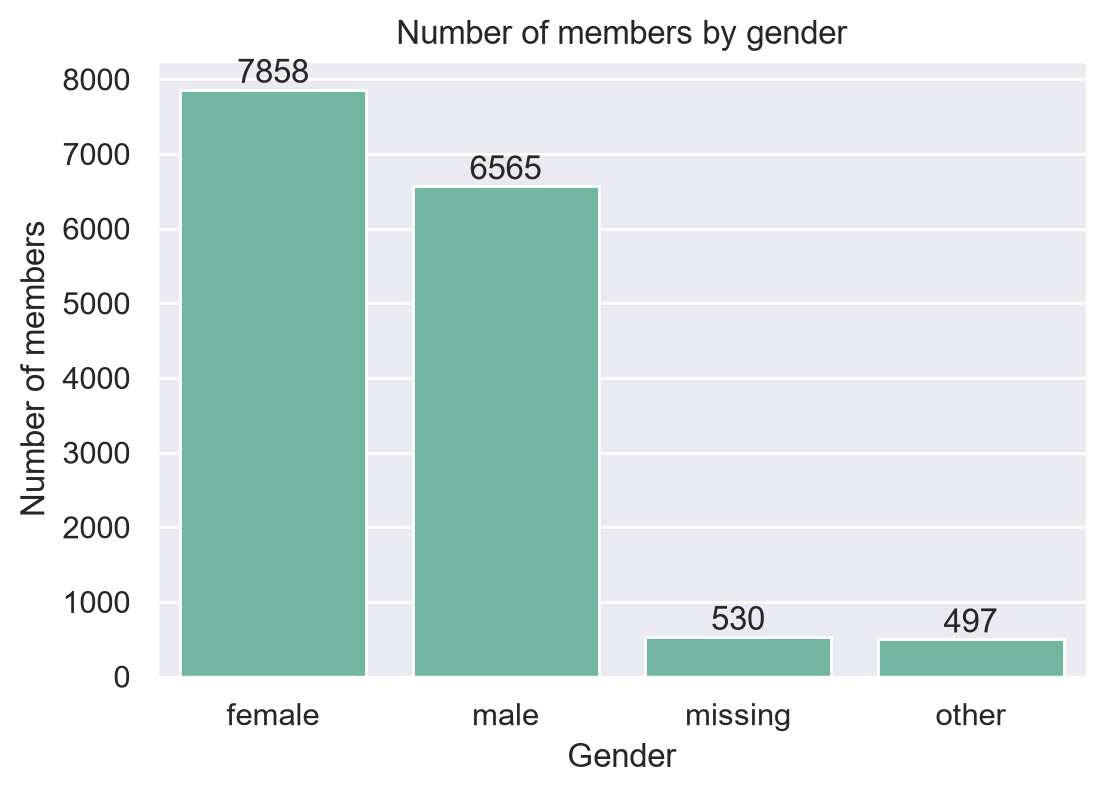

In [29]:
# Count the members of each gender (missing values are labelled "missing" for the plot only)
gender_counts = df["gender"].fillna("missing").value_counts()

# Bar chart
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=gender_counts.index, y=gender_counts.values)
ax.bar_label(ax.containers[0])   # show the number on top of each bar
plt.title("Number of members by gender")
plt.xlabel("Gender")
plt.ylabel("Number of members")
plt.show()

### Gender

`gender` had several spellings of the same category (upper/lower case, extra spaces, abbreviations such as "F" and "M"). 
These were harmonized into three categories: female, male and other. Missing values were kept as NaN.

### Gender distribution

The members are mostly female and male, with similar sizes (roughly half female and 40-45% male). 
"other" and missing values are small groups (about 3% each). 
Because the groups "other" and missing are small, `gender` is unlikely to be a strong variable for the clustering on its own.

In [30]:
df["country"] = df["country"].str.strip().str.lower()

df["country"] = df["country"].replace({
    "portucal": "portugal",
    "pt": "portugal",
    "de": "germany",
    "deutschland": "germany",
    "uk": "united kingdom",
    "gb": "united kingdom",
    "u.k.": "united kingdom",
    "nl": "netherlands",
    "the netherlands": "netherlands",
    "holland": "netherlands",
    "fr": "france",
    "es": "spain",
    "espana": "spain",
    "españa": "spain",
    "ie": "ireland",
})

# Check the result
df["country"].value_counts(dropna=False)

country
portugal          10499
united kingdom     1165
germany             901
spain               741
france              533
netherlands         487
other (europe)      451
NaN                 429
ireland             244
Name: count, dtype: int64

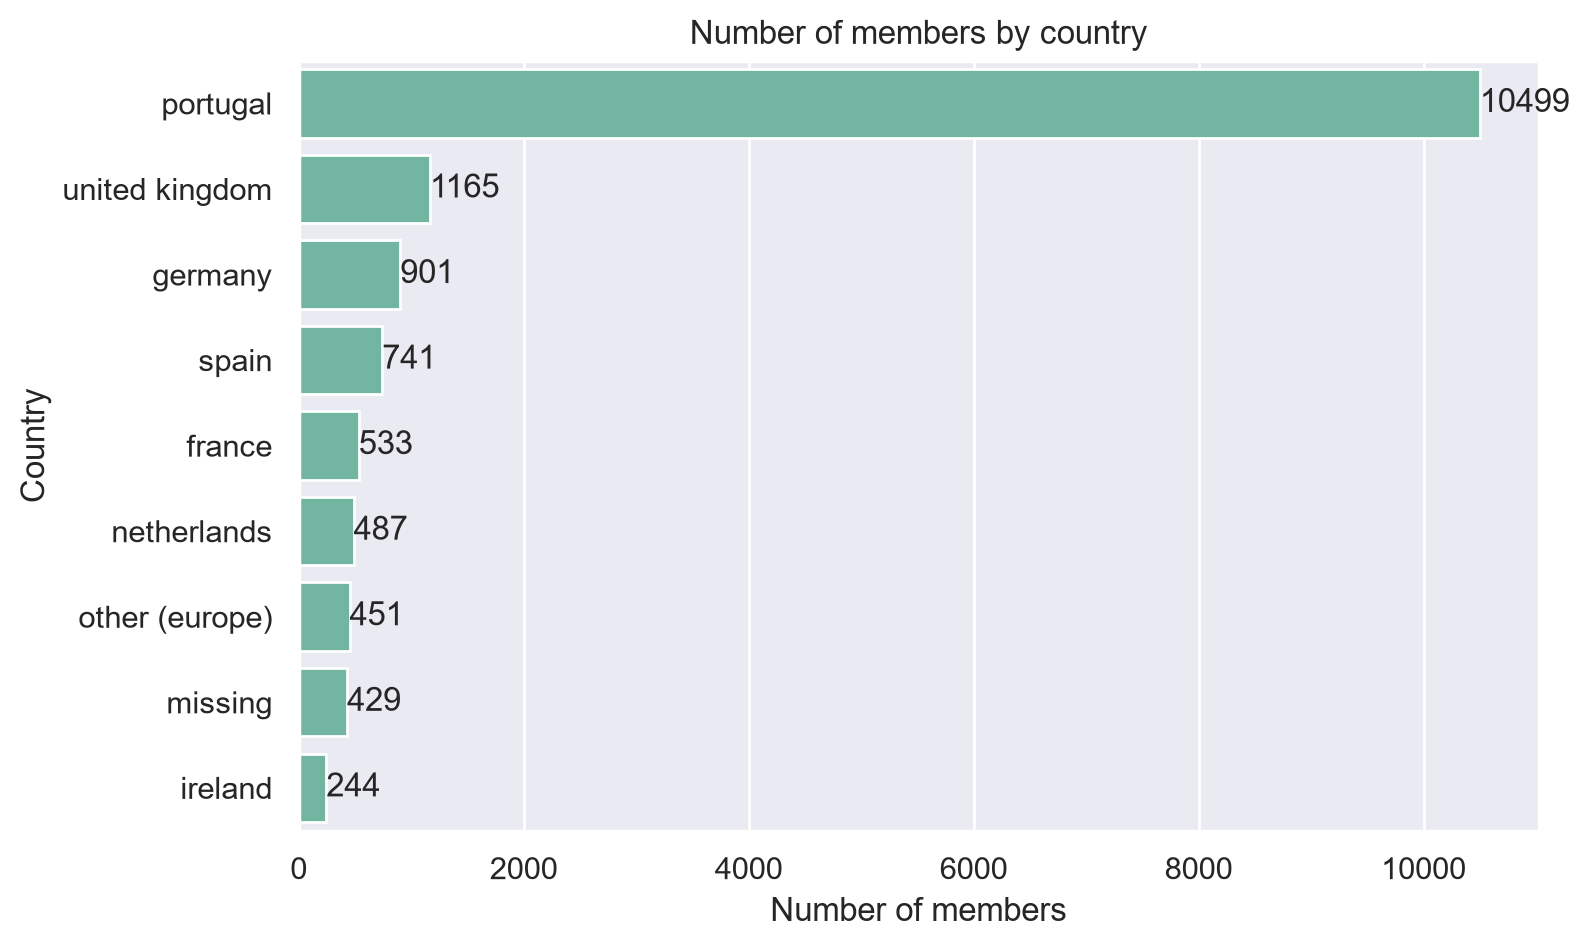

In [31]:
# Count the members of each country (missing values are labelled "missing" for the plot only)
country_counts = df["country"].fillna("missing").value_counts()

# Horizontal bar chart (sorted from the largest to the smallest)
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=country_counts.values, y=country_counts.index)
ax.bar_label(ax.containers[0])   # show the number at the end of each bar
plt.title("Number of members by country")
plt.xlabel("Number of members")
plt.ylabel("Country")
plt.show()

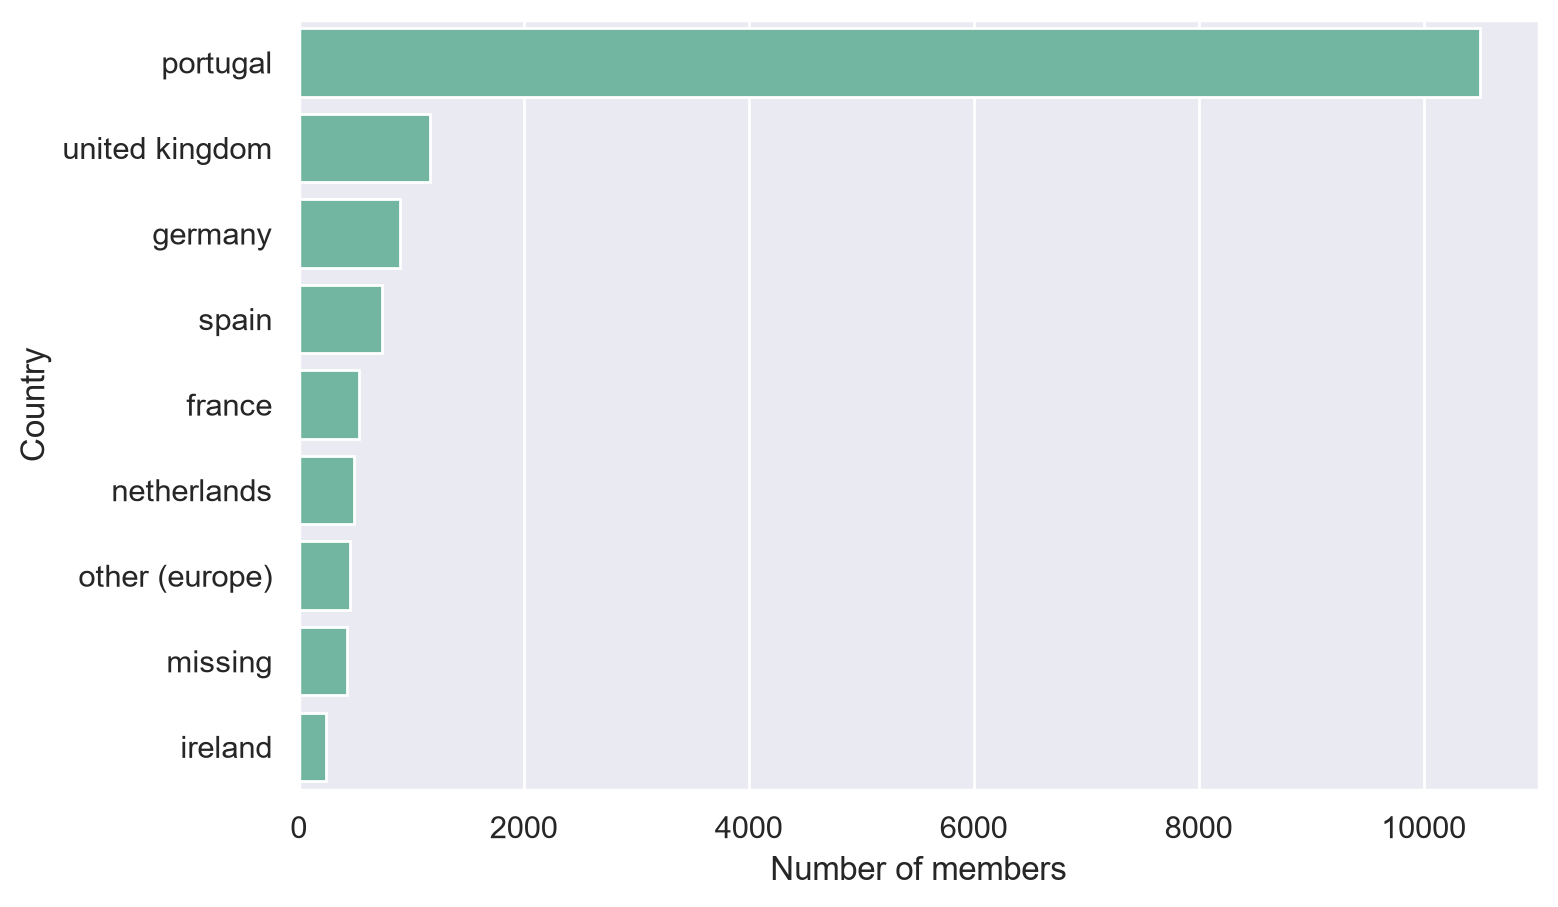

In [32]:
# Count the members of each country 
country_counts = df["country"].fillna("missing").value_counts()

# Calculate percentages
country_percent = country_counts / country_counts.sum() * 100

# Horizontal bar chart (sorted from the largest to the smallest)
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=country_counts.values, y=country_counts.index)

# Show the percentage at the end of each bar
#labels = [f"{p:.1f}%" for p in country_percent.values]
#ax.bar_label(ax.containers[0], labels=labels)

#plt.title("Number of members by country")
plt.xlabel("Number of members")
plt.ylabel("Country")
plt.show()

### Country

`country` had many spellings of the same country (abbreviations such as "pt" or "uk", other languages such as "deutschland" or "espana", 
and a spelling mistake "portucal"). They were harmonized into 8 categories: portugal, united kingdom, germany, spain, france, 
netherlands, ireland and other (europe). Missing values were kept as NaN.


### Country distribution

Portugal represents the large majority of the members, while the other countries are small groups. 
"other (europe)" is a catch-all category and "missing" corresponds to unknown countries. 
This strong imbalance means that `country` may add little information to the clustering unless the small countries are grouped together.

In [33]:
# Clean and standardize plan_tier values
df["plan_tier"] = df["plan_tier"].str.strip().str.lower()

df["plan_tier"] = df["plan_tier"].replace({
    "flex": "flex",
    
    "hot_desk": "hot_desk",
    "hot desk": "hot_desk",
    "hotdesk": "hot_desk",
    
    "full_time": "full_time",
    "full time": "full_time",
    "fulltime": "full_time",
    
    "dedicated_desk": "dedicated_desk",
    "dedicated desk": "dedicated_desk",
    "dedicateddesk": "dedicated_desk",
    
    "private_office": "private_office",
    "private office": "private_office",
    "privateoffice": "private_office",
})

df["plan_tier"].value_counts(dropna=False)

plan_tier
flex              5449
hot_desk          5212
full_time         2471
dedicated_desk    1549
private_office     664
NaN                105
Name: count, dtype: int64

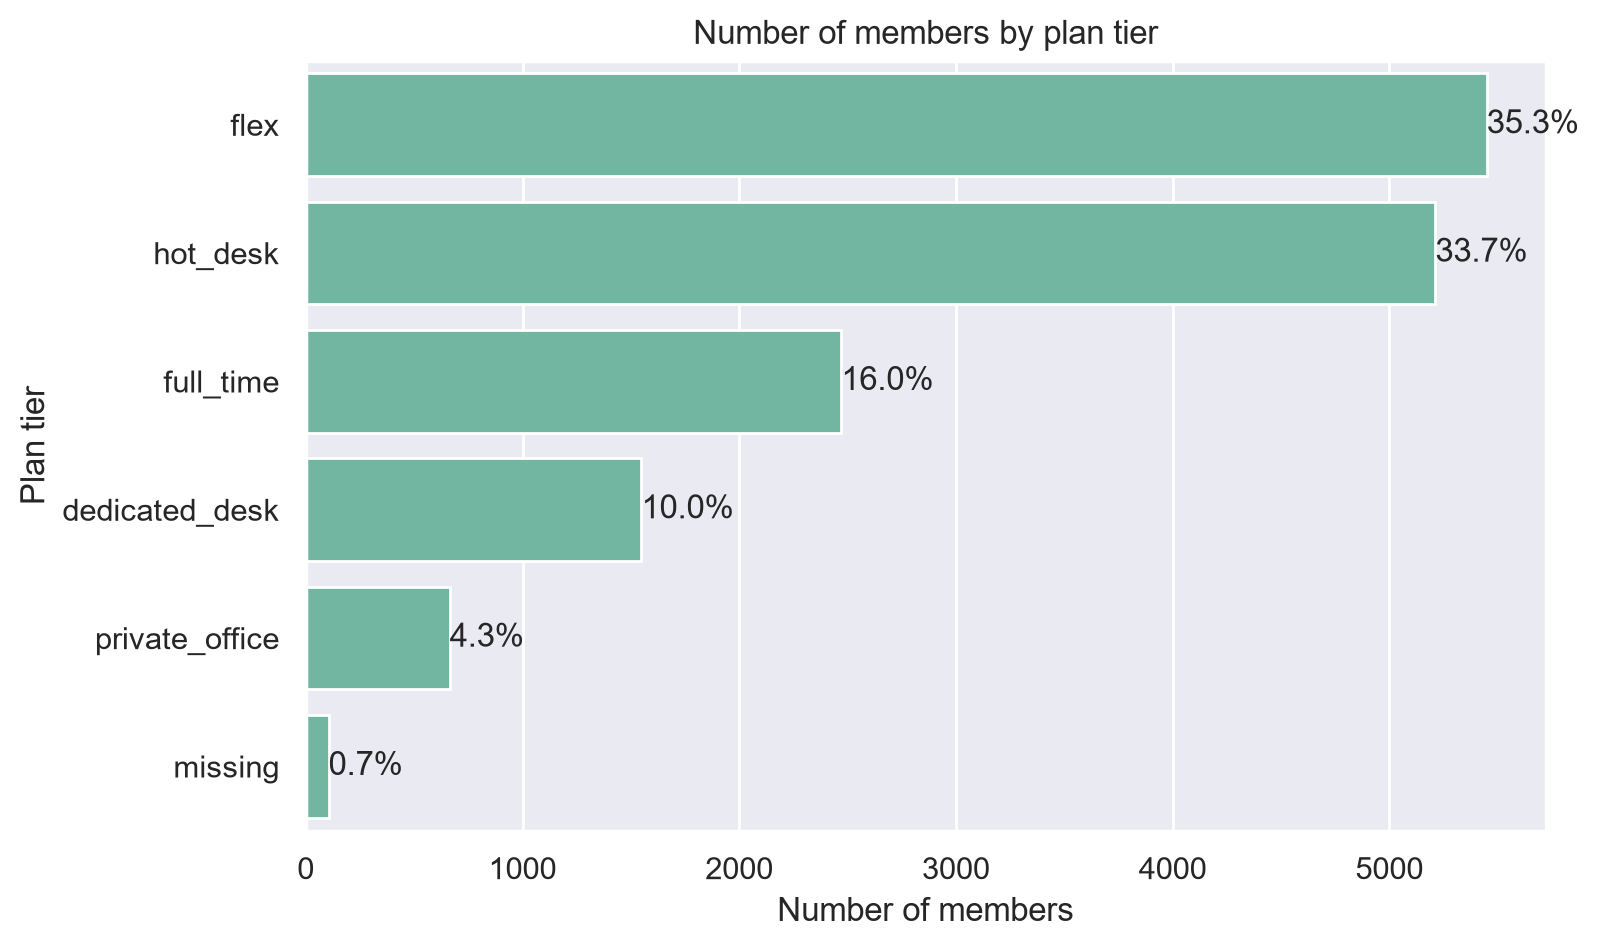

In [34]:
# Count the members of each plan tier
plan_counts = df["plan_tier"].fillna("missing").value_counts()

# Calculate percentages
plan_percent = plan_counts / plan_counts.sum() * 100

# Horizontal bar chart 
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=plan_counts.values, y=plan_counts.index)

# Show the percentage at the end of each bar
labels = [f"{p:.1f}%" for p in plan_percent.values]
ax.bar_label(ax.containers[0], labels=labels)

# White background and no grid
#ax.set_facecolor("white")
#plt.gcf().set_facecolor("white")
#ax.grid(False)

plt.title("Number of members by plan tier")
plt.xlabel("Number of members")
plt.ylabel("Plan tier")
plt.show()

### Plan tier

`plan_tier` had several spellings of the same plan (for example "hot desk", "hotdesk" and "hot_desk"). They were harmonized into five categories: hot_desk, flex, dedicated_desk, full_time and private_office. Missing values were kept as NaN.

### Plan tier distribution

The two lightest plans dominate: flex (35.3%) and hot_desk (33.7%) together represent about 69% of the members. full_time (16.0%) and dedicated_desk (10.0%) follow, and private_office is the smallest group (4.3%). About 0.7% of the members have no plan tier.
The distribution is therefore strongly unbalanced towards flexible plans. A clustering could be dominated by them, while the small private_office group, which has the highest median lifetime value (see the lifetime_value conclusion below), could be hidden.
`plan_tier` is still likely to be a key variable for segmentation, because it describes how much and how the member uses the space.


In [35]:
# Clean and standardize industry values
df["industry"] = df["industry"].str.strip().str.lower()

df["industry"] = df["industry"].replace({
    "information technology": "information technology",
    "it": "information technology",
    "tech": "information technology",

    "consulting": "consulting",

    "marketing & pr": "marketing & pr",
    "marketing/pr": "marketing & pr",
    "marketing and pr": "marketing & pr",

    "design & creative": "design & creative",
    "design/creative": "design & creative",
    "design and creative": "design & creative",

    "finance": "finance",

    "other": "other",

    "legal": "legal",

    "education": "education",

    "unknown": "unknown",

    "health": "health",

    "real estate": "real estate",
    "realestate": "real estate",
    "real-estate": "real estate",
})

# Check the result
df["industry"].value_counts(dropna=False)

industry
information technology    3557
consulting                2055
design & creative         1974
marketing & pr            1962
finance                   1219
other                     1175
legal                      878
education                  775
unknown                    693
health                     601
real estate                561
Name: count, dtype: int64

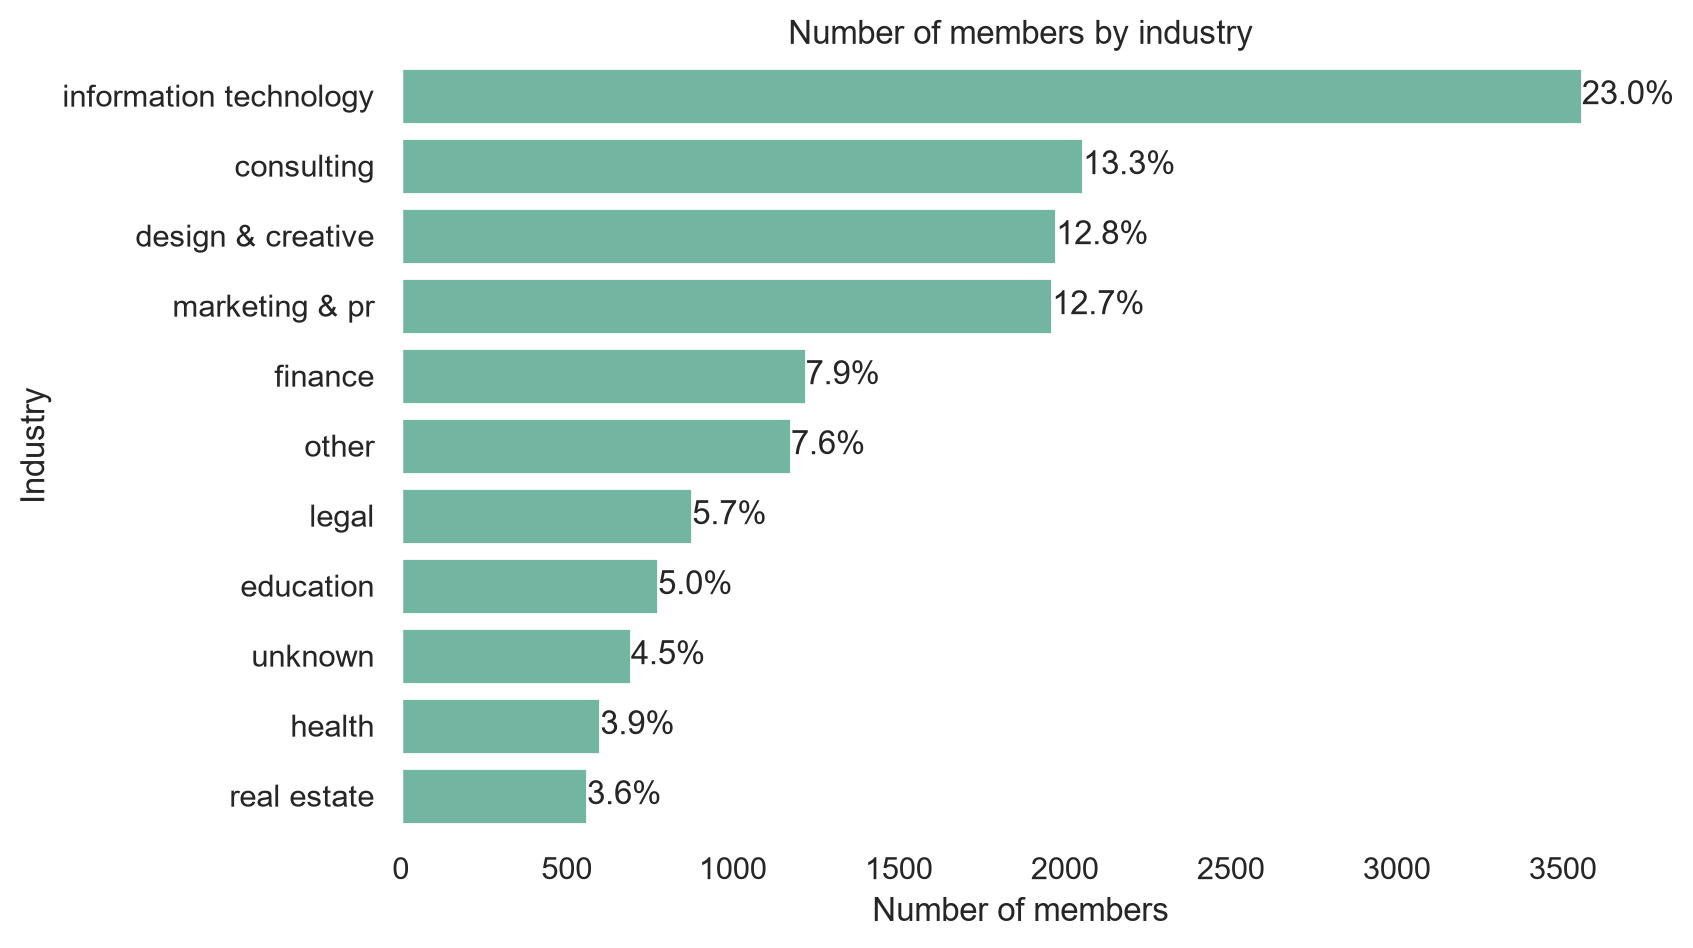

In [36]:
# Count the members of each industry
industry_counts = df["industry"].fillna("missing").value_counts()

# Calculate percentages
industry_percent = industry_counts / industry_counts.sum() * 100

# Horizontal bar chart (sorted from the largest to the smallest)
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=industry_counts.values, y=industry_counts.index)

# Show the percentage at the end of each bar
labels = [f"{p:.1f}%" for p in industry_percent.values]
ax.bar_label(ax.containers[0], labels=labels)

# White background and no grid
ax.set_facecolor("white")
plt.gcf().set_facecolor("white")
ax.grid(False)

plt.title("Number of members by industry")
plt.xlabel("Number of members")
plt.ylabel("Industry")
plt.show()

### Industry

`industry` had several spellings of the same sector (for example "it" and "tech" for information technology, "marketing/pr", "real-estate"). They were harmonized into 11 categories.

### Industry distribution

Information technology is the largest industry (23.0%), followed by consulting (13.3%), design & creative (12.8%) and marketing & pr (12.7%). All other sectors are below 8%.
"other" (7.6%) is a catch-all category and "unknown" (4.5%) is a hidden missing value, so about 12% of the members have no usable industry. There's no "missing" bar in the chart, so the missing information is only hidden in "unknown".
With 11 categories, several of them small, `industry` is unlikely to be useful as it's for building segments. It may be better used afterwards to describe the segments, or after grouping similar sectors.

## 6. Impossible values

We check for values that cannot be true (for example negative counts or ages that aren't realistic). 
These are data errors, different from outliers (extreme but possible values).

In [37]:
# Numeric columns that can never be negative (counts, hours, days)
count_cols = ["n_colleagues_on_account", "days_since_last_visit", "total_visits",
              "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
              "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals"]

# Number of negative values in each column
(df[count_cols] < 0).sum()

n_colleagues_on_account        565
days_since_last_visit           56
total_visits                    42
avg_weekly_visits                0
entitled_visits_last_period      0
actual_visits_last_period        0
meeting_room_hours              16
event_space_hours                8
guest_passes_issued              7
n_renewals                      66
dtype: int64

In [38]:
# Range of the age
print(df["age"].min(), df["age"].max())

# Number of members younger than 16 and older than 90
print((df["age"] < 16).sum())
print((df["age"] > 90).sum())

1.0 149.0
98
49


In [39]:
# A week has 7 days: count the values above 7 and equal to 0
print((df["plan_days_per_week"] > 7).sum())
print((df["plan_days_per_week"] == 0).sum())

54
43


In [40]:
# Number of members per year for each date column
for col in ["membership_start", "membership_end", "last_badge_swipe"]:
    print(col)
    print(df[col].dt.year.value_counts().sort_index())
    print()

membership_start
membership_start
2021    7626
2022    4449
2023    3375
Name: count, dtype: int64

membership_end
membership_end
1970    3954
2020      15
2021    1677
2022    3658
2023    6071
2024      75
Name: count, dtype: int64

last_badge_swipe
last_badge_swipe
2020      14
2021    1865
2022    3705
2023    9821
2024      45
Name: count, dtype: int64



In [41]:
# Which exact dates are found in the year 1970?
df.loc[df["membership_end"].dt.year == 1970, "membership_end"].value_counts()

membership_end
1970-01-01    3954
Name: count, dtype: int64

In [42]:
# Placeholder date in membership_end
is_placeholder = df["membership_end"] == pd.Timestamp("1970-01-01")
print("Members with the placeholder date 1970-01-01:", is_placeholder.sum(),
      f"({is_placeholder.mean() * 100:.1f}%)")

# Among the real end dates (placeholder excluded)
real_end = df[~is_placeholder]
print("End date before start date:", (real_end["membership_end"] < real_end["membership_start"]).sum())
print("Last badge swipe after end date:", (real_end["last_badge_swipe"] > real_end["membership_end"]).sum())

# End dates before the first membership of the company
print("End date before the first membership start:",
      (df["membership_end"] < df["membership_start"].min()).sum())

Members with the placeholder date 1970-01-01: 3954 (25.6%)
End date before start date: 152
Last badge swipe after end date: 213
End date before the first membership start: 3969


### Suspicious year in membership_end

`membership_end` has the year 1970 for 3,954 members (25.6%), although all memberships start between 2021 and 2023. They all have the same date, 1 January 1970, so it looks like a default value used when no end date was recorded (maybe members who are still active, but the data doesn't confirm it).

We also found 152 end dates before the start date and 213 members with a badge swipe after their end date. These dates make the membership length and the recency less reliable, so these members should be checked before clustering, not removed automatically.

## 7. Distributions and outliers

We look at the distribution of each numeric variable to understand its shape and to spot extreme values. 
An outlier is an extreme value that isn't necessarily an error: it may be a real, very active or very profitable member.

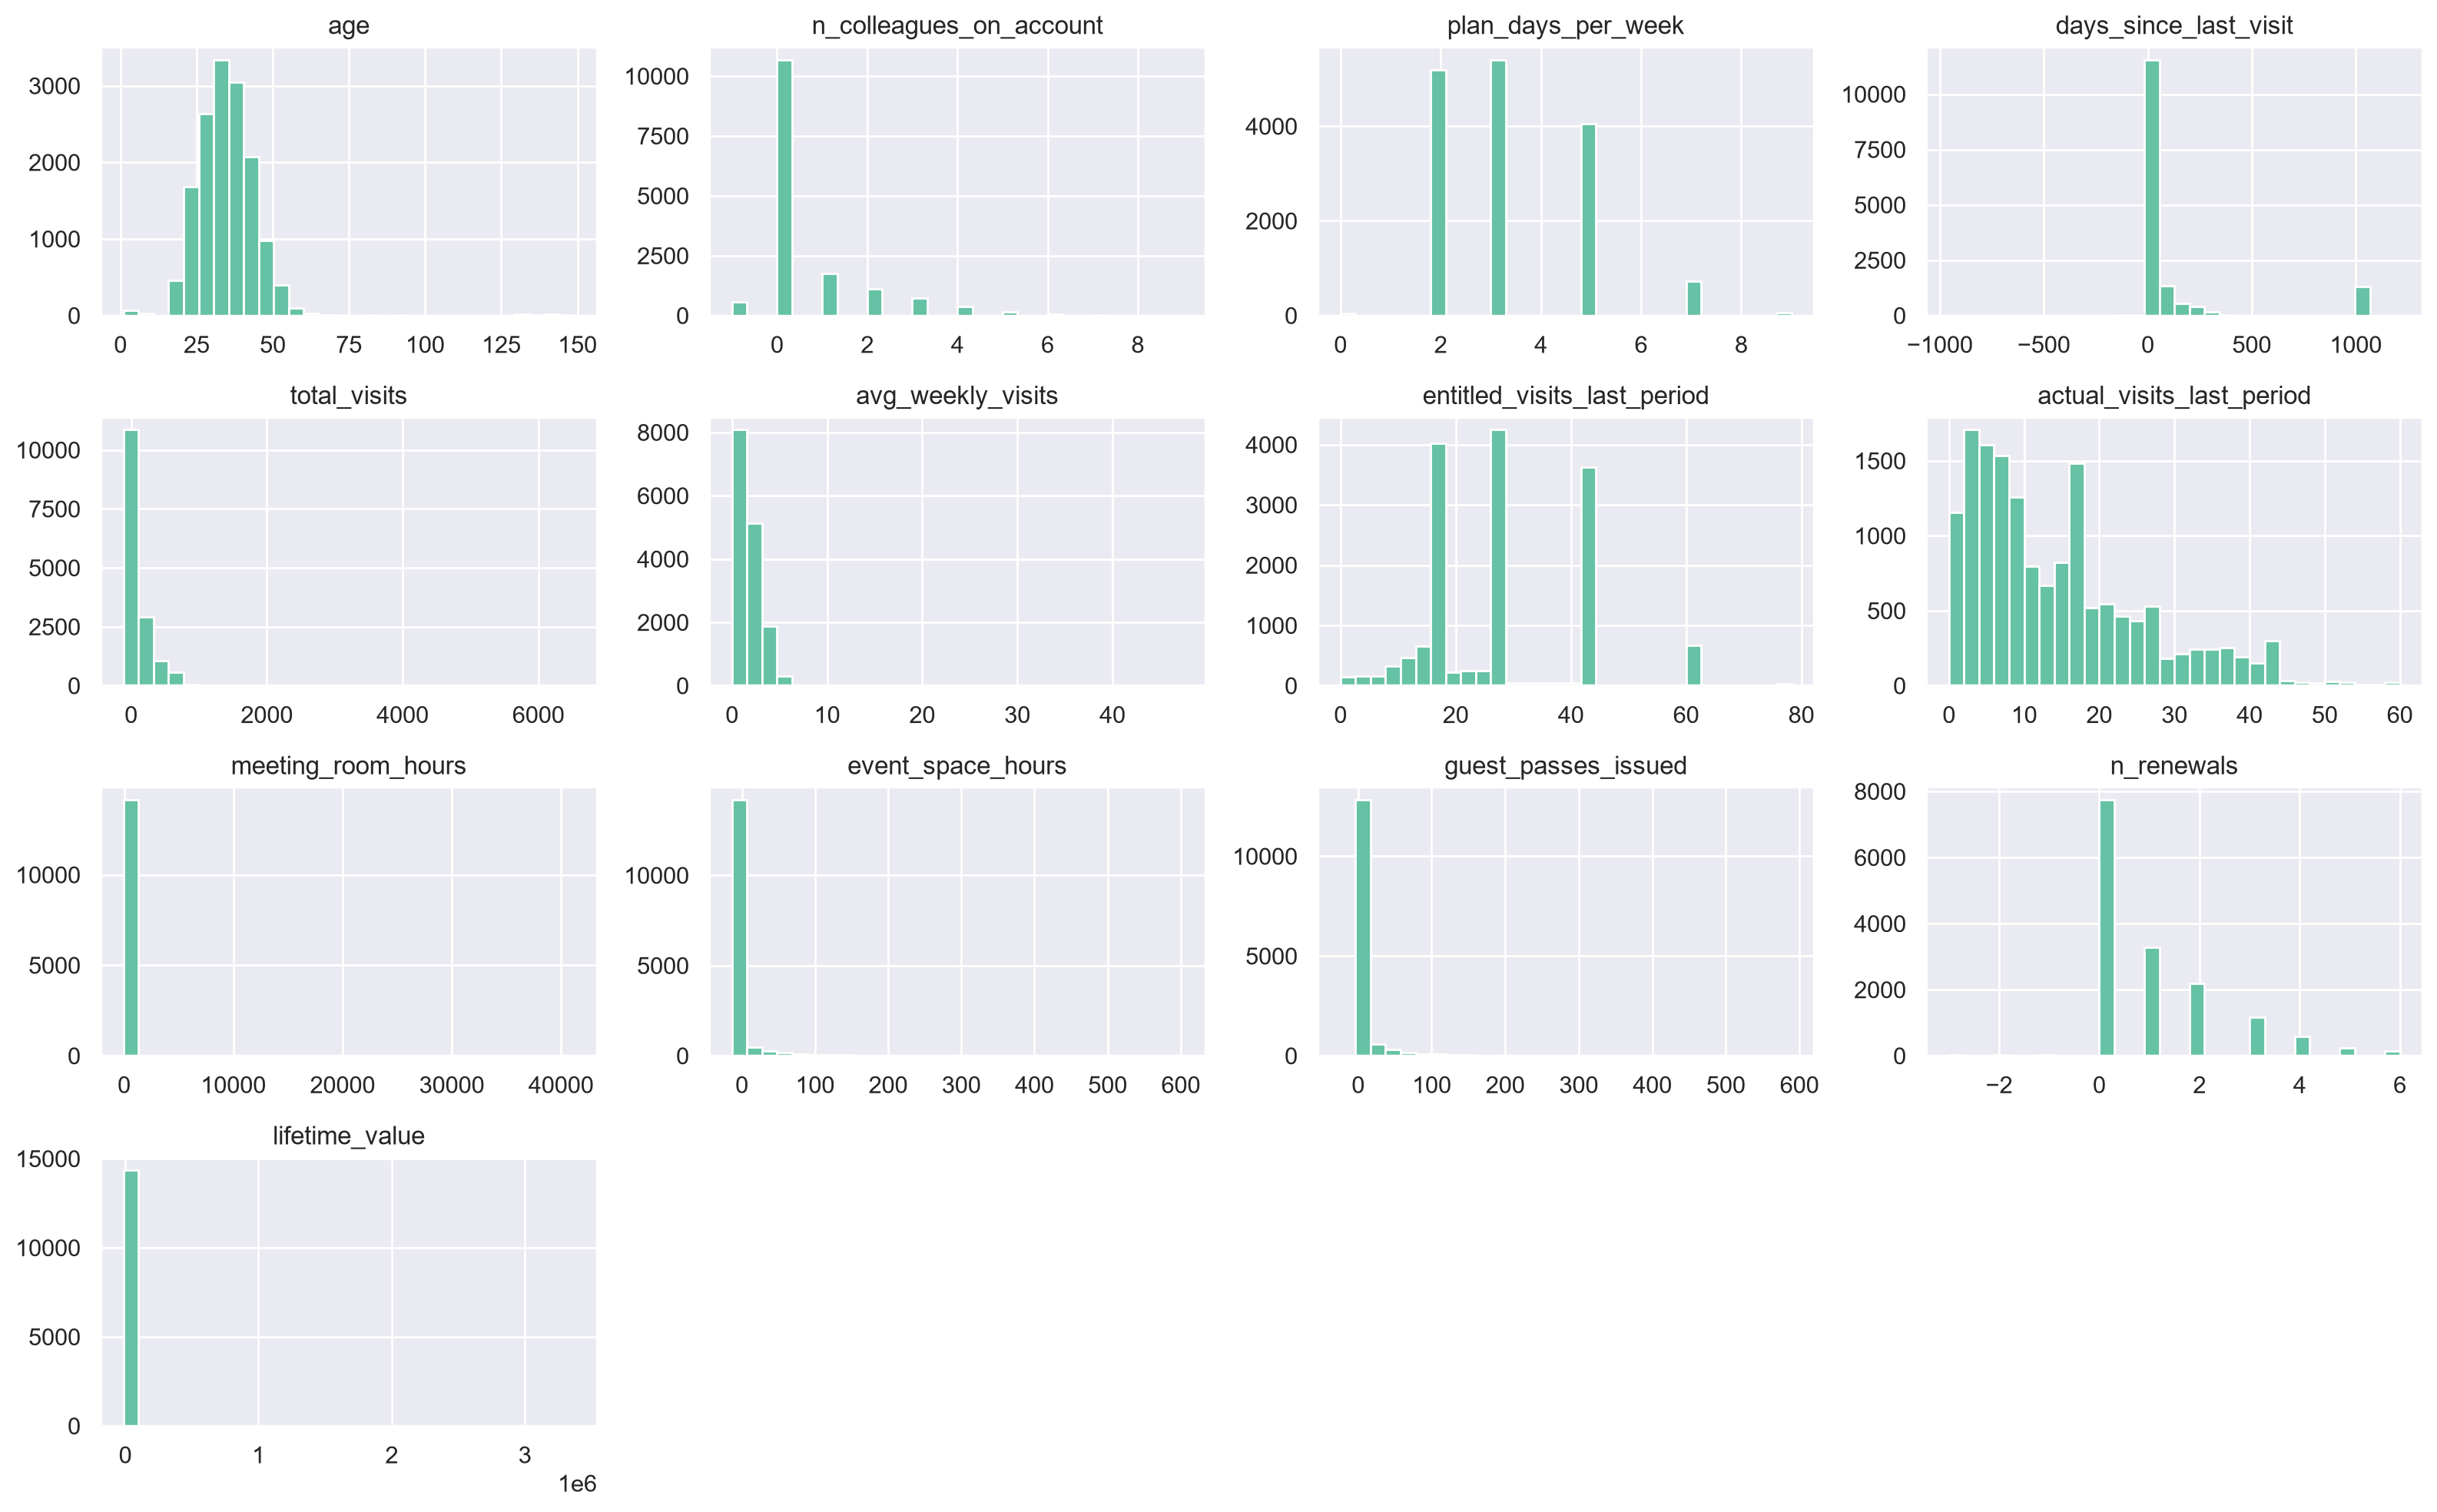

In [43]:
# Numeric variables to analyse (binary variables are excluded)
num_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
            "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
            "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_renewals", "lifetime_value"]

# One histogram per variable
df[num_cols].hist(bins=30, figsize=(16, 10))
plt.tight_layout()
plt.show()

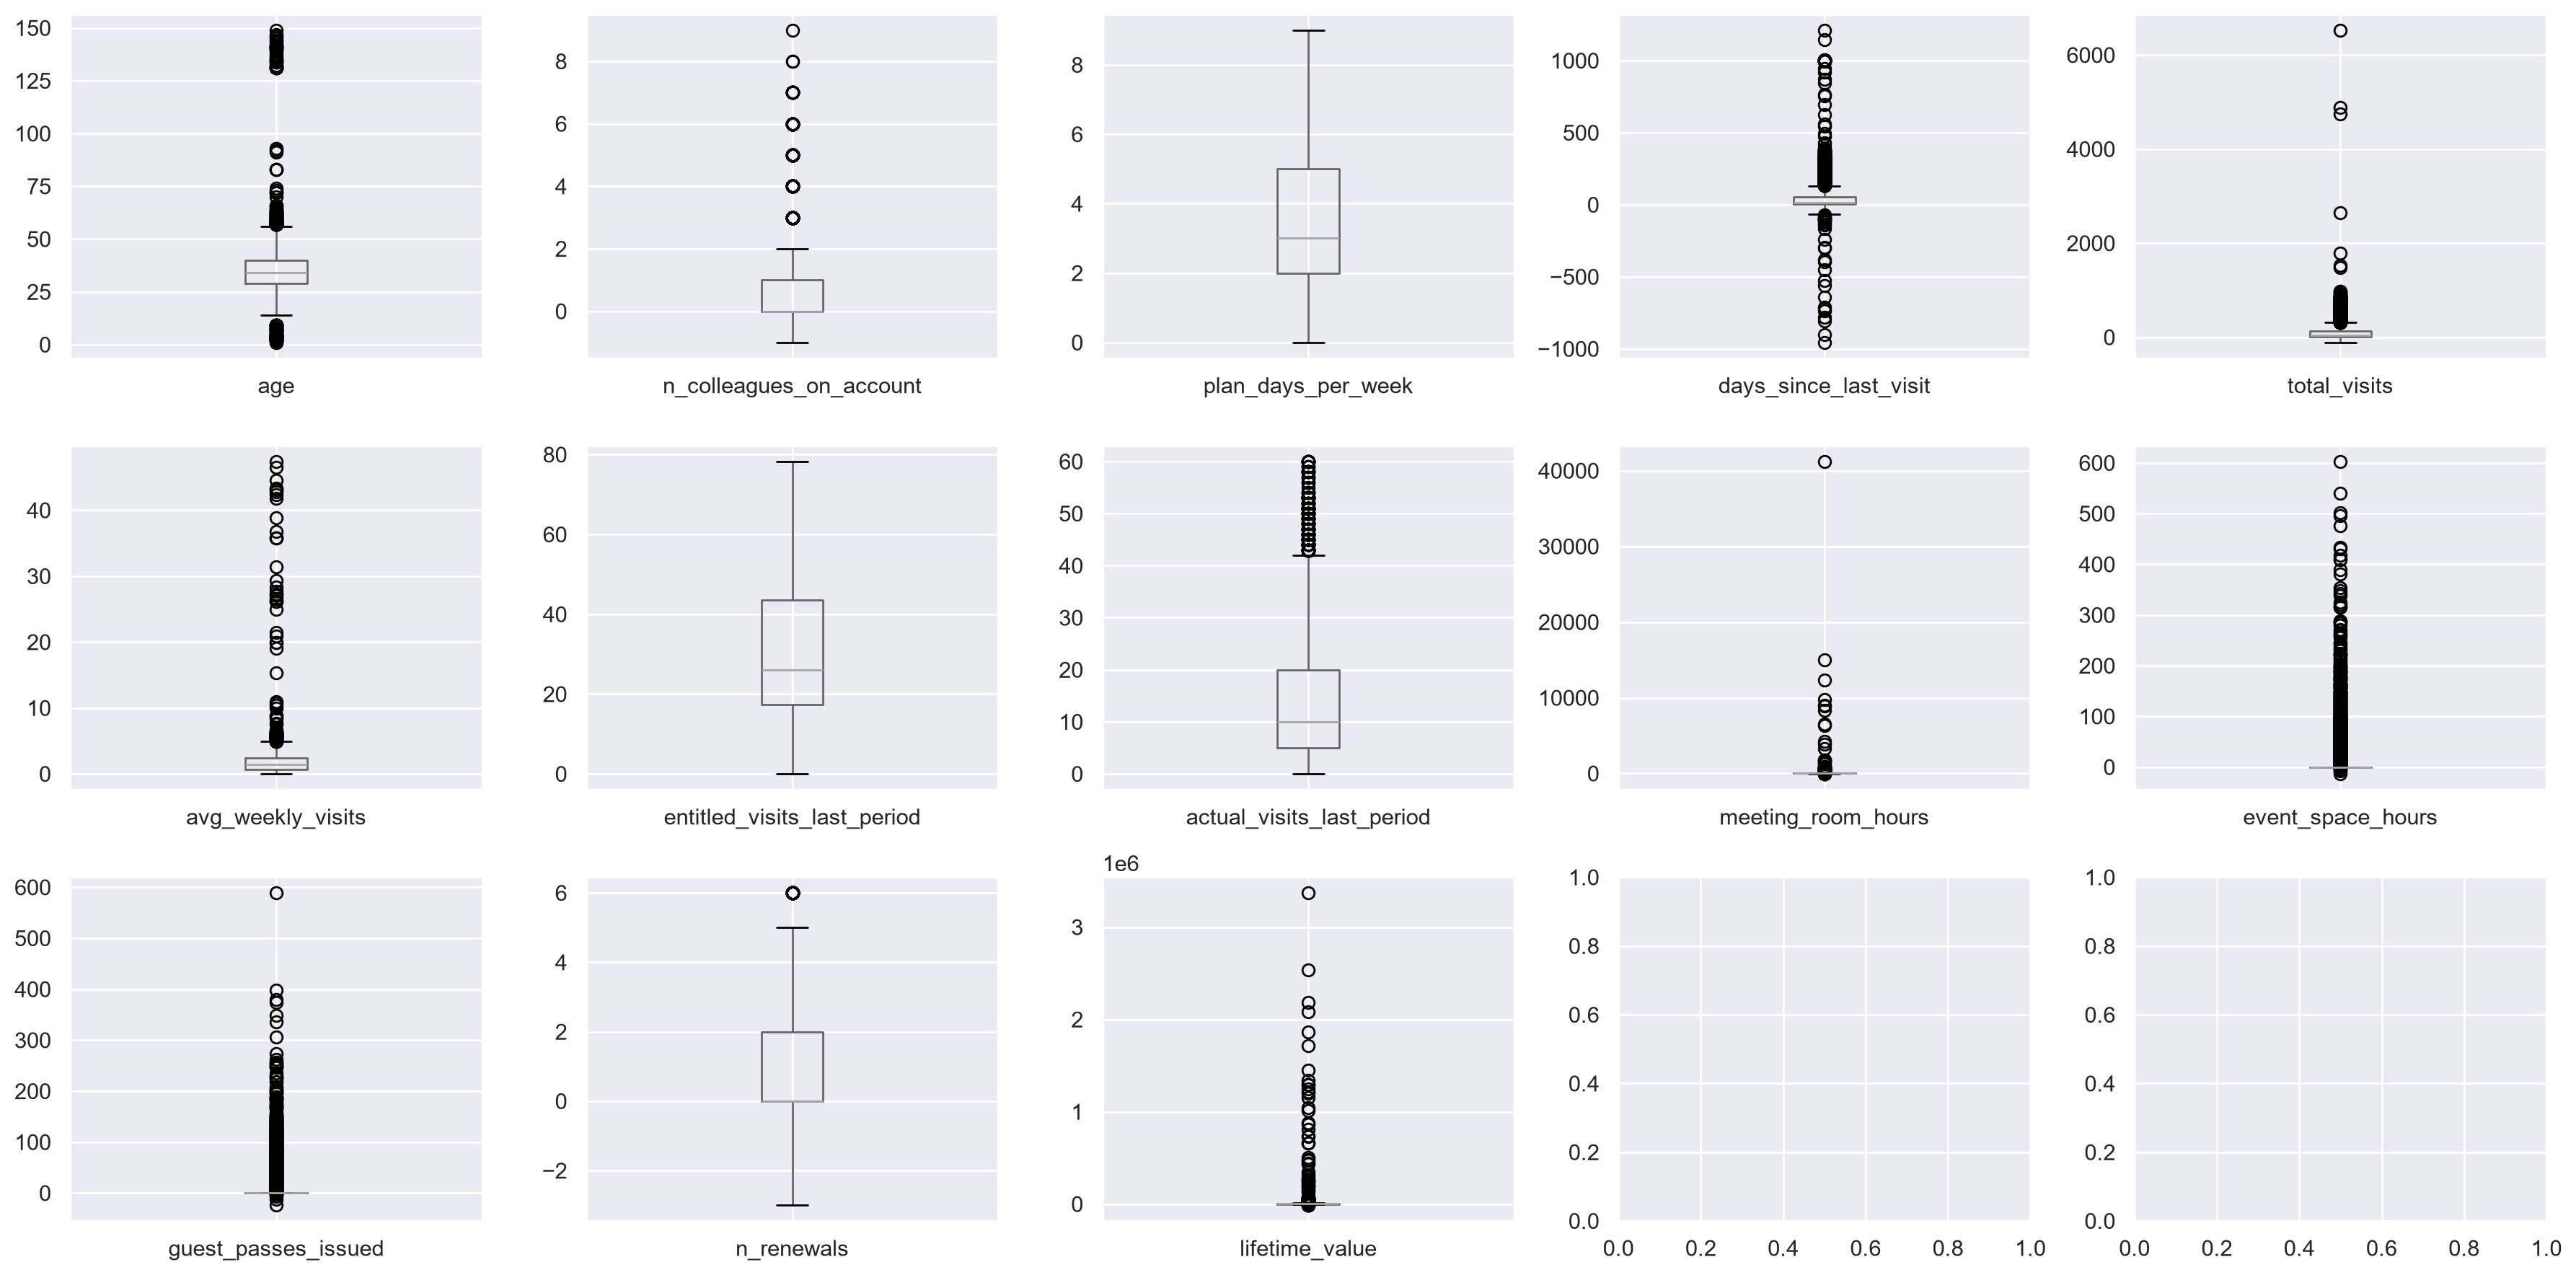

In [44]:
# One boxplot per variable 
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, col in zip(axes.flat, num_cols):
    df.boxplot(column=col, ax=ax)
plt.tight_layout()
plt.show()

In [45]:
# Goal: for each numeric variable, find the values that are "unusually" small or large
# Rule used (IQR rule): a value is an outlier if it is outside the interval
#   [Q1 - 1.5 * IQR ; Q3 + 1.5 * IQR]
# Q1 = value below which 25% of the members are, Q3 = value below which 75% of the members are
# IQR = Q3 - Q1 (the range of the "middle half" of the members)

results = []

for col in num_cols:
    values = df[col].dropna()          # ignore the missing values

    q1 = values.quantile(0.25)         # 1st quartile
    q3 = values.quantile(0.75)         # 3rd quartile
    iqr = q3 - q1                      # interquartile range

    lower = q1 - 1.5 * iqr             # below this limit = unusually small
    upper = q3 + 1.5 * iqr             # above this limit = unusually large

    n_low = (values < lower).sum()     # number of unusually small values
    n_high = (values > upper).sum()    # number of unusually large values
    pct = round((n_low + n_high) / len(values) * 100, 1)   # percentage of outliers

    results.append([col, q1, q3, lower, upper, values.min(), values.max(), n_low, n_high, pct])

# Put the results in a table
outliers_table = pd.DataFrame(results, columns=["variable", "q1", "q3", "lower_limit", "upper_limit",
                                                "min", "max", "n_below", "n_above", "pct_outliers"])
outliers_table.round(1)

,variable,q1,q3,lower_limit,upper_limit,min,max,n_below,n_above,pct_outliers
0,age,29.0,40.0,12.5,56.5,1.0,149.0,97,160,1.7
1,n_colleagues_on_account,0.0,1.0,-1.5,2.5,-1.0,9.0,0,1323,8.6
2,plan_days_per_week,2.0,5.0,-2.5,9.5,0.0,9.0,0,0,0.0
3,days_since_last_visit,4.0,55.0,-72.5,131.5,-956.0,1212.0,31,2471,16.2
4,total_visits,8.0,132.0,-178.0,318.0,-112.0,6530.0,0,1730,11.2
5,avg_weekly_visits,0.7,2.4,-1.8,5.0,0.0,47.4,0,312,2.0
6,entitled_visits_last_period,17.4,43.5,-21.7,82.6,0.0,78.3,0,0,0.0
7,actual_visits_last_period,5.0,20.0,-17.5,42.5,0.0,60.0,0,380,2.5
8,meeting_room_hours,0.0,7.2,-10.8,18.0,-56.6,41220.0,6,2938,20.8
9,event_space_hours,0.0,0.0,0.0,0.0,-13.5,602.8,8,1759,11.4


### Outliers (IQR rule)

We use the IQR rule from the labs: a value is an outlier if it's outside [Q1 - 1.5 × IQR ; Q3 + 1.5 × IQR], the same limits the boxplots use. The rule is based on quartiles, so a few extreme values don't move the limits much.

A value outside the limits isn't always an error (some members really use the space much more than others), so here we only flag the outliers and don't remove them.

In [46]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
print("Numerical Descriptive Statistics:")
df.describe().T

Numerical Descriptive Statistics:


,count,mean,min,25%,50%,75%,max,std
age,14893.00,34.86,1.00,29.00,34.00,40.00,149.00,10.40
n_colleagues_on_account,15450.00,0.54,-1.00,0.00,0.00,1.00,9.00,1.18
plan_days_per_week,15450.00,3.39,0.00,2.00,3.00,5.00,9.00,1.46
membership_start,15450,2022-03-15 18:14:12.815534,2021-01-01 00:00:00,2021-06-02 00:00:00,2022-01-06 00:00:00,2022-11-03 00:00:00,2023-12-30 00:00:00,NaN
membership_end,15450,2009-05-25 17:09:15.029126,1970-01-01 00:00:00,1970-01-01 00:00:00,2022-08-21 00:00:00,2023-06-09 00:00:00,2024-01-01 00:00:00,NaN
last_badge_swipe,15450,2023-02-13 20:05:41.126213,2020-09-06 00:00:00,2022-08-11 00:00:00,2023-05-06 00:00:00,2023-10-17 00:00:00,2024-04-28 00:00:00,NaN
days_since_last_visit,15450.00,117.19,-956.00,4.00,13.00,55.00,1212.00,275.64
total_visits,15450.00,110.39,-112.00,8.00,34.00,132.00,6530.00,182.94
avg_weekly_visits,15450.00,1.78,0.00,0.71,1.42,2.41,47.40,1.94
entitled_visits_last_period,15450.00,27.51,0.00,17.39,26.09,43.48,78.27,13.48


In [47]:
print("Categorical Descriptive Statistics:")
df.describe(include=["object", "string"])

Categorical Descriptive Statistics:


,member_id,gender,industry,country,plan_tier
count,15450,14920,15450,15021,15345
unique,15450,3,11,8,5
top,CW000001,female,information technology,portugal,flex
freq,1,7858,3557,10499,5449


In [48]:
numerical_columns = df.select_dtypes(include=[np.number]).columns
df_num = df[numerical_columns]
results = pd.DataFrame(index=df_num.columns)

results['Mean'] = df_num.mean()

results['Median'] = df_num.median()

results['Mode'] = df_num.mode().iloc[0]

pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.max_columns', None)
print("Table:")
print(results)

Table:
                               Mean  Median   Mode
age                           34.86   34.00  34.00
n_colleagues_on_account        0.54    0.00   0.00
plan_days_per_week             3.39    3.00   3.00
days_since_last_visit        117.19   13.00 999.00
total_visits                 110.39   34.00   5.00
avg_weekly_visits              1.78    1.42   2.70
entitled_visits_last_period   27.51   26.09  26.09
actual_visits_last_period     13.80   10.00  17.00
meeting_room_hours            33.09    0.00   0.00
event_space_hours              5.12    0.00   0.00
guest_passes_issued            6.16    0.00   0.00
n_renewals                     1.01    0.00   0.00
lifetime_value              6398.77  825.12   0.00


In [49]:
results1 = pd.DataFrame(index=df_num.columns)
results1['Range (Max-Min)'] = df_num.max() - df_num.min()

results1['Skew'] = df_num.skew()

results1['Skew type'] = results1['Skew'].apply(classificar_simetria)

pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.max_columns', None)
print("Table:")
print(results1)

Table:
                             Range (Max-Min)  Skew                Skew type
age                                   148.00  3.03      Highly assymetrical
n_colleagues_on_account                10.00  2.12      Highly assymetrical
plan_days_per_week                      9.00  0.93  Moderately assymetrical
days_since_last_visit                2168.00  2.72      Highly assymetrical
total_visits                         6642.00  6.82      Highly assymetrical
avg_weekly_visits                      47.40 10.27      Highly assymetrical
entitled_visits_last_period            78.27  0.73  Moderately assymetrical
actual_visits_last_period              60.00  1.06      Highly assymetrical
meeting_room_hours                  41276.60 70.80      Highly assymetrical
event_space_hours                     616.30  9.22      Highly assymetrical
guest_passes_issued                   613.00  7.01      Highly assymetrical
n_renewals                              9.00  1.34      Highly assymetrical
lifet

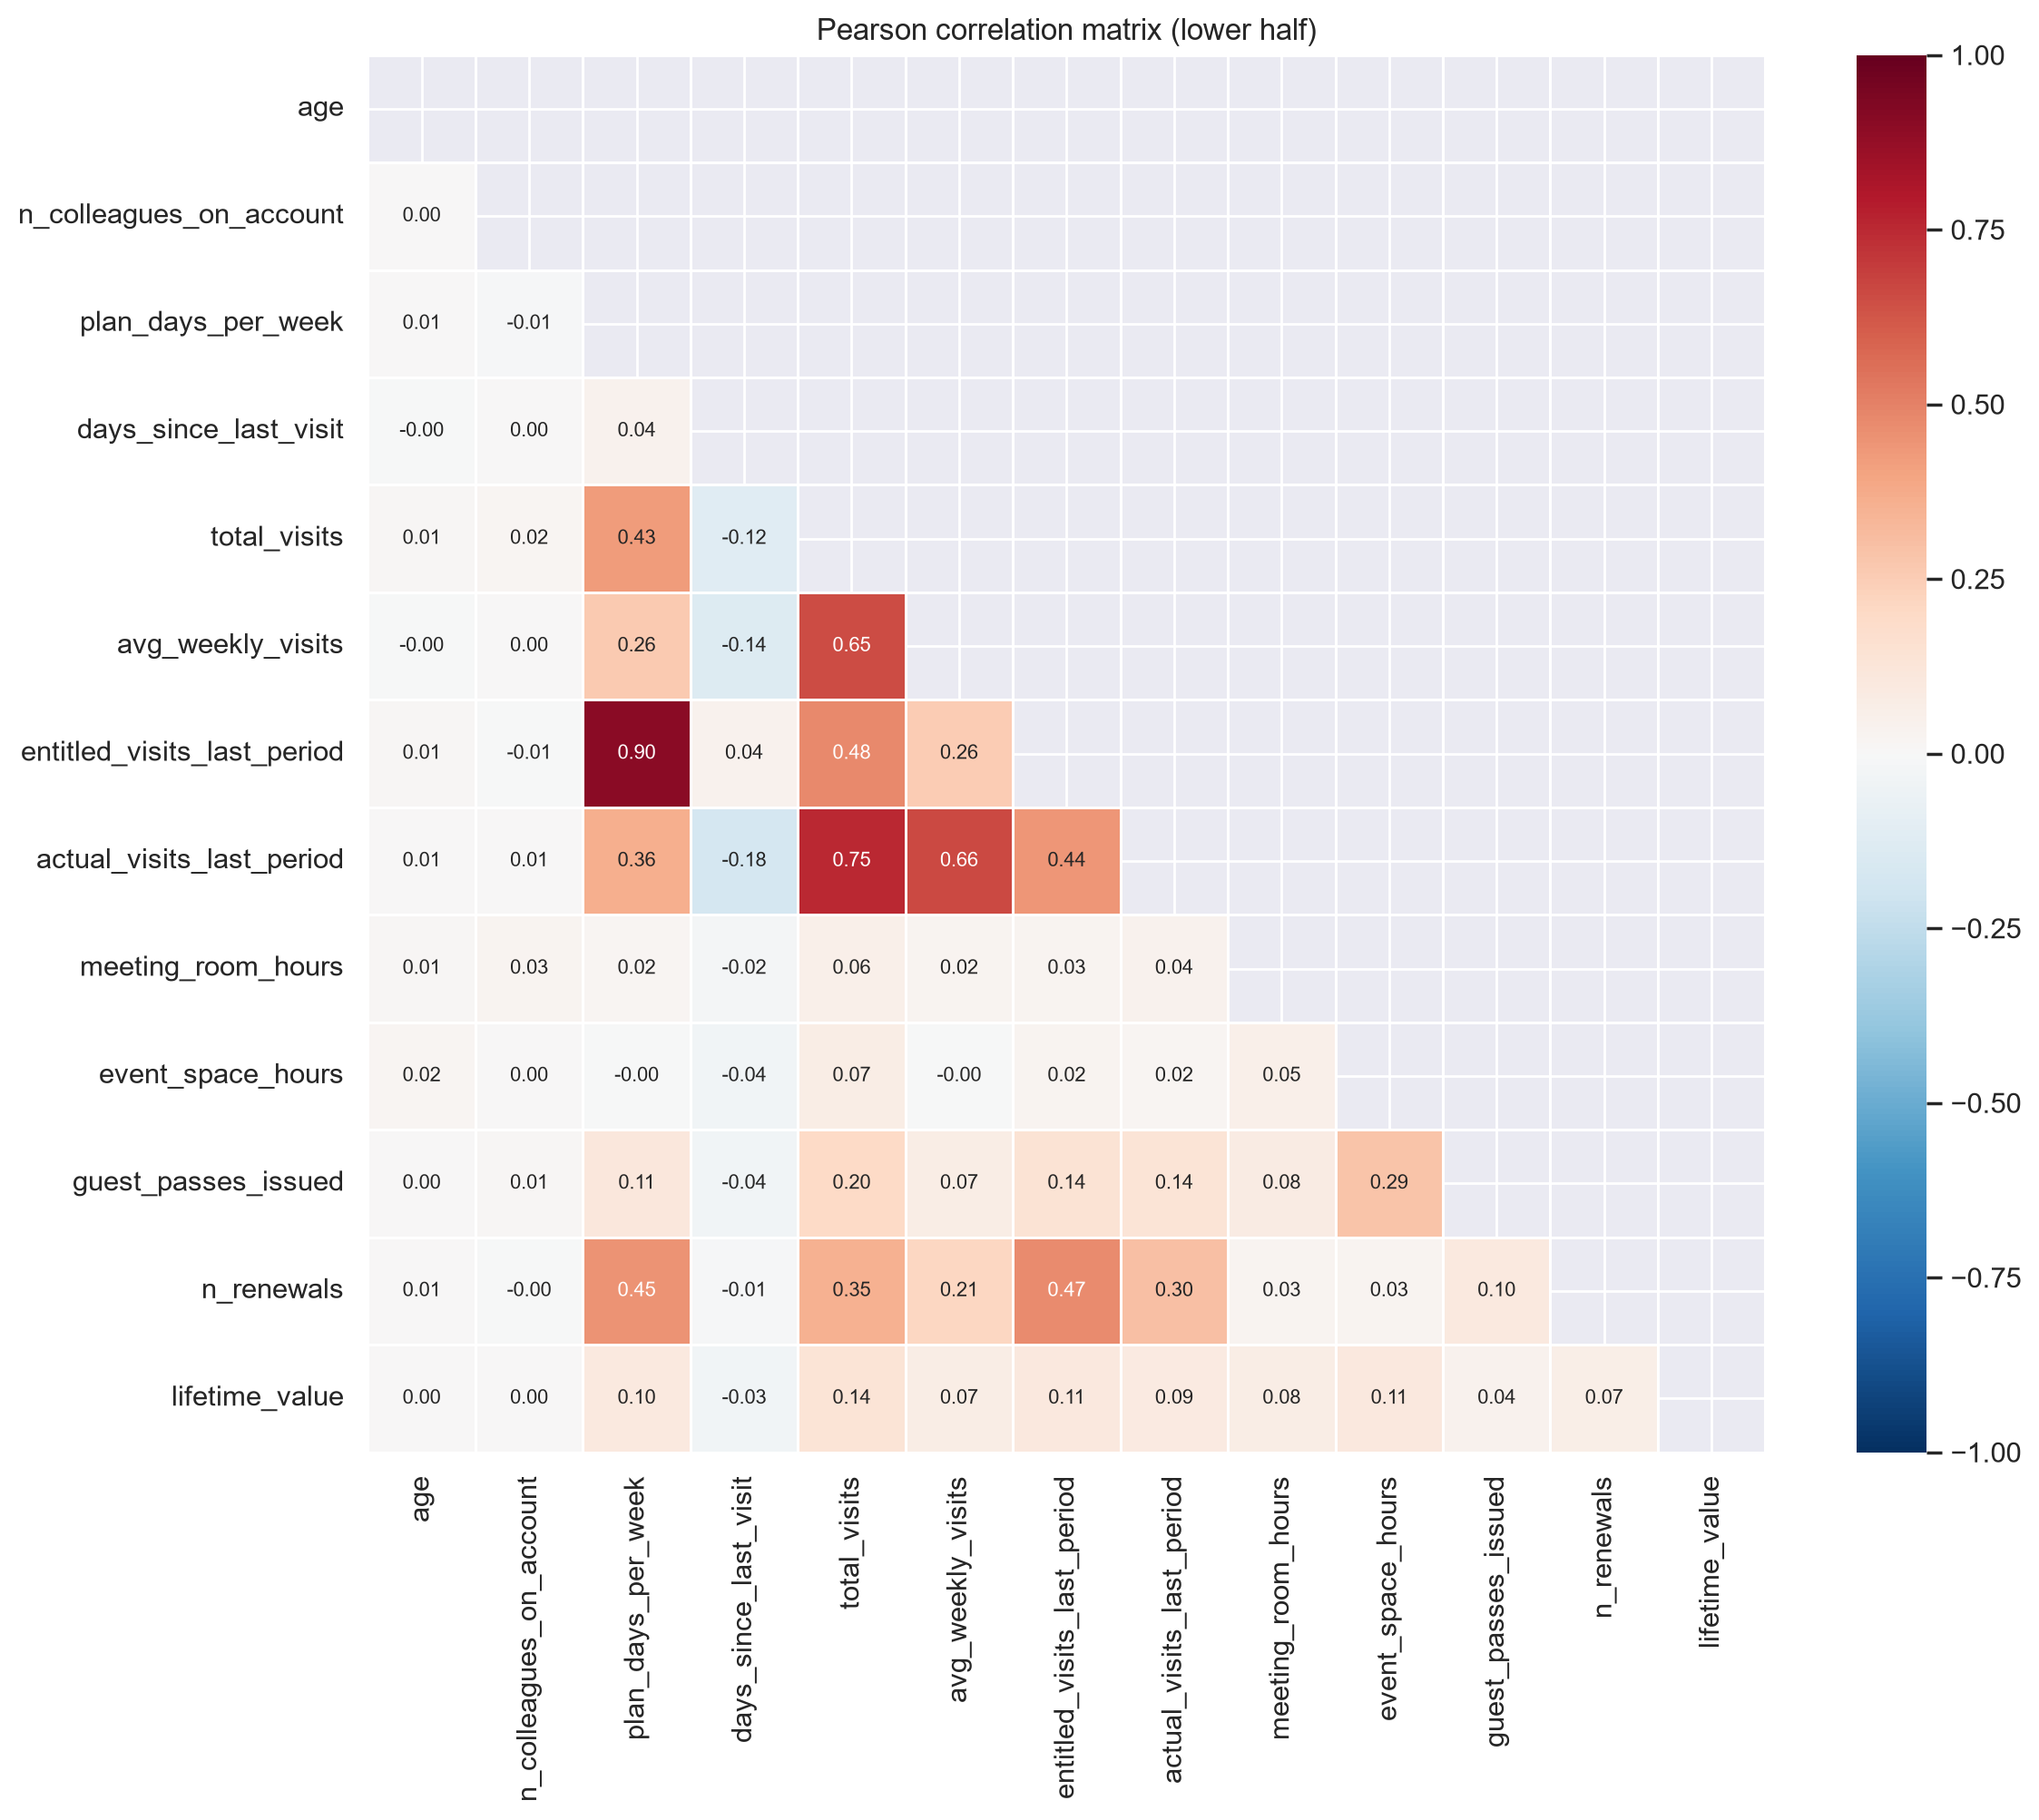

In [50]:
# Pearson correlation between the numeric variables (computed on df as it is, errors included)
corr_pearson = df[num_cols].corr()

# Lower half only, with the numbers (the matrix is symmetric, the upper half repeats the same values)
mask_lower = np.triu(np.ones_like(corr_pearson, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(corr_pearson, mask=mask_lower, annot=True, annot_kws={"size": 8}, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5)
plt.title("Pearson correlation matrix (lower half)")
plt.show()

### Age

The IQR rule flags ages above 56.5 and below 12.5 as outliers. However, an age of 57 isn't unrealistic: 
111 members are between 57 and 90 years old (median 59), which is plausible for a coworking space. 
For this variable, the IQR rule is too strict, so it isn't used to remove observations.
The real problems are the ages above 90 (49 members, up to 149) and the ages below 16 (98 members), 
which are considered data errors.

### lifetime_value

Total revenue (in euros) that a member has brought to ACDC since joining. We check if the values make sense: basic statistics, the largest values, the negative values, the very large values and how they compare with the plan.

#### Step 1: basic statistics

In [51]:
# Basic statistics of lifetime_value (min, max, mean, median...)
df["lifetime_value"].describe()

count     14410.00
mean       6398.77
std       62789.64
min      -13440.24
25%         252.73
50%         825.12
75%        5057.34
max     3371260.00
Name: lifetime_value, dtype: float64

In [52]:
# Basic statistics of lifetime_value, displayed with thousands separators
df["lifetime_value"].describe().apply(lambda x: f"{x:,.0f}")

count       14,410
mean         6,399
std         62,790
min        -13,440
25%            253
50%            825
75%          5,057
max      3,371,260
Name: lifetime_value, dtype: str

#### Step 2: the 10 largest values

In [53]:
# The 10 largest values
df["lifetime_value"].nlargest(10)

8454    3371260.00
12903   2532335.00
9717    2181450.00
13027   2084722.00
1619    1861269.00
9283    1712153.00
11092   1453134.00
374     1342807.00
12378   1296617.00
3287    1294678.00
Name: lifetime_value, dtype: float64

#### Step 3: negative values

In [54]:
# Number of negative values (an amount generated by a customer cannot be negative)
(df["lifetime_value"] < 0).sum()

np.int64(82)

#### Step 4: very large values

In [55]:
# Number of members with more than 100,000 euros
(df["lifetime_value"] > 100000).sum()

np.int64(47)

#### Step 5: consistency with the plan

In [56]:
# For each plan: number of members, typical value (median), largest value, 
# and number of members above 100,000 euros
by_plan = df.groupby("plan_tier")["lifetime_value"].agg(
    n_members="count",
    median="median",
    maximum="max",
    n_above_100k=lambda x: (x > 100000).sum(),
)

# Ratio: how many times larger is the maximum than the typical value of the plan?
by_plan["maximum_over_median"] = by_plan["maximum"] / by_plan["median"]

by_plan.round(0)

,n_members,median,maximum,n_above_100k,maximum_over_median
plan_tier,,,,,
dedicated_desk,1398,10348.00,1453134.00,5,140.00
flex,5089,1153.00,659184.00,19,571.00
full_time,2276,4613.00,3371260.00,10,731.00
hot_desk,4969,318.00,1201221.00,5,3772.00
private_office,592,19984.00,2181450.00,6,109.00


### Insights: lifetime_value
- **Distribution:** 14,410 members have a value. The median is 825 euros and 75% are below 5,057 euros, but the mean is 6,399 euros because of a few huge values (maximum 3,371,260 euros, about 4,000 times the median).
- **Impossible values:** 82 members have a negative value (minimum -13,440 euros).
- **Suspicious values:** 47 members have more than 100,000 euros. This threshold is our choice; there is no clear cut-off.
- **Plan:** the median grows with the plan (318 euros for hot_desk, 1,153 for flex, 4,613 for full_time, 10,348 for dedicated_desk and 19,984 for private_office), but dedicated_desk is above full_time, which isn't the order of the metadata. The extreme values appear in every plan, even hot_desk (1,201,221 euros, 3,772 times its median), so they are most likely errors and not very valuable customers.
- **Next step (data preparation):** set the negative values and the values above 100,000 euros to missing. Keep the 1,742 zeros for now and check them, since zero can mean "no revenue yet" or "unknown".

### meeting_room_hours

Hours of meeting room used by the member (the metadata doesn't say over which period). Same checks as for `lifetime_value`, plus the link with `uses_meeting_rooms`.

#### Step 1: basic statistics

In [57]:
# Basic statistics of meeting_room_hours, displayed with thousands separators
df["meeting_room_hours"].describe().apply(lambda x: f"{x:,.1f}")

count    14,155.0
mean         33.1
std         428.3
min         -56.6
25%           0.0
50%           0.0
75%           7.2
max      41,220.0
Name: meeting_room_hours, dtype: str

14,155 members have a value. The median is 0 and 75% of the members are below 7.2 hours, 
but the maximum is 41,220 hours: the distribution is very unbalanced. More than half of the members never use a meeting room.

#### Step 2: missing, zero and positive values

In [58]:
# How many missing, zero and positive values?
hours = df["meeting_room_hours"]
print("Missing:", hours.isna().sum())
print("Zero:", (hours == 0).sum(), f"({(hours == 0).sum() / hours.notna().sum() * 100:.1f}% of the known values)")
print("Positive:", (hours > 0).sum())

Missing: 1295
Zero: 9242 (65.3% of the known values)
Positive: 4897


1,295 values are missing and 9,242 members (65.3% of the known values) have 0 hours. 
Only 4,897 members have actually used a meeting room.

#### Step 3: negative values

In [59]:
# Number of negative values (a number of hours cannot be negative)
(df["meeting_room_hours"] < 0).sum()

np.int64(16)

16 members have a negative number of hours (minimum -56.6), which is impossible (a number of hours cannot be negative).


#### Step 4: largest values

In [60]:
# Number of members above different limits
print("Above 1,000 hours:", (df["meeting_room_hours"] > 1000).sum())
print("Above 8,760 hours:", (df["meeting_room_hours"] > 8760).sum())
print("Above 26,280 hours:", (df["meeting_room_hours"] > 26280).sum())

Above 1,000 hours: 19
Above 8,760 hours: 6
Above 26,280 hours: 1


19 members are above 1,000 hours, 6 above 8,760 hours (one year) and 1 above 26,280 hours (three years, the longest possible membership), which is impossible. 8,760 hours in three years would already mean about 8 hours a day, every day. The metadata doesn't give the period, so these limits are only a guide.

#### Step 5: who are the members with very large values?

In [61]:
# Plan of the members with more than 1,000 meeting room hours
df.loc[df["meeting_room_hours"] > 1000, "plan_tier"].value_counts()

plan_tier
flex              9
full_time         5
private_office    2
hot_desk          2
dedicated_desk    1
Name: count, dtype: int64

The 19 members are spread over all five plans (9 flex, 5 full_time, 2 private_office, 2 hot_desk, 1 dedicated_desk). 
They don't belong to a specific plan, and most of them are on the cheaper plans.

In [62]:
# Are they team accounts?
df.loc[df["meeting_room_hours"] > 1000, "is_team_account"].value_counts()

is_team_account
False    12
True      7
Name: count, dtype: int64

12 of the 19 members aren't team accounts. These are individual members, 
so heavy use by a team doesn't explain these values.

#### Step 6: consistency with uses_meeting_rooms

In [63]:
# Hours recorded although the member is flagged as not using meeting rooms
print(((df["meeting_room_hours"] > 0) & (~df["uses_meeting_rooms"])).sum())

# Flagged as using meeting rooms although the hours are zero
print(((df["meeting_room_hours"] == 0) & (df["uses_meeting_rooms"])).sum())

55
7


55 members have meeting room hours although uses_meeting_rooms is False, and 7 members are flagged as users with 0 hours. 
The two variables aren't fully consistent.

### Insights: meeting_room_hours
- **Distribution:** very right-skewed: 65.3% of the known values are 0, the median is 0, the mean 33 hours and the maximum 41,220 hours. 1,295 values (8.4%) are missing.
- **Impossible values:** 16 negative values, and one member with more hours than three full years.
- **Suspicious values:** the 19 members above 1,000 hours are in all plans and are mostly individual accounts, so they look like errors, not a group of heavy users.
- **Inconsistencies:** 55 members have hours but `uses_meeting_rooms` = False, and 7 have the flag but 0 hours.
- **For clustering:** extreme values can dominate k-means, and the many zeros mainly separate users from non-users. In data preparation, the negative and impossible values will be set to missing and the values above 1,000 hours checked again; the zeros are kept.

In [64]:
# Remaining numeric variables to check
cols = ["total_visits", "days_since_last_visit", "avg_weekly_visits", "actual_visits_last_period",
        "entitled_visits_last_period", "n_renewals", "n_colleagues_on_account",
        "event_space_hours", "guest_passes_issued", "plan_days_per_week"]

# For each variable: smallest, typical (median) and largest value, and number of negative values
check = pd.DataFrame({
    "min": df[cols].min(),
    "median": df[cols].median(),
    "max": df[cols].max(),
    "n_negative": (df[cols] < 0).sum(),
})
check.round(1)

,min,median,max,n_negative
total_visits,-112.00,34.00,6530.00,42
days_since_last_visit,-956.00,13.00,1212.00,56
avg_weekly_visits,0.00,1.40,47.40,0
actual_visits_last_period,0.00,10.00,60.00,0
entitled_visits_last_period,0.00,26.10,78.30,0
n_renewals,-3.00,0.00,6.00,66
n_colleagues_on_account,-1.00,0.00,9.00,565
event_space_hours,-13.50,0.00,602.80,8
guest_passes_issued,-24.00,0.00,589.00,7
plan_days_per_week,0.00,3.00,9.00,0


Negative values appear in most count variables, which is impossible: total_visits (42 members), days_since_last_visit (56), 
n_renewals (66), event_space_hours (8) and guest_passes_issued (7). 
n_colleagues_on_account is -1 for 565 members, which is many more than the other cases, 
so it may be a code for "unknown" rather than random errors. 
Some maximums are very far from the median: total_visits (6,530 vs 34) and avg_weekly_visits (47.4 vs 1.4).

In [65]:
# Values that are logically impossible or suspicious
print("plan_days_per_week above 7 (a week has 7 days):", (df["plan_days_per_week"] > 7).sum())
print("avg_weekly_visits above 7 (more than one visit per day on average):", (df["avg_weekly_visits"] > 7).sum())
print("total_visits above 1,213 (more visits than days in the data):", (df["total_visits"] > 1213).sum()) #1213 because it is the number of days between the earliest date in the data (6 September 2020) and the extraction date (1 January 2024)
print("actual visits above entitled visits:", (df["actual_visits_last_period"] > df["entitled_visits_last_period"]).sum())

plan_days_per_week above 7 (a week has 7 days): 54
avg_weekly_visits above 7 (more than one visit per day on average): 42
total_visits above 1,213 (more visits than days in the data): 7
actual visits above entitled visits: 8


54 members have a plan with more than 7 days per week, which is impossible. 
42 members have more than 7 visits per week on average, and 7 members have more total visits than the number of days covered by the data. 
8 members made more visits than they were entitled to, which is possible but should be checked.

### Insights: other numeric variables
- Negative values (impossible) in `total_visits`, `days_since_last_visit`, `n_renewals`, `event_space_hours` and `guest_passes_issued`.
- Impossible values: `plan_days_per_week` above 7, and more total visits than days in the data.
- `n_colleagues_on_account` = -1 for 565 members, probably a code for "unknown".
- These values will be set to missing in the data preparation step.

# Part 2: Binary variables, trends, relationships and relevant variables
This part focuses on distributions, trends, anomalies and variables relevant for segmentation. No additional corrections are made to the anomalies identified in the previous section. Instead, they remain in the original `df` and are analyzed to understand their potential impact on segmentation.

1. **Variable types:** which variables are metric, non-metric, binary or dates.
2. **Plots:** for charts that extreme values would make unreadable.
3. **Binary variables** (team account and add-ons), not covered before.
4. **Reading the distributions:** what the histograms and skew table mean for clustering.
5. **Trends** over time.
6. **Relationships** between variables.
7. **Most relevant variables for segmentation.**

## 1. Variable types: metric vs. non-metric
Before looking at the shape of each variable, we classify them. The type decides which summary and which chart makes sense: metric variables get mean, median, histograms and boxplots; non-metric ones get the mode and bar charts; yes/no variables are shown as a % of True; dates are looked at over time.

In [66]:
var_types = {
    "Identifier": ["member_id"],
    "Metric (numeric)": ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit", "total_visits",
                         "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
                         "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"],
    "Non-metric, nominal": ["gender", "country", "industry"],
    "Non-metric, ordinal": ["plan_tier"],
    "Binary (yes/no)": ["is_team_account", "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print",
                        "uses_mail_handling", "uses_phone_booths", "uses_day_passes", "uses_storage", "uses_bike_locker"],
    "Date": ["membership_start", "membership_end", "last_badge_swipe"],
}

types_table = pd.DataFrame({"type": list(var_types.keys()),
                            "n_variables": [len(v) for v in var_types.values()],
                            "variables": [", ".join(v) for v in var_types.values()]})

classified = [c for v in var_types.values() for c in v]
print("Columns in df not classified:", sorted(set(df.columns) - set(classified)))
print("Classified but not in df:    ", sorted(set(classified) - set(df.columns)))
types_table

Columns in df not classified: []
Classified but not in df:     []


,type,n_variables,variables
0,Identifier,1,member_id
1,Metric (numeric),13,"age, n_colleagues_on_account, plan_days_per_we..."
2,"Non-metric, nominal",3,"gender, country, industry"
3,"Non-metric, ordinal",1,plan_tier
4,Binary (yes/no),10,"is_team_account, uses_meeting_rooms, uses_even..."
5,Date,3,"membership_start, membership_end, last_badge_s..."


**Notes:** `plan_tier` is ordinal according to the metadata (hot_desk < flex < dedicated_desk < full_time < private_office), but the median lifetime values don't follow that order (see section 6). `n_colleagues_on_account` and `plan_days_per_week` are numeric counts, but with few distinct values; they behave almost like categories. The three dates aren't used directly: they are turned into time-based views in the trends section.

## 2. Plots
No additional cleaning of the original dataset is performed in this section. The anomalies identified previously remain unchanged in `df` and are reported as data quality issues.
For visualization purposes only, a separate copy named `eda` is created. Impossible or extreme values are set to missing in this copy when they would make the plots difficult to interpret. This allows us to visualize the main distributions more clearly without modifying the original dataset.
Values hidden in the copy: negative counts/hours/amounts, age < 16 or > 90, `plan_days_per_week` > 7, `n_colleagues_on_account` = -1, `lifetime_value` > 100,000, hours > 1,000, `avg_weekly_visits` > 7 and `total_visits` > 1,213.

In [67]:
PLAN_ORDER = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

eda = df.copy()

# Membership status (before touching the dates) 
# 01/01/1970 is the placeholder for "no end date"; we assume these members are still active (to be confirmed)
eda["is_active"] = eda["membership_end"].dt.year == 1970
eda.loc[eda["is_active"], "membership_end"] = pd.NaT

# Impossible / suspicious values -> missing
nonneg_cols = ["n_colleagues_on_account", "days_since_last_visit", "total_visits", "avg_weekly_visits",
               "entitled_visits_last_period", "actual_visits_last_period", "meeting_room_hours",
               "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
for col in nonneg_cols:
    eda.loc[eda[col] < 0, col] = np.nan

eda.loc[(eda["age"] < 16) | (eda["age"] > 90), "age"] = np.nan
eda.loc[eda["plan_days_per_week"] > 7, "plan_days_per_week"] = np.nan
eda.loc[eda["lifetime_value"] > 100_000, "lifetime_value"] = np.nan
eda.loc[eda["meeting_room_hours"] > 1000, "meeting_room_hours"] = np.nan
eda.loc[eda["event_space_hours"] > 1000, "event_space_hours"] = np.nan
eda.loc[eda["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan
eda.loc[eda["total_visits"] > 1213, "total_visits"] = np.nan

print("Values hidden in the plot-only copy (compared with df):")
hidden = (eda[nonneg_cols + ["age", "plan_days_per_week"]].isna().sum()
          - df[nonneg_cols + ["age", "plan_days_per_week"]].isna().sum())
hidden[hidden > 0]

Values hidden in the plot-only copy (compared with df):


n_colleagues_on_account    565
days_since_last_visit       56
total_visits                49
avg_weekly_visits           42
meeting_room_hours          35
event_space_hours            8
guest_passes_issued          7
n_renewals                  66
lifetime_value             129
age                        147
plan_days_per_week          54
dtype: int64

The same two variables with and without the extreme values, to show why the copy is needed:

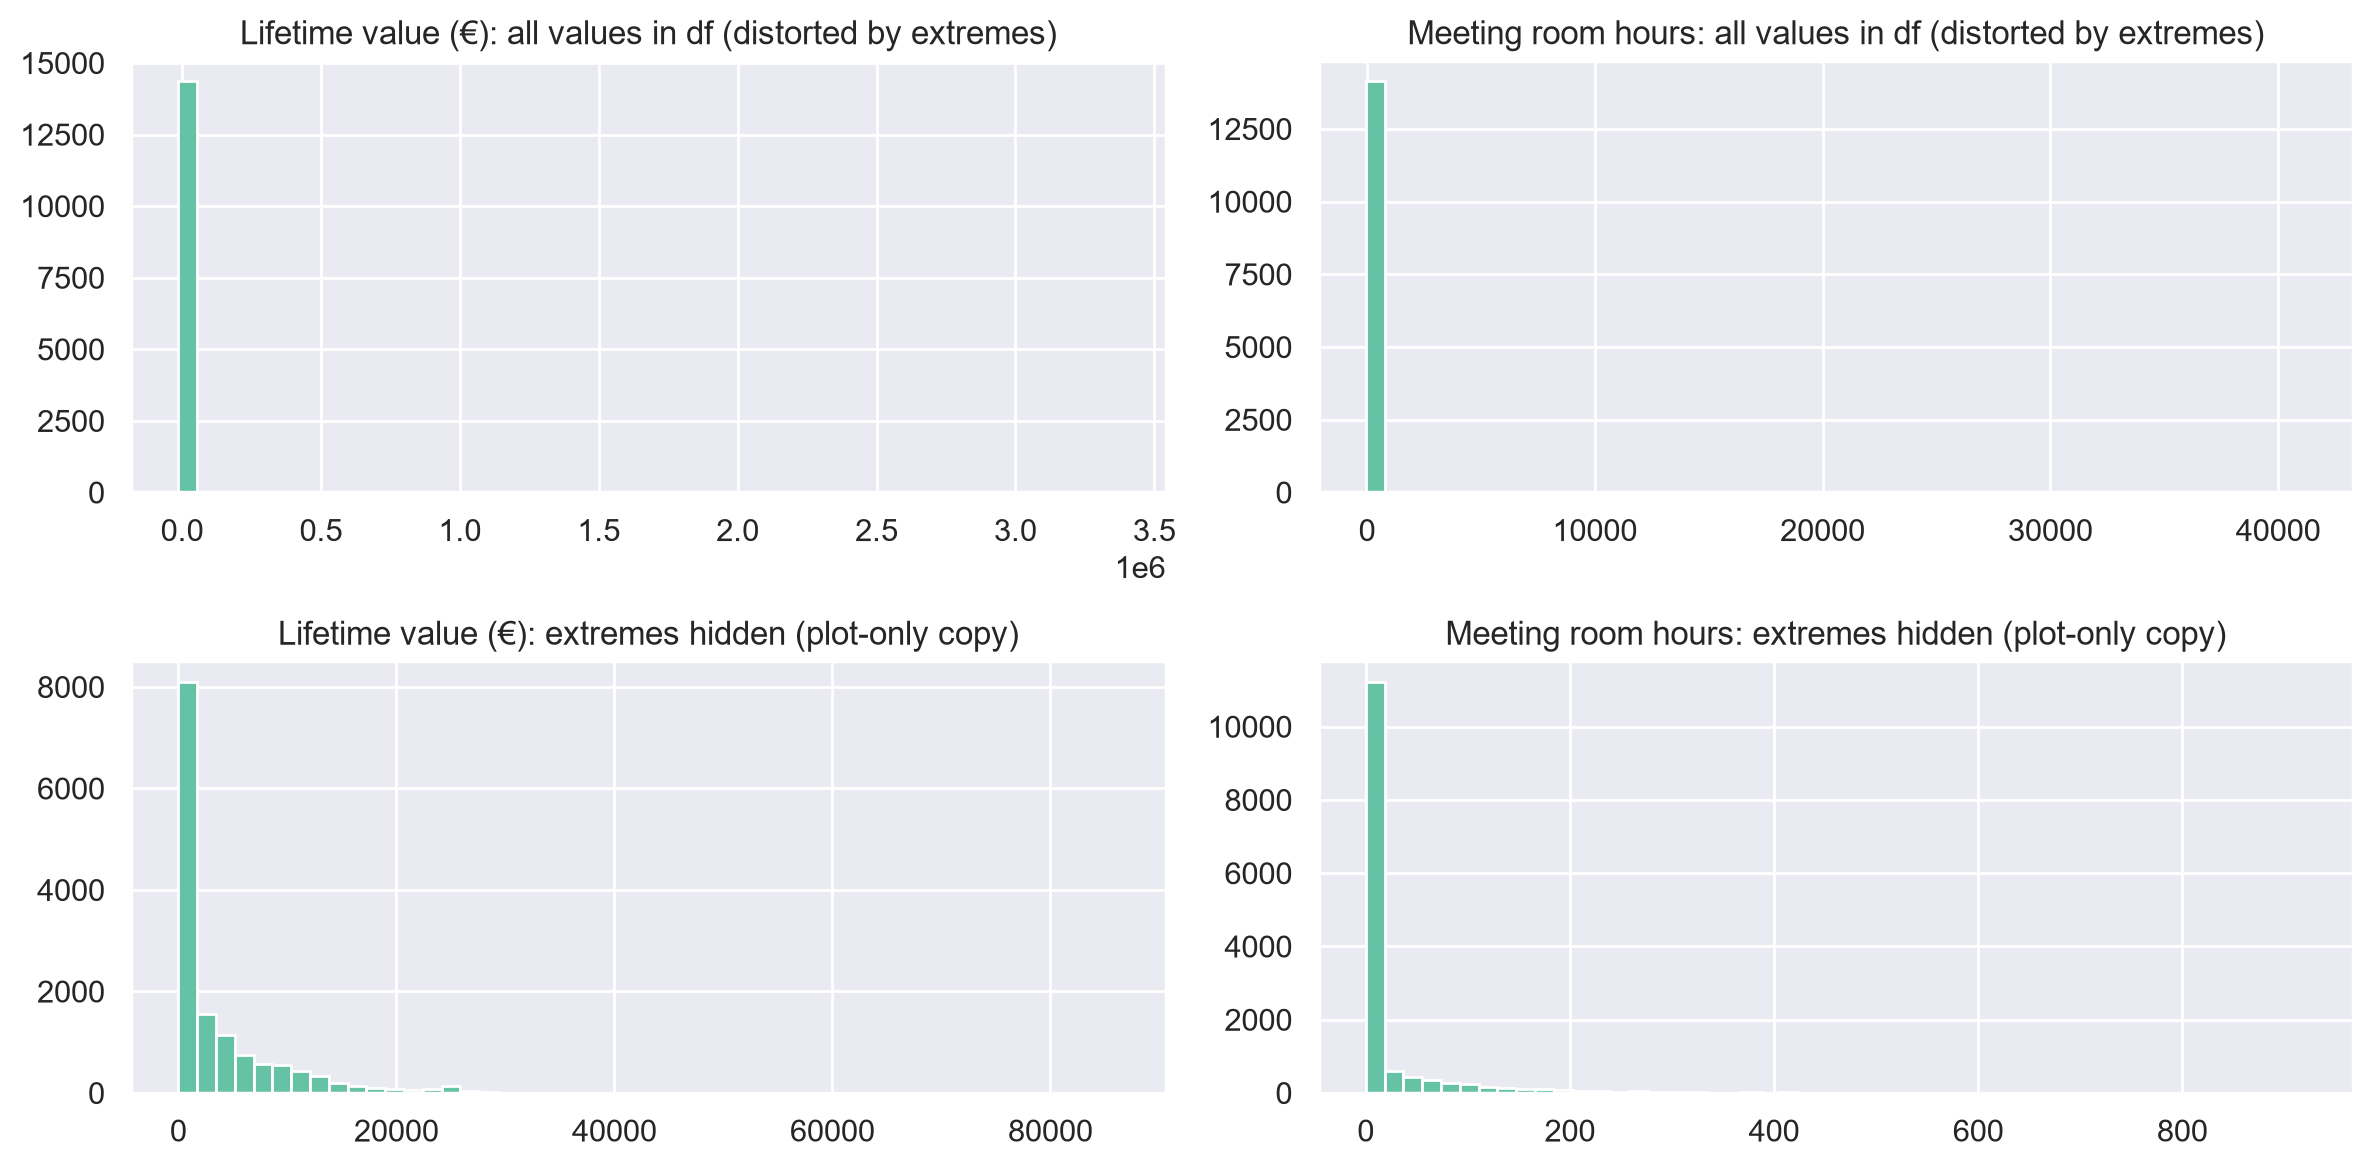

In [68]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for j, (col, title) in enumerate([("lifetime_value", "Lifetime value (€)"), ("meeting_room_hours", "Meeting room hours")]):
    axes[0, j].hist(df[col].dropna(), bins=50)
    axes[0, j].set_title(f"{title}: all values in df (distorted by extremes)")
    axes[1, j].hist(eda[col].dropna(), bins=50)
    axes[1, j].set_title(f"{title}: extremes hidden (plot-only copy)")
plt.tight_layout()
plt.show()

### Helper columns (proposed features)
The columns below are **added to `df` as new columns** (no existing value is changed). They are needed to explore trends and relationships, and they are also our first proposals of features for the clustering (more in section 9):
- `is_active`: assumption that the placeholder end date `1970-01-01` means "no end date, still active" (to be confirmed, see the check in section 5),
- `tenure_months`: length of the membership (to the end date, or to the extraction date for active members). It lets us compare members who joined at different moments,
- `utilisation`: actual visits / entitled visits in the last period (how much of the plan the member really uses),
- `n_addons`: number of add-on services ever used,
- `start_year`: year of the first membership, to follow the cohorts.

The plot-only copy `eda` receives a copy of these columns, to be used in charts only.

In [69]:
# Extraction date: last_badge_swipe + days_since_last_visit should give the same date for everybody
implied = (df["last_badge_swipe"] + pd.to_timedelta(df["days_since_last_visit"], unit="D")).dt.normalize()
print("Most common implied extraction dates:")
print(implied.value_counts().head(3))

Most common implied extraction dates:
2024-01-01    3383
2023-12-31     263
2023-11-28      29
Name: count, dtype: int64


In [70]:
# Check which reference date days_since_last_visit uses
placeholder = df["membership_end"].eq(pd.Timestamp("1970-01-01"))

implied_reference = (
    df["last_badge_swipe"]
    + pd.to_timedelta(df["days_since_last_visit"], unit="D")
).dt.normalize()

reference_check = pd.DataFrame({
    "Group": ["Recorded end date", "Placeholder end date"],
    "Members": [(~placeholder).sum(), placeholder.sum()],
    "Matching expected reference": [
        (
            ~placeholder
            & implied_reference.eq(df["membership_end"])
        ).sum(),
        (
            placeholder
            & implied_reference.eq(pd.Timestamp("2024-01-01"))
        ).sum()
    ]
})

reference_check["Match (%)"] = (
    reference_check["Matching expected reference"]
    / reference_check["Members"] * 100
).round(1)

display(reference_check)

,Group,Members,Matching expected reference,Match (%)
0,Recorded end date,11496,9901,86.10
1,Placeholder end date,3954,3294,83.30


### Membership length and recency

We assume that the end date 1970-01-01 means "no end date", so these members are treated as active and their tenure is counted until the extraction date (1 January 2024, the most common date given by `last_badge_swipe` + `days_since_last_visit`). Negative tenures are set to missing.

The check above shows that `days_since_last_visit` isn't counted from the same date for everyone: 86.1% of the members with a real end date match their end date, while 83.3% of the members with the placeholder match 1 January 2024. So recency cannot be compared directly between the two groups.

Both the meaning of 1970-01-01 and the extraction date are assumptions that still need to be confirmed before clustering.

In [71]:
ref_date = implied.mode().iloc[0] if implied.notna().any() else df["last_badge_swipe"].max()
print("Reference date used:", ref_date.date())

# 1970-01-01 = no end date: we assume these members are still active (to be confirmed)
df["is_active"] = df["membership_end"].dt.year == 1970

# Tenure: to the end date, or to the extraction date for the active members
end_or_ref = df["membership_end"].where(~df["is_active"], ref_date)
df["tenure_months"] = (end_or_ref - df["membership_start"]).dt.days / 30.44
df.loc[df["tenure_months"] < 0, "tenure_months"] = np.nan      # end date before start date

# Utilisation: actual visits / entitled visits in the last period
df["utilisation"] = np.where(df["entitled_visits_last_period"] > 0,
                             df["actual_visits_last_period"] / df["entitled_visits_last_period"], np.nan)

# Number of add-ons used
addon_cols = ["uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print", "uses_mail_handling",
              "uses_phone_booths", "uses_day_passes", "uses_storage", "uses_bike_locker"]
df["n_addons"] = df[addon_cols].fillna(False).astype(bool).sum(axis=1)

df["start_year"] = df["membership_start"].dt.year

# The plot-only copy receives the helper columns too (is_active already exists there)
for c in ["tenure_months", "utilisation", "n_addons", "start_year"]:
    eda[c] = df[c]

df[["tenure_months", "utilisation", "n_addons"]].describe().T.round(2)

Reference date used: 2024-01-01


,count,mean,std,min,25%,50%,75%,max
tenure_months,15298.00,12.31,11.13,0.07,2.14,9.28,20.93,35.97
utilisation,15440.00,0.52,0.31,0.00,0.24,0.52,0.80,1.00
n_addons,15450.00,1.82,1.50,0.00,1.00,1.00,3.00,8.00


## 3. Binary variables: team accounts and add-ons
The distribution charts above only cover numeric variables. The yes/no variables (`is_team_account` and the nine `uses_*` add-ons) are probably among the most useful for describing different types of members, so we look at them here.

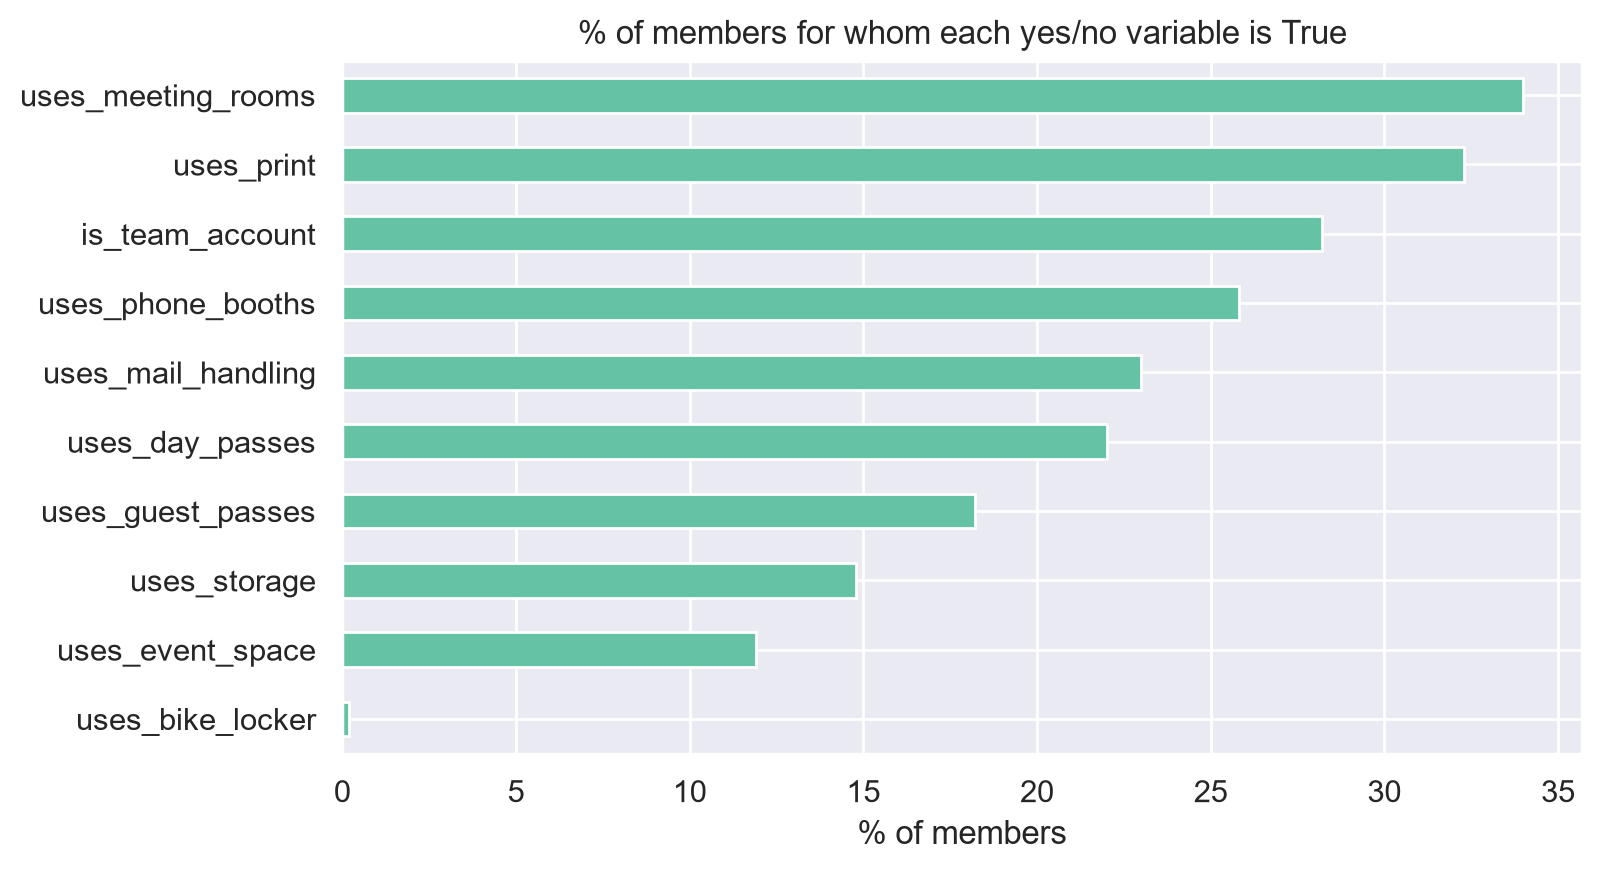

,pct_true,n_missing
uses_bike_locker,0.20,0
uses_event_space,11.90,0
uses_storage,14.80,0
uses_guest_passes,18.20,0
uses_day_passes,22.00,0
uses_mail_handling,23.00,0
uses_phone_booths,25.80,0
is_team_account,28.20,0
uses_print,32.30,0
uses_meeting_rooms,34.00,0


In [72]:
bin_cols = ["is_team_account"] + addon_cols

bin_table = pd.DataFrame({
    "pct_true": (df[bin_cols].astype(float).mean() * 100).round(1),
    "n_missing": df[bin_cols].isna().sum(),
}).sort_values("pct_true")

bin_table["pct_true"].plot(kind="barh", figsize=(8, 4.5))
plt.title("% of members for whom each yes/no variable is True")
plt.xlabel("% of members")
plt.show()
bin_table

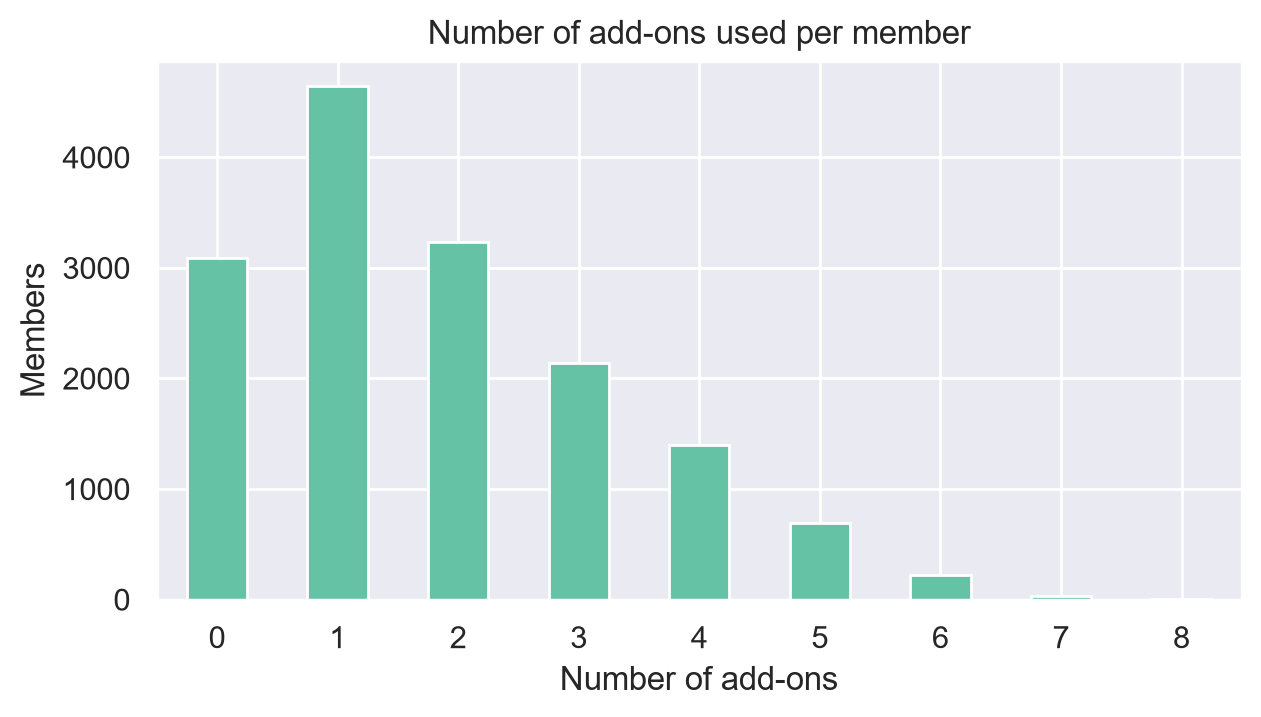

In [73]:
# How many different add-ons does each member use?
df["n_addons"].value_counts().sort_index().plot(kind="bar", figsize=(7, 3.5))
plt.title("Number of add-ons used per member")
plt.xlabel("Number of add-ons")
plt.ylabel("Members")
plt.xticks(rotation=0)
plt.show()

### Insights
- **Low-frequency values:** the add-ons range from very rare (`uses_bike_locker`, about 0.2% of the members) to the most common (`uses_meeting_rooms`, about 34%). The rare ones say little about most members.
- **Univariate distribution:** about 20% of the members use no add-on, the median is 1 and about 29% use three or more (mean 1.8, maximum 8). About 28% of the accounts are team accounts.
- **For segmentation:** the split between "no add-ons", "one" and "several" is a natural way to separate "desk only" from "full service" members (it is also linked to value, see 6.4).

## 4. Reading the distributions
The histograms and boxplots above are drawn on `df`, so the extreme values squash them. Here we summarize the shape of each numeric variable and redraw the histograms with the extreme values hidden, then say what it means.

In [74]:
dist_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit", "total_visits",
             "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period", "meeting_room_hours",
             "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]

shape = pd.DataFrame({
    "median": df[dist_cols].median(),
    "mean": df[dist_cols].mean(),
    "skew": df[dist_cols].skew(),
    "skew_without_extremes": eda[dist_cols].skew(),   # NEW: same variables in the plot-only copy
    "pct_zero": (df[dist_cols] == 0).mean() * 100,
})
shape["mean_over_median"] = shape["mean"] / shape["median"].replace(0, np.nan)
shape.sort_values("skew", ascending=False).round(2)

,median,mean,skew,skew_without_extremes,pct_zero,mean_over_median
meeting_room_hours,0.00,33.09,70.80,4.86,59.82,NaN
lifetime_value,825.12,6398.77,30.79,2.92,11.28,7.75
avg_weekly_visits,1.42,1.78,10.27,0.92,0.09,1.25
event_space_hours,0.00,5.12,9.22,9.22,88.56,NaN
guest_passes_issued,0.00,6.16,7.01,7.01,75.71,NaN
total_visits,34.00,110.39,6.82,2.14,0.71,3.25
age,34.00,34.86,3.03,0.36,0.00,1.03
days_since_last_visit,13.00,117.19,2.72,2.76,0.55,9.01
n_colleagues_on_account,0.00,0.54,2.12,2.24,69.18,NaN
n_renewals,0.00,1.01,1.34,1.42,50.11,NaN


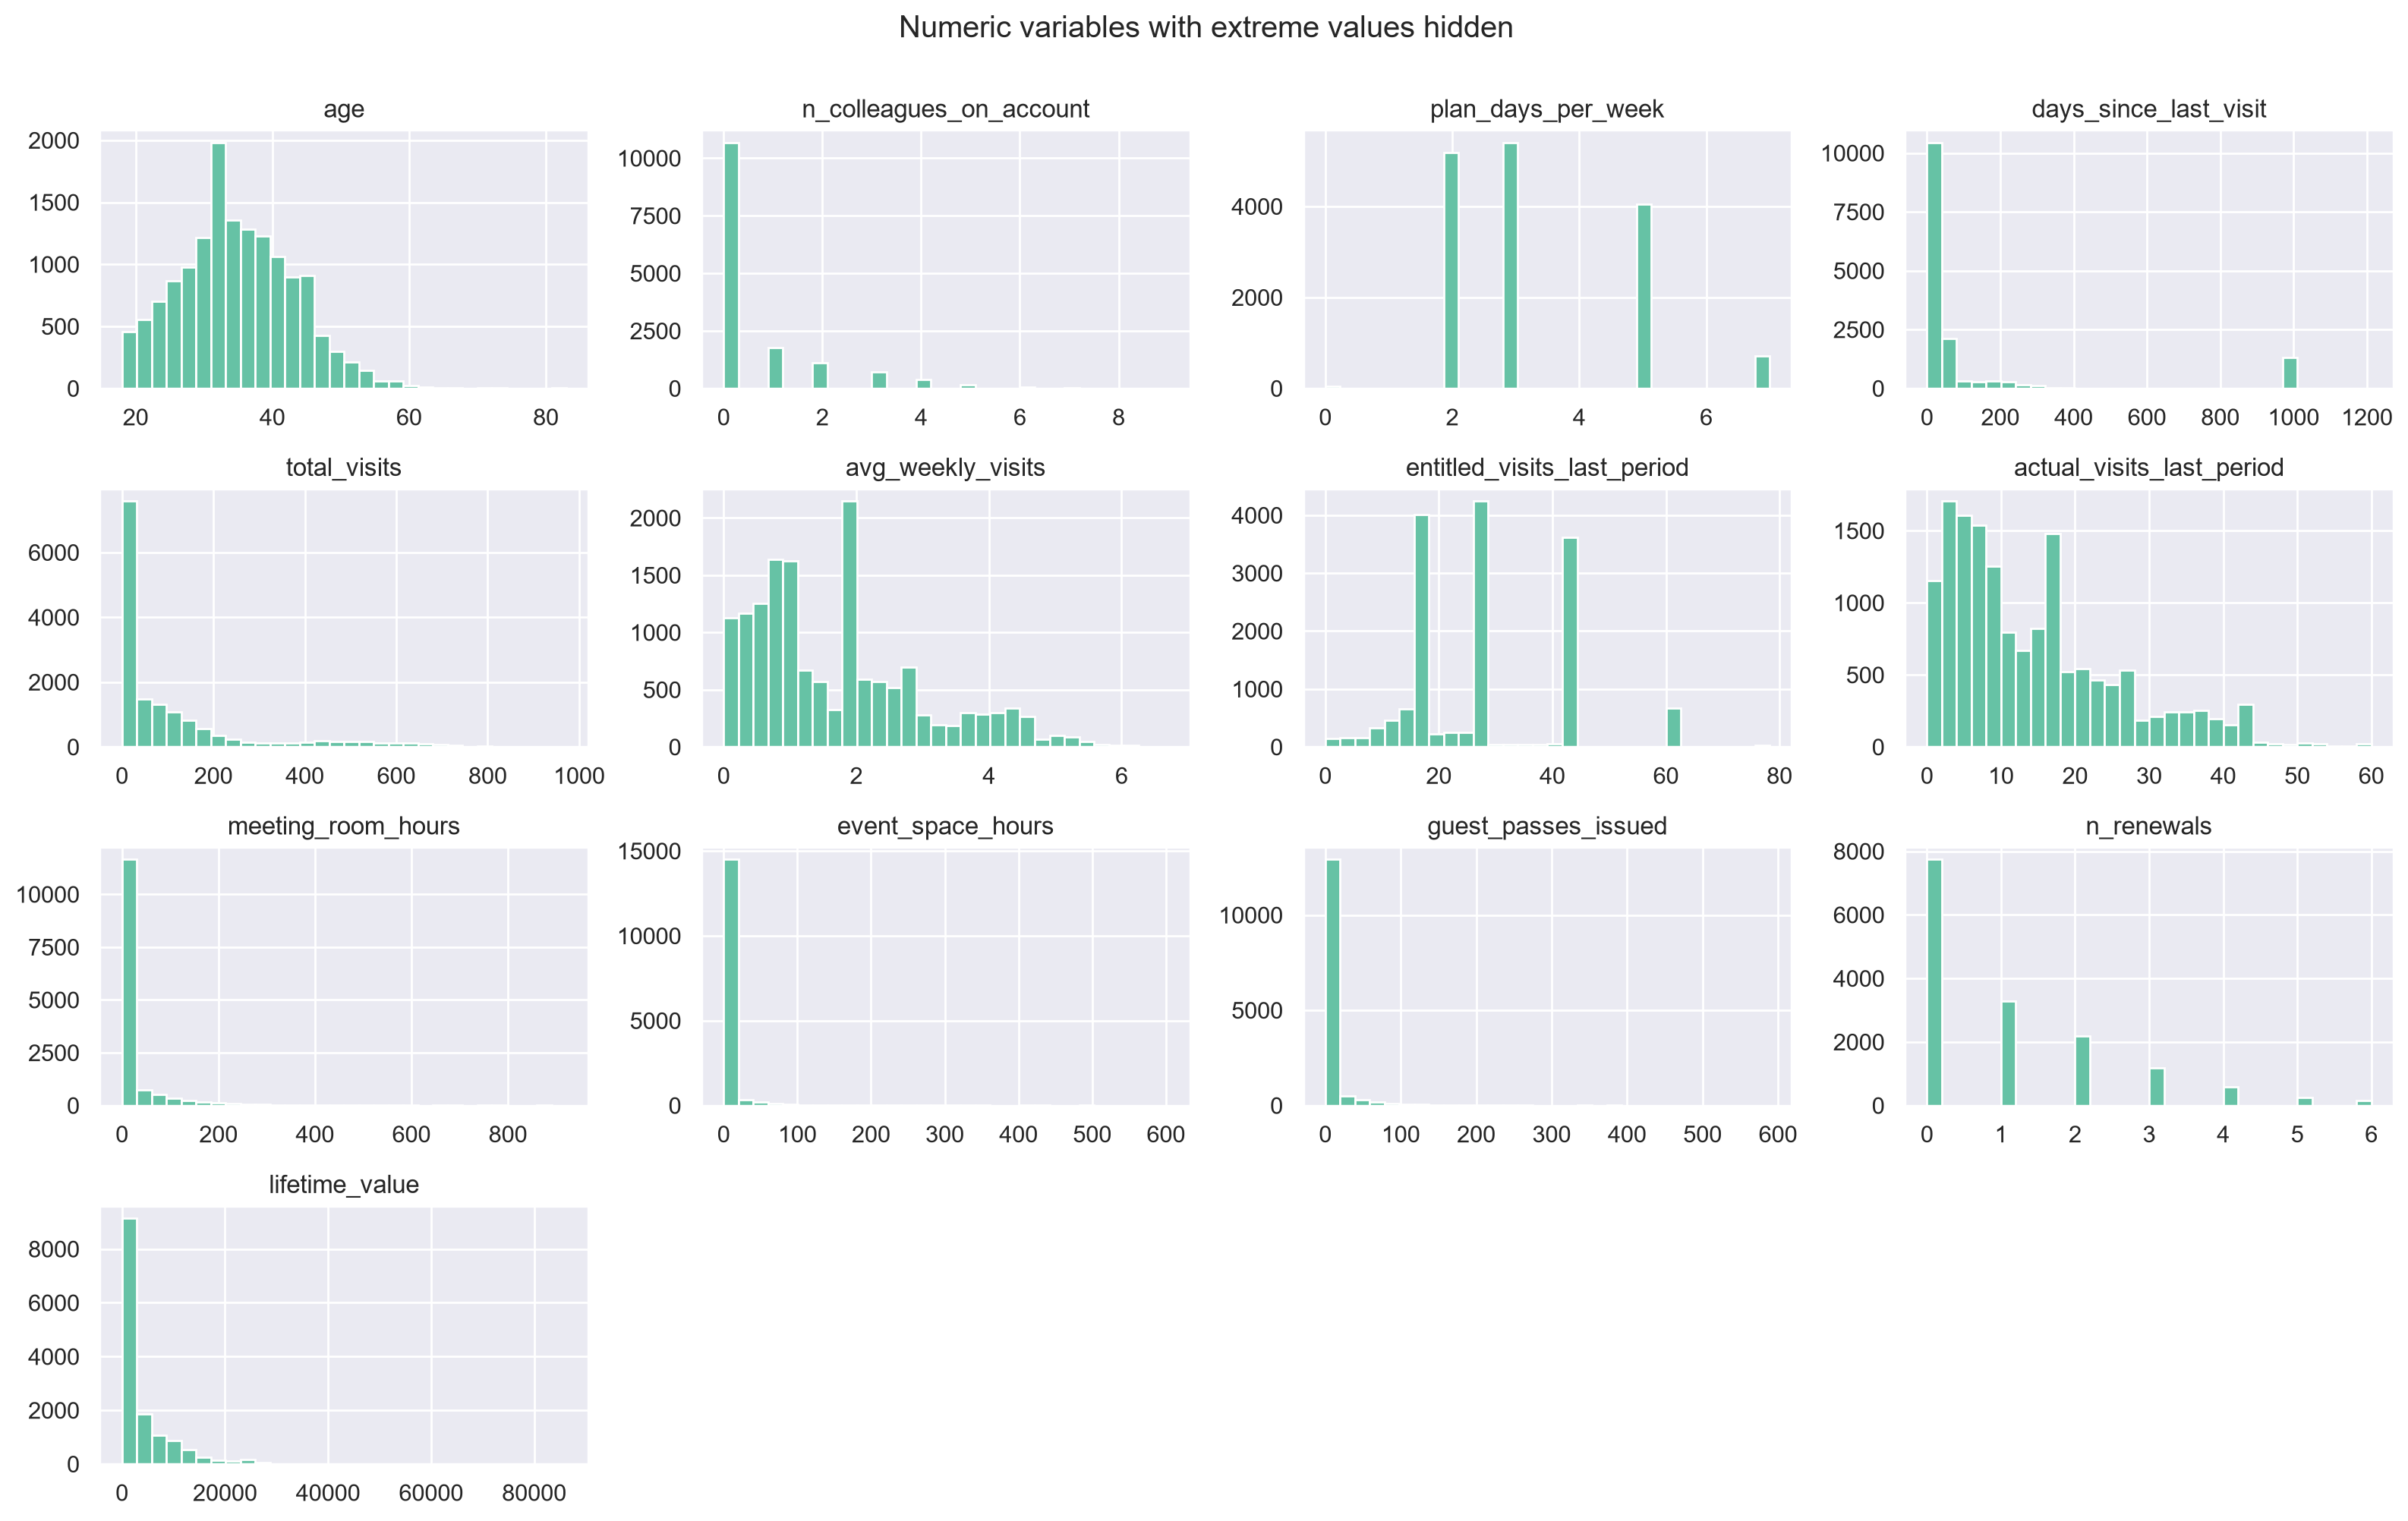

In [75]:
eda[dist_cols].hist(bins=30, figsize=(16, 10))
plt.suptitle("Numeric variables with extreme values hidden", y=1.0)
plt.tight_layout()
plt.show()

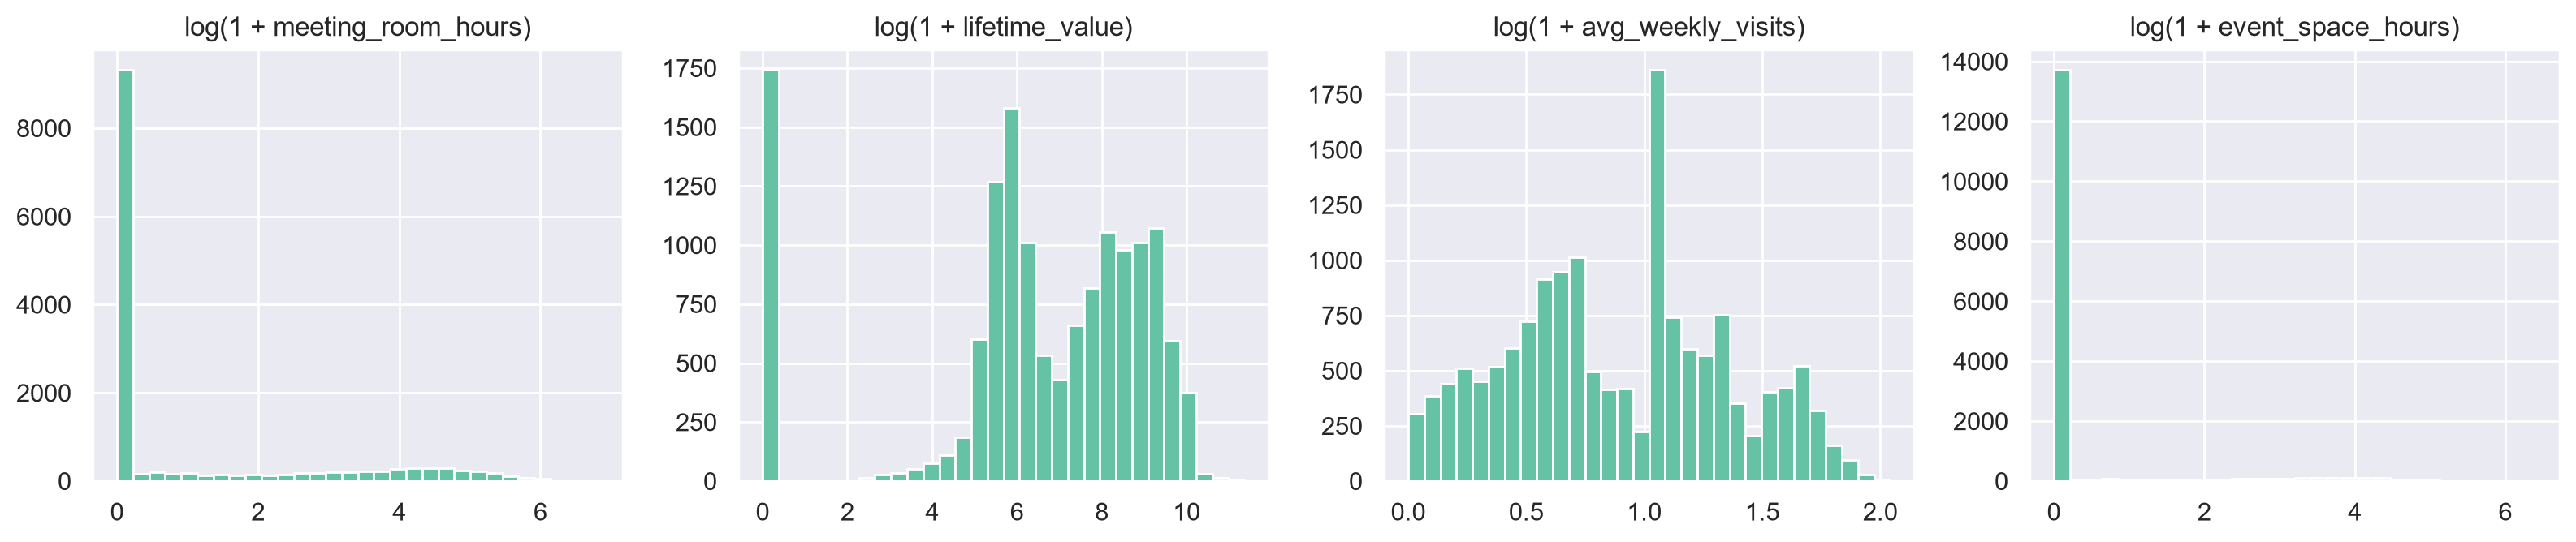

In [76]:
# The most skewed variables, on a log scale (log(1 + x) because of the zeros)
top_skew = shape["skew"].sort_values(ascending=False).head(4).index
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, c in zip(axes, top_skew):
    ax.hist(np.log1p(eda[c].dropna()), bins=30)
    ax.set_title(f"log(1 + {c})")
plt.tight_layout()
plt.show()

### Insights
- **Univariate distributions:** most usage variables are strongly right-skewed, with many zeros: `event_space_hours` (89% zeros), `guest_passes_issued` (76%), `n_colleagues_on_account` (69%), `meeting_room_hours` (60%) and `n_renewals` (50%). The zeros are real information (members who never use a service), not errors. The skew computed on `df` is inflated by the data errors (for example about 31 for `lifetime_value` and about 71 for `meeting_room_hours`, against about 3 and 5 once the extremes are hidden). `age` is the only roughly symmetric variable (skew 0.4, median 34).
- **Variables with few distinct values:** `plan_days_per_week` (2, 3, 5 or 7 days) and `entitled_visits_last_period` (a few typical values) behave like categories, not like continuous variables.
- **Two groups inside a variable:** `days_since_last_visit` has a second group around 1,000 days (its mode is 999), which looks like a code and not a real gap between visits. `avg_weekly_visits` has a clear peak around 2 visits per week.
- **Potential univariate outliers:** even with the impossible values hidden, `lifetime_value`, `meeting_room_hours`, `event_space_hours` and `guest_passes_issued` keep a long right tail.
- **Why it matters for clustering:** strongly skewed variables let a few members dominate distance-based methods such as k-means, and variables with very different scales weigh differently. The treatment (for example log(1 + x) and scaling) is done in data preparation.

## 5. Trends over time

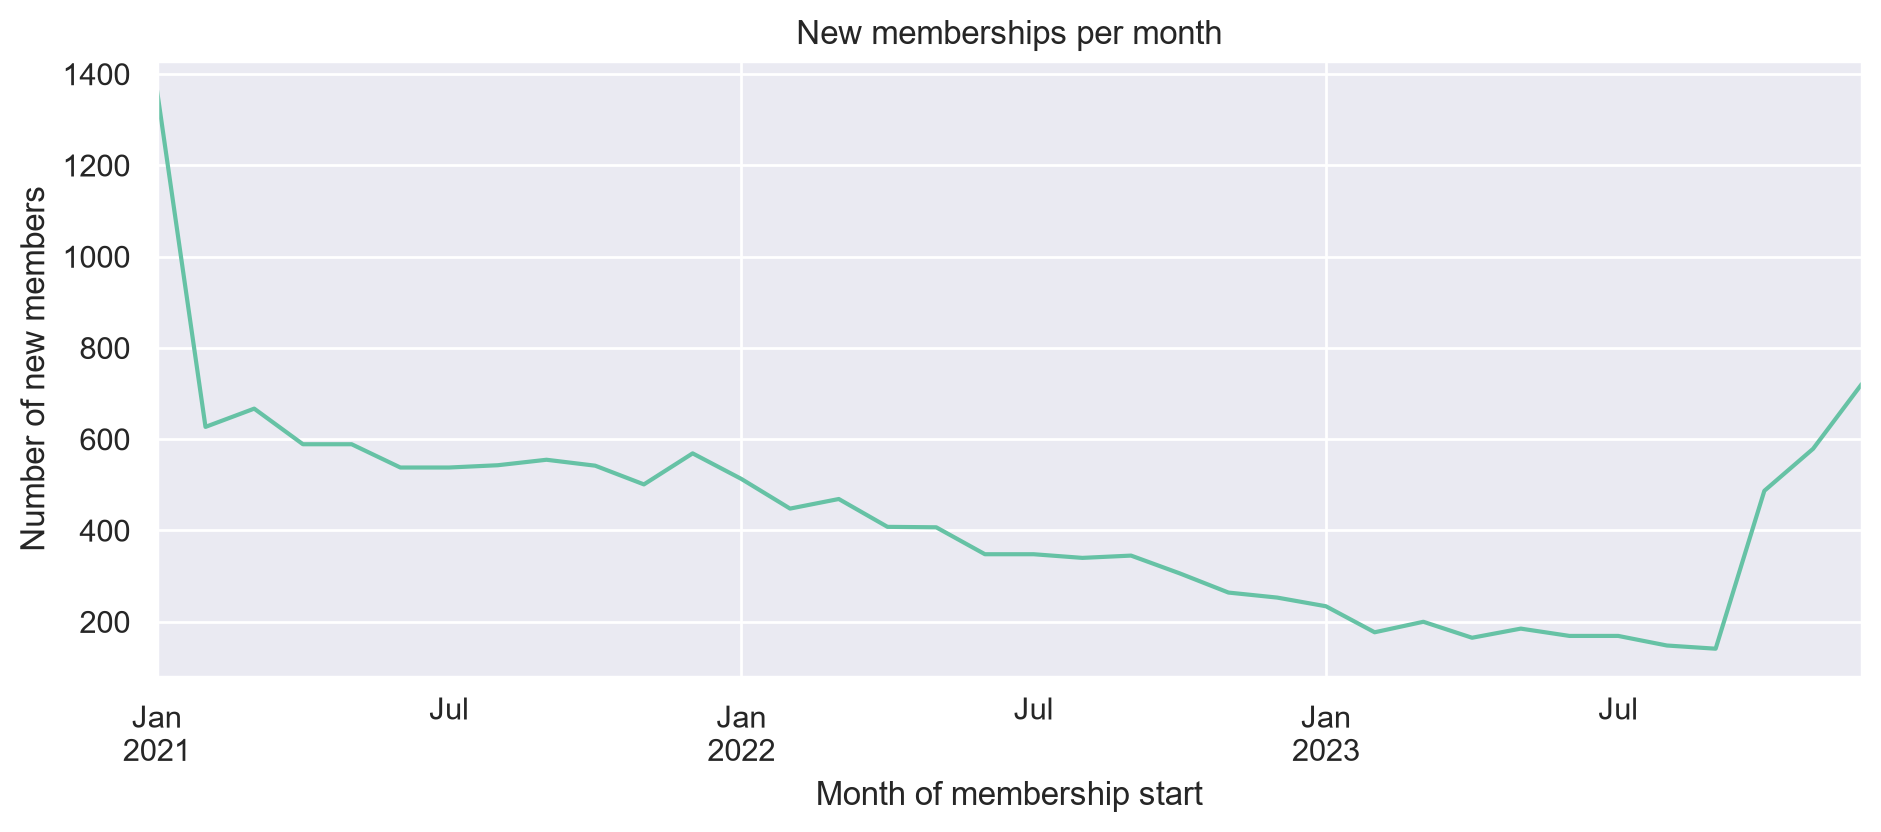

In [77]:
# New memberships per month
new_per_month = eda.groupby(eda["membership_start"].dt.to_period("M")).size()

plt.figure(figsize=(11, 4))
new_per_month.plot()
plt.title("New memberships per month")
plt.xlabel("Month of membership start")
plt.ylabel("Number of new members")
plt.show()

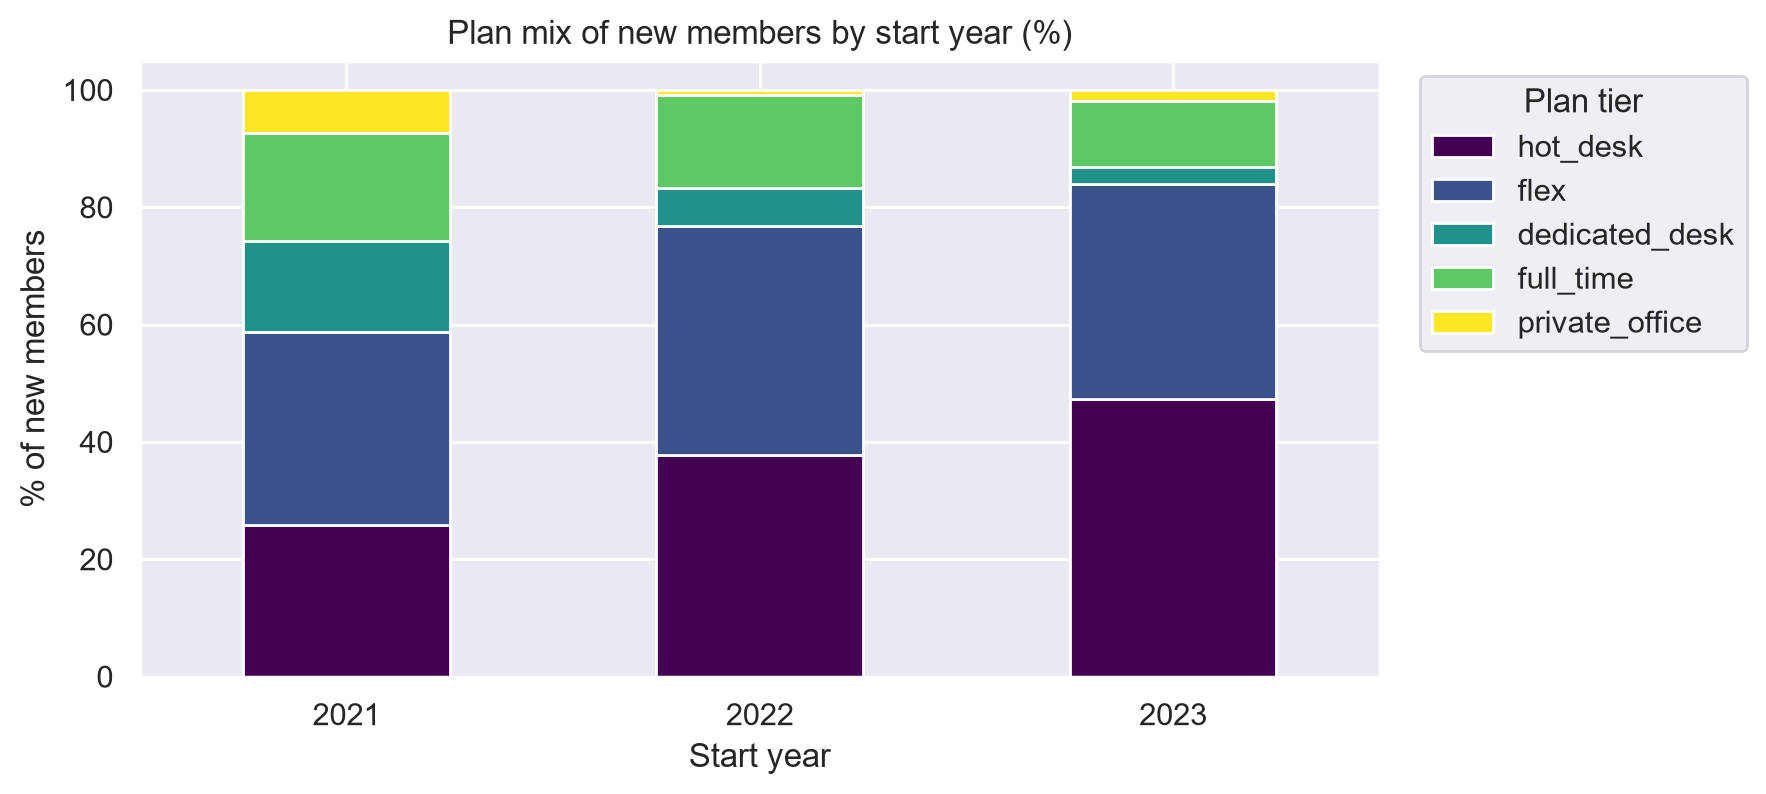

plan_tier,hot_desk,flex,dedicated_desk,full_time,private_office
start_year,,,,,
2021,25.80,33.00,15.40,18.40,7.40
2022,37.80,38.90,6.50,15.90,0.90
2023,47.30,36.70,2.90,11.20,1.90


In [78]:
# Mix of plans among new members, by start year (share of each plan in each year)
mix = (pd.crosstab(df["start_year"], df["plan_tier"], normalize="index")
         .reindex(columns=[p for p in PLAN_ORDER if p in df["plan_tier"].unique()]) * 100)

mix.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="viridis")
plt.title("Plan mix of new members by start year (%)")
plt.xlabel("Start year")
plt.ylabel("% of new members")
plt.legend(title="Plan tier", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.show()
mix.round(1)

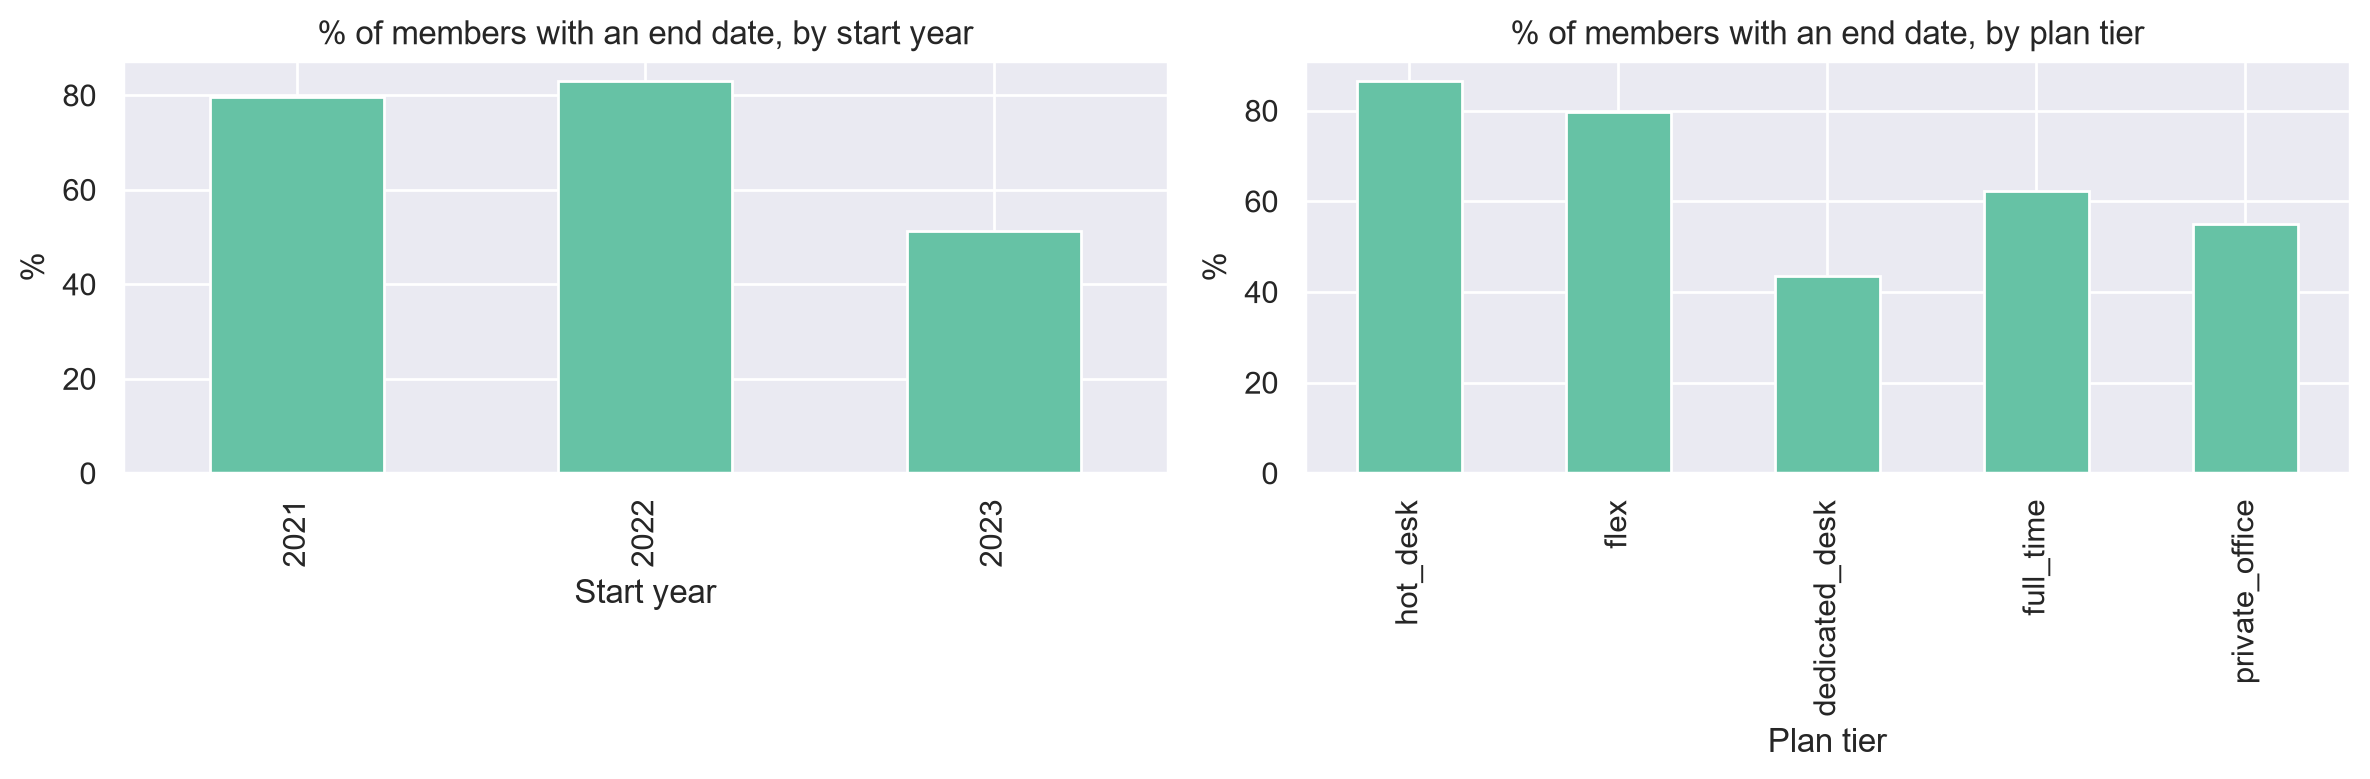

In [79]:
# Share of members who already ended their membership, by start year and by plan
ended_by_year = (1 - df.groupby("start_year")["is_active"].mean()) * 100
ended_by_plan = ((1 - df.groupby("plan_tier")["is_active"].mean()) * 100).reindex(PLAN_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ended_by_year.plot(kind="bar", ax=axes[0])
axes[0].set_title("% of members with an end date, by start year")
axes[0].set_ylabel("%"); axes[0].set_xlabel("Start year")
ended_by_plan.plot(kind="bar", ax=axes[1])
axes[1].set_title("% of members with an end date, by plan tier")
axes[1].set_ylabel("%"); axes[1].set_xlabel("Plan tier")
plt.tight_layout()
plt.show()

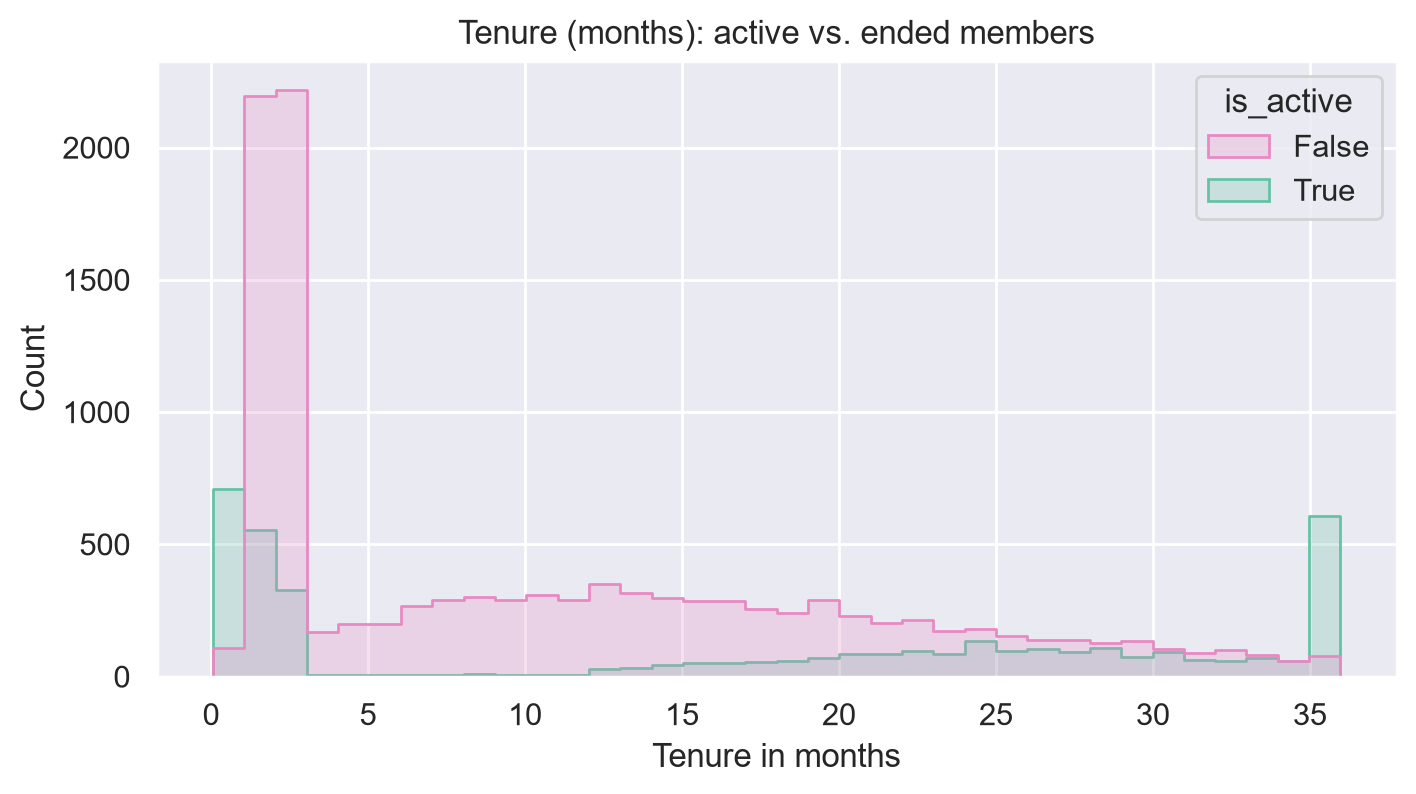

,count,mean,std,min,25%,50%,75%,max
is_active,,,,,,,,
False,11344.00,10.80,9.50,0.10,2.30,8.20,17.60,36.00
True,3954.00,16.70,13.90,0.10,1.50,19.10,29.30,36.00


In [80]:
# Tenure: active vs. ended members
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="tenure_months", hue="is_active", palette={True: "#66c2a5", False: "#e78ac3"}, bins=36, element="step", common_norm=False)
plt.title("Tenure (months): active vs. ended members")
plt.xlabel("Tenure in months")
plt.show()

df.groupby("is_active")["tenure_months"].describe().round(1)

### Insights
- **New members:** the monthly chart starts with a spike in January 2021 (about 560 members start exactly on 2021-01-01, probably members who joined before the data starts), then new memberships fall steadily to about 150 per month in 2023 (7,626 new members in 2021, 4,449 in 2022 and 3,375 in 2023), and rise sharply in the last three months. We see no repeated seasonal pattern across the years.
- **Plan mix:** the new members move towards the cheaper plans: `hot_desk` goes from 26% (2021) to 38% (2022) and 47% (2023); `dedicated_desk` falls from 15% to 7% and 3%; `private_office` from 7% to 1% and 2%; `full_time` from 18% to 11%.
- **Differences between groups:** the share of members still without an end date grows with the weight of the plan: 13% for `hot_desk`, 20% for `flex`, 38% for `full_time`, 45% for `private_office` and 57% for `dedicated_desk`. More members of the cheaper plans have a recorded end date.
- **Tenure:** ended memberships have a median of 8.2 months, active ones 19.1 months (partly by construction, since active members are still counting).
- **Assumption to check:** "active" is based on the 1970 placeholder, and it is doubtful. Active members have a median of 26 days since the last visit (11 for ended members), 25% are above 198 days and the maximum is 1,212 days, so many of them haven't visited for a long time. "Active" may only mean that no end date was recorded.

In [81]:
# Sanity check of the "active" assumption: do active members visit recently?
df.groupby("is_active")["days_since_last_visit"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
is_active,,,,,,,,
False,11496.00,99.60,269.10,-956.00,4.00,11.00,44.00,1002.00
True,3954.00,168.50,287.70,-103.00,5.00,26.00,198.00,1212.00


## 6. Relationships between variables

### 6.1 Plan tier vs. value and usage

In [82]:
by_plan = (df.groupby("plan_tier")
             .agg(n_members=("member_id", "count"),
                  median_ltv=("lifetime_value", "median"),
                  median_weekly_visits=("avg_weekly_visits", "median"),
                  median_utilisation=("utilisation", "median"),
                  median_tenure_months=("tenure_months", "median"),
                  median_renewals=("n_renewals", "median"),
                  median_addons=("n_addons", "median"),
                  pct_team=("is_team_account", lambda s: s.astype(float).mean() * 100),
                  pct_active=("is_active", lambda s: s.mean() * 100))
             .reindex(PLAN_ORDER))
by_plan.round(2)

,n_members,median_ltv,median_weekly_visits,median_utilisation,median_tenure_months,median_renewals,median_addons,pct_team,pct_active
plan_tier,,,,,,,,,
hot_desk,5212,318.47,0.96,0.46,2.63,0.00,1.00,28.07,13.35
flex,5449,1153.43,1.89,0.57,8.56,0.00,1.00,28.81,20.26
dedicated_desk,1549,10348.02,3.86,0.74,26.61,2.00,3.00,27.63,56.55
full_time,2471,4613.16,1.61,0.33,17.15,1.00,2.00,26.83,37.64
private_office,664,19984.24,1.04,0.15,29.89,2.00,3.00,31.17,45.03


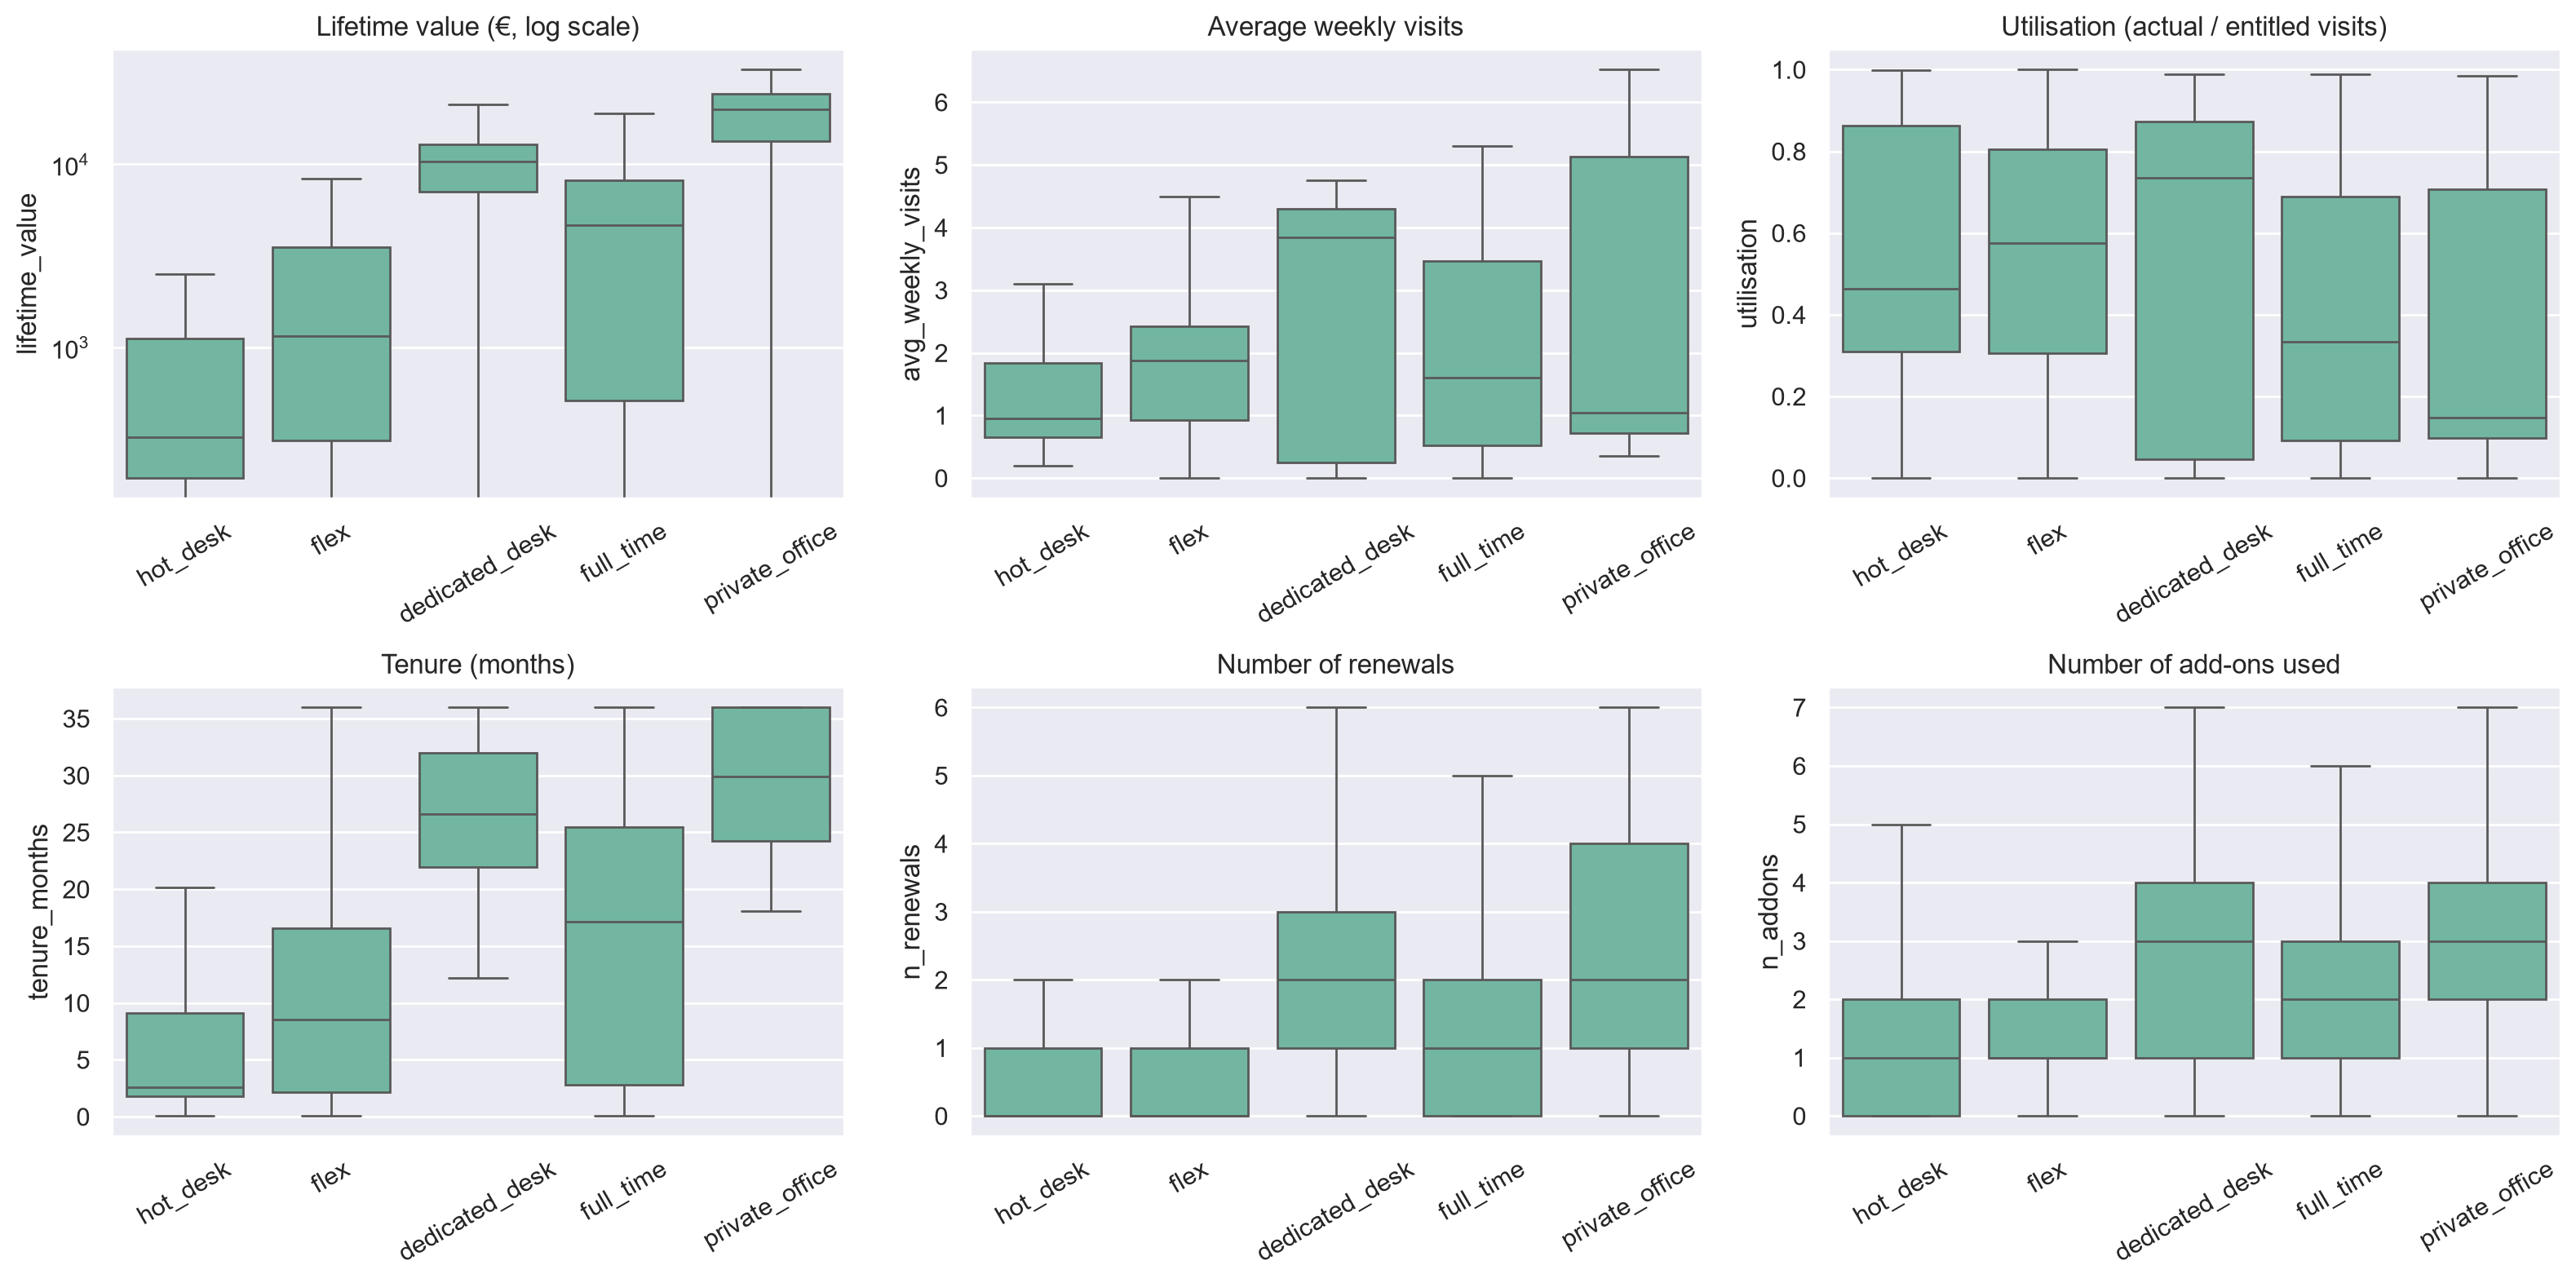

In [83]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
panels = [("lifetime_value", "Lifetime value (€, log scale)", True),
          ("avg_weekly_visits", "Average weekly visits", False),
          ("utilisation", "Utilisation (actual / entitled visits)", False),
          ("tenure_months", "Tenure (months)", False),
          ("n_renewals", "Number of renewals", False),
          ("n_addons", "Number of add-ons used", False)]

for ax, (col, title, logy) in zip(axes.flat, panels):
    sns.boxplot(data=eda, x="plan_tier", y=col, order=PLAN_ORDER, ax=ax, showfliers=False)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
    if logy:
        ax.set_yscale("log")
plt.tight_layout()
plt.show()

### Insights
- **Relationship with the plan:** the median lifetime value is 318 euros for hot_desk, 1,153 euros for flex, 10,348 euros for dedicated_desk, 4,613 euros for full_time and 19,984 euros for private_office. These differences also reflect membership duration, so lifetime value alone doesn't measure spending intensity.
- **Plan order:** dedicated_desk members have a higher median lifetime value than full_time members, but also longer tenure. This differs from the documented tier order, which puts full_time above dedicated_desk. For clustering, the encoding should avoid assuming equal distances between tiers.
- **Value without use:** `private_office` has the highest value and tenure but the lowest utilization (0.15) and only about 1.0 visits per week. `full_time` also uses little (0.33). `dedicated_desk` is the most engaged plan (utilization 0.74). Paying a lot and using little is a candidate segment.
- **Overlap:** the plan explains only 4% of the variation of utilization and 17% of the weekly visits (section 7), so members of the same plan behave very differently. The plan alone isn't enough to define segments.

### 6.2 Utilization of the plan

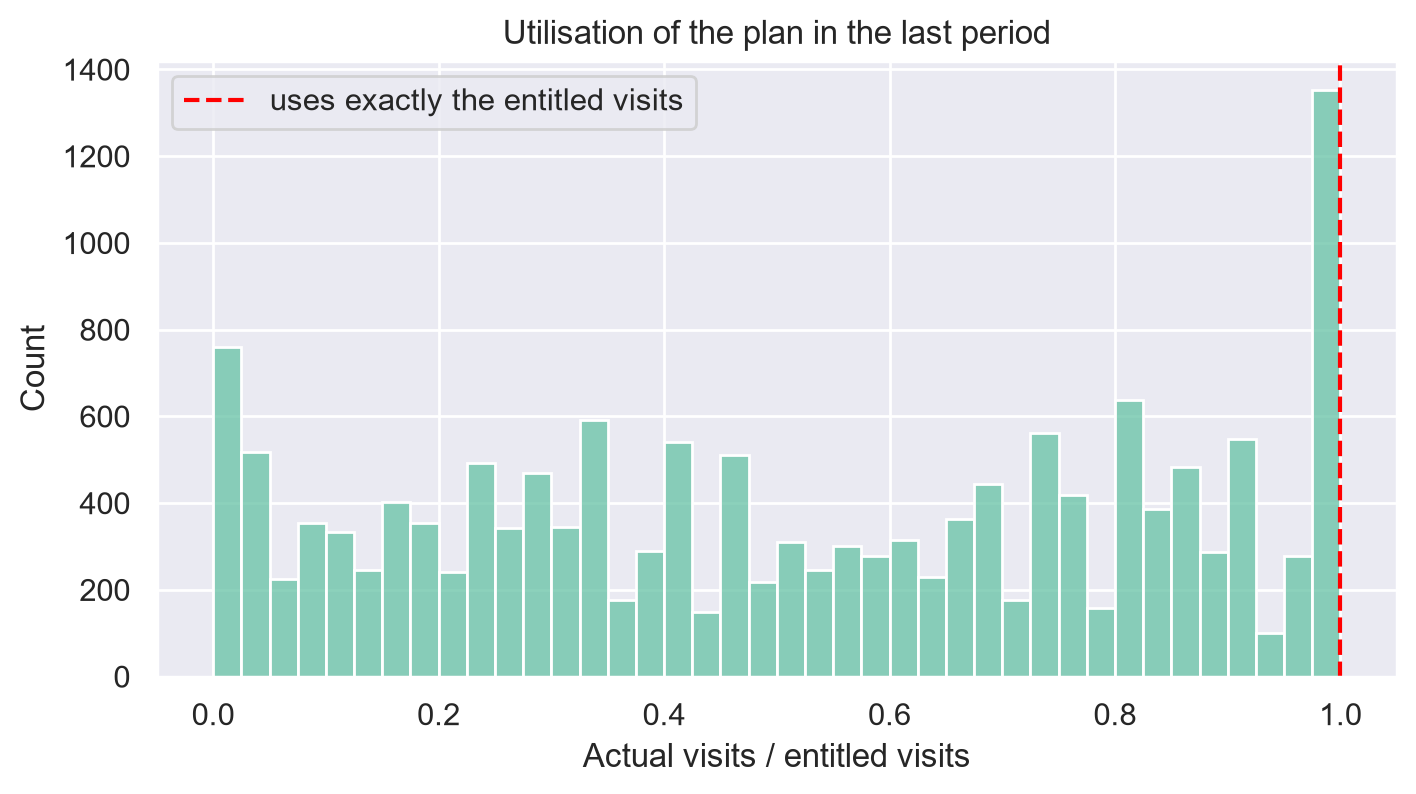

Members with a defined utilisation: 15440
Use less than 25% of their plan: 25.5%
Use between 25% and 100%:        74.5%
Use more than their plan:        0.0%


In [84]:
plt.figure(figsize=(8, 4))
sns.histplot(df["utilisation"], bins=40)
plt.axvline(1, color="red", linestyle="--", label="uses exactly the entitled visits")
plt.title("Utilisation of the plan in the last period")
plt.xlabel("Actual visits / entitled visits")
plt.legend()
plt.show()

u = df["utilisation"].dropna()
print(f"Members with a defined utilisation: {len(u)}")
print(f"Use less than 25% of their plan: {(u < 0.25).mean() * 100:.1f}%")
print(f"Use between 25% and 100%:        {((u >= 0.25) & (u <= 1)).mean() * 100:.1f}%")
print(f"Use more than their plan:        {(u > 1).mean() * 100:.1f}%")

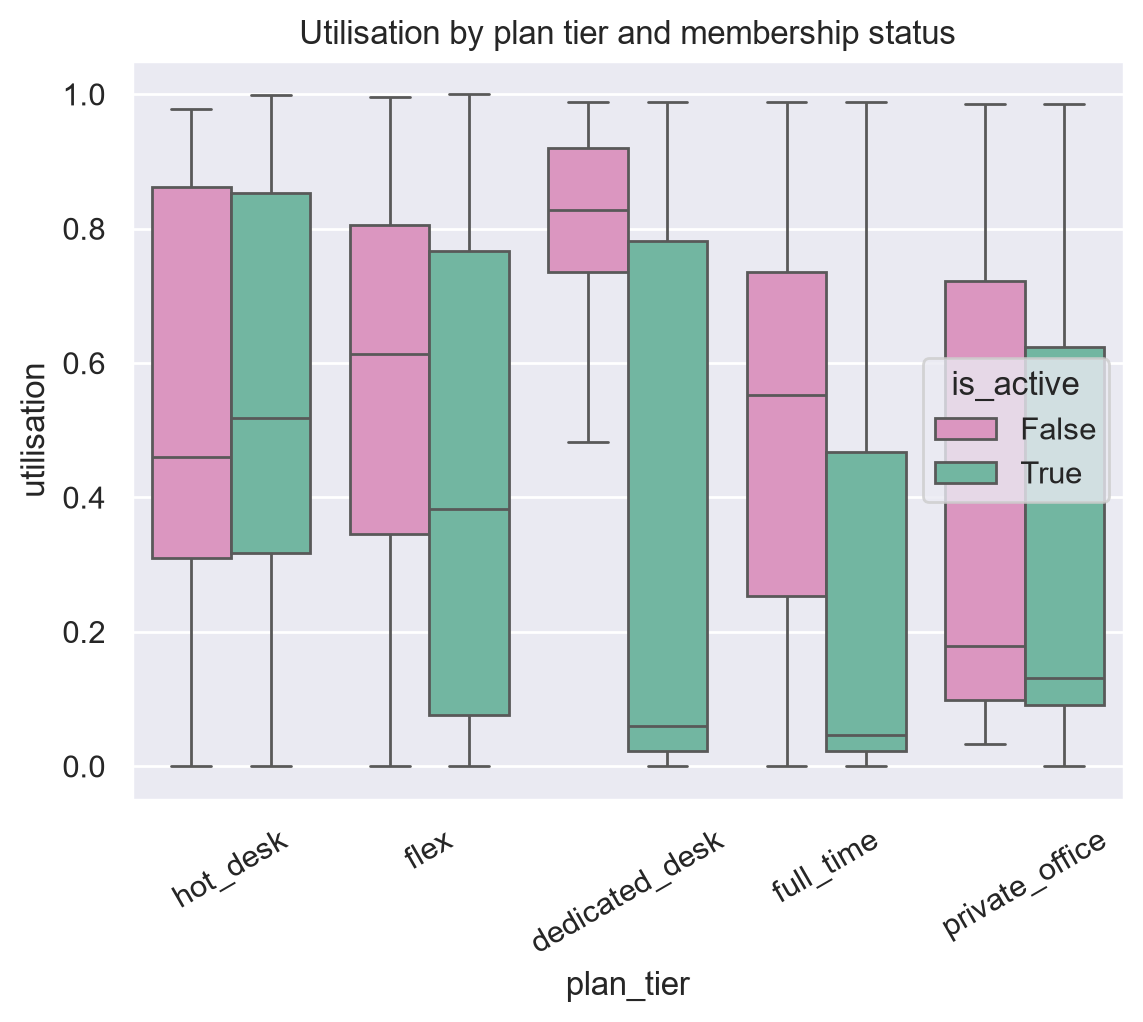

In [85]:
# Utilisation by plan and by activity status
sns.boxplot(data=eda, x="plan_tier", y="utilisation", hue="is_active", palette={True: "#66c2a5", False: "#e78ac3"}, order=PLAN_ORDER, showfliers=False)
plt.title("Utilisation by plan tier and membership status")
plt.xticks(rotation=30)
plt.show()

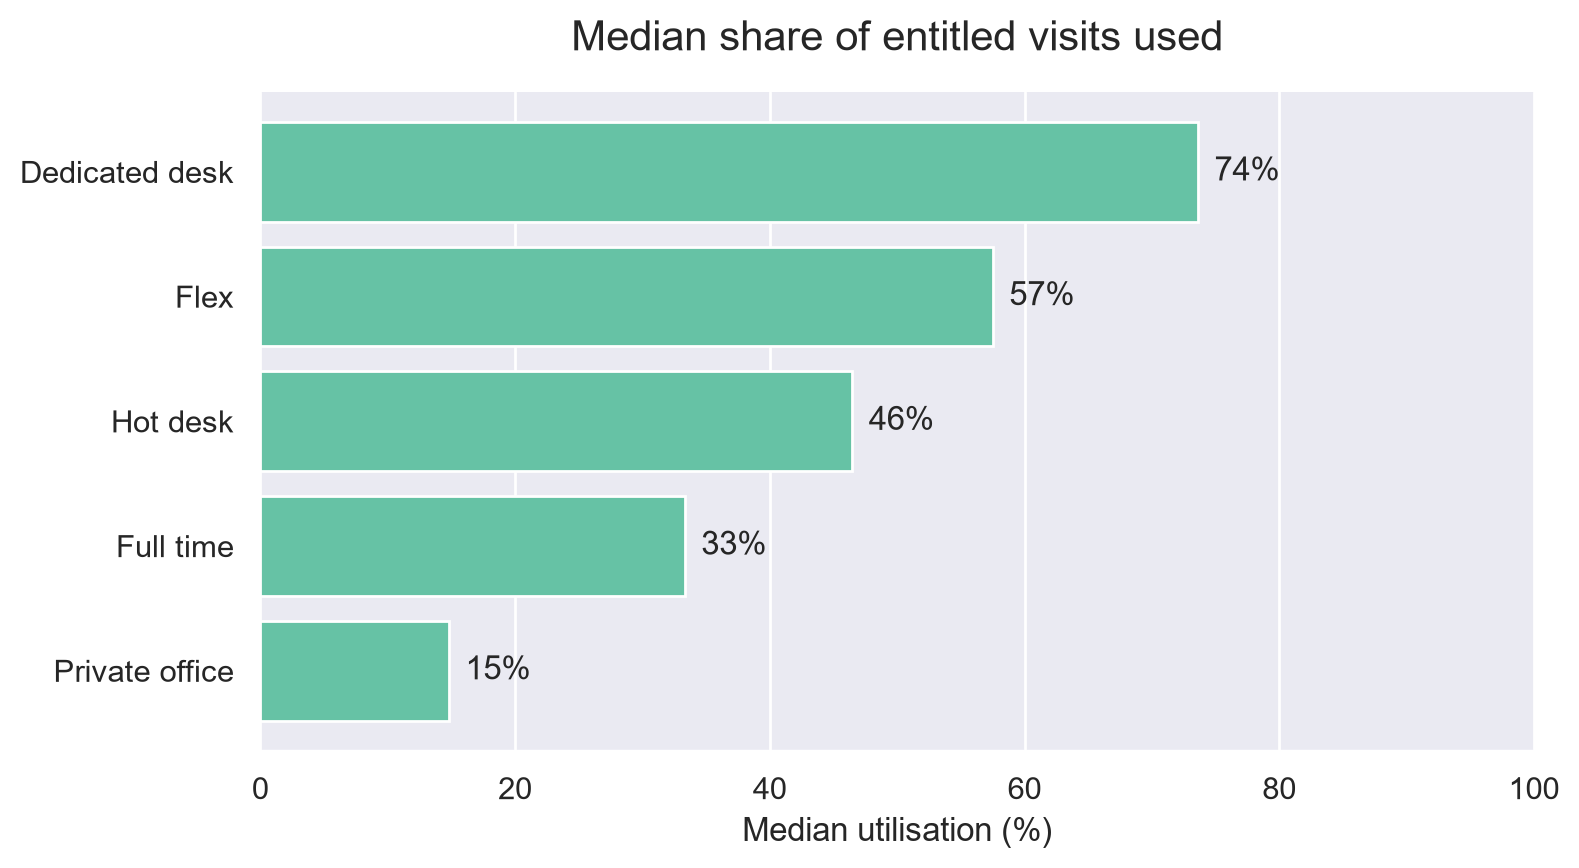

In [86]:
# Median utilisation by membership plan
median_utilisation = (
    df.groupby("plan_tier")["utilisation"]
    .median()
    .sort_values(ascending=False)
    .mul(100)
)

labels = {
    "dedicated_desk": "Dedicated desk",
    "flex": "Flex",
    "hot_desk": "Hot desk",
    "full_time": "Full time",
    "private_office": "Private office"
}

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    median_utilisation.index.map(labels),
    median_utilisation.values
)

ax.invert_yaxis()
ax.bar_label(bars, fmt="%.0f%%", padding=6, fontsize=12)
ax.set_xlim(0, 100)
ax.set_xlabel("Median utilisation (%)")
ax.set_title(
    "Median share of entitled visits used",
    fontsize=15, pad=15
)
ax.grid(axis="y", visible=False)
sns.despine(left=True)
plt.tight_layout()

plt.savefig(
    "median_utilisation_by_plan.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

### Insights
- **Univariate distribution:** the median utilization is 0.52 and 25.5% of the members use less than a quarter of their plan. Practically nobody is above 100% (the maximum is 1.00), so utilization looks capped and cannot show over-use. The under-users are concentrated in `private_office` (median 0.15) and `full_time` (0.33), and they are candidates for an "under-users" segment.
- **Possible relationships:** utilization is only weakly related to the time since the last visit (Pearson -0.22, see 6.6). The boxplot by status shows whether the ended members already used less in their last period.

### 6.3 Team accounts vs. individual members

In [87]:
team_profile = (df.groupby("is_team_account")
                  .agg(n_members=("member_id", "count"),
                       median_ltv=("lifetime_value", "median"),
                       median_weekly_visits=("avg_weekly_visits", "median"),
                       median_guest_passes=("guest_passes_issued", "median"),
                       median_meeting_hours=("meeting_room_hours", "median"),
                       median_event_hours=("event_space_hours", "median"),
                       median_addons=("n_addons", "median"),
                       median_tenure=("tenure_months", "median"),
                       median_colleagues=("n_colleagues_on_account", "median")))
display(team_profile.round(2))

# Plan mix of team vs individual accounts (% within each group)
(pd.crosstab(df["is_team_account"], df["plan_tier"], normalize="index")
   .reindex(columns=PLAN_ORDER) * 100).round(1)

,n_members,median_ltv,median_weekly_visits,median_guest_passes,median_meeting_hours,median_event_hours,median_addons,median_tenure,median_colleagues
is_team_account,,,,,,,,,
False,11100,810.52,1.42,0.00,0.00,0.00,1.00,9.23,0.00
True,4350,876.60,1.45,0.00,0.00,0.00,2.00,9.49,2.00


plan_tier,hot_desk,flex,dedicated_desk,full_time,private_office
is_team_account,,,,,
False,34.00,35.20,10.20,16.40,4.10
True,33.80,36.30,9.90,15.30,4.80


### Insights
- **Teams vs. individuals are almost identical:** median lifetime value 877 euros vs 811 euros, weekly visits 1.45 vs 1.42, tenure 9.5 vs 9.2 months, and an almost identical plan mix (for example `hot_desk` 33.8% vs 34.0%). The only differences are one more add-on for teams (median 2 vs 1) and the number of colleagues (which depends on the definition).
- **For segmentation:** `is_team_account` separates members very little. `n_colleagues_on_account` is 69% zeros and has the code -1, so it should be handled with care.

### 6.4 Add-on usage

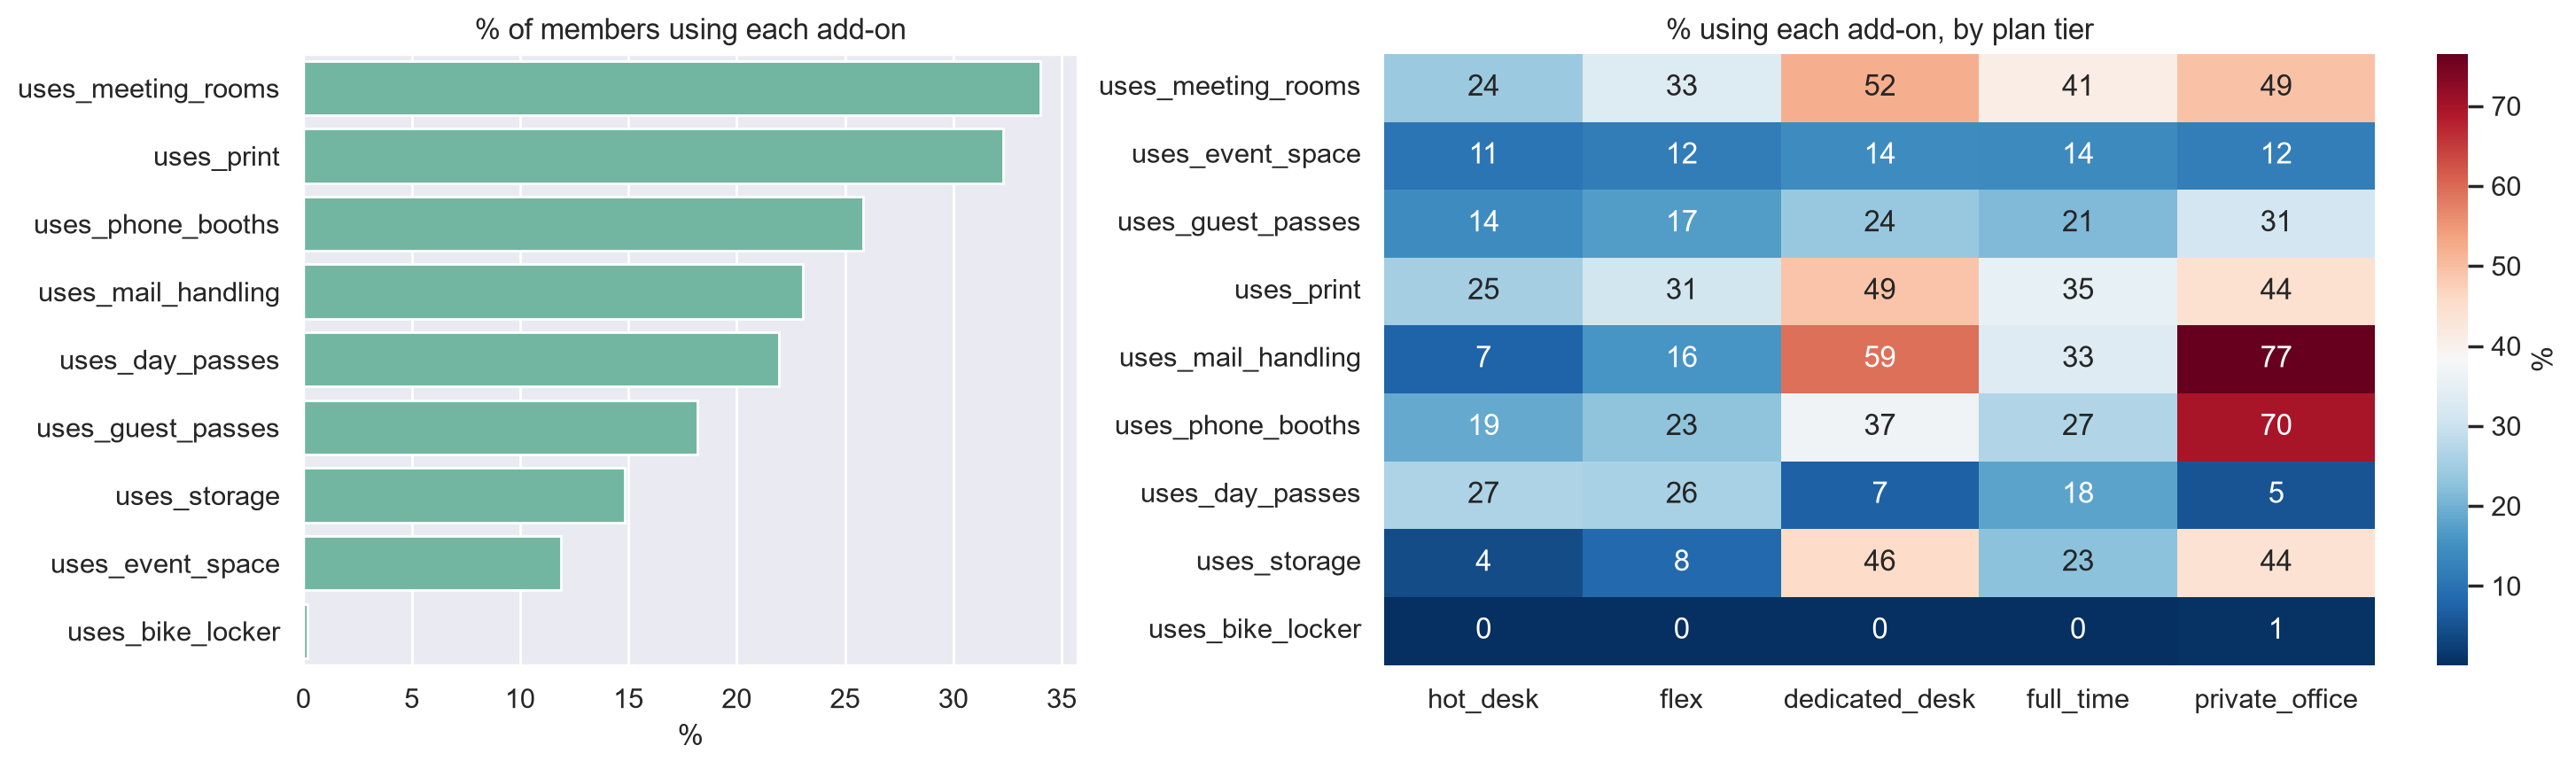

In [88]:
# How popular is each add-on, and how does it differ by plan?
addon_pct = (df[addon_cols].fillna(False).astype(bool).mean() * 100).sort_values(ascending=False)
addon_by_plan = (df.groupby("plan_tier")[addon_cols]
                    .apply(lambda g: g.fillna(False).astype(bool).mean() * 100)
                    .reindex(PLAN_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
sns.barplot(x=addon_pct.values, y=addon_pct.index, ax=axes[0])
axes[0].set_title("% of members using each add-on"); axes[0].set_xlabel("%"); axes[0].set_ylabel("")
sns.heatmap(addon_by_plan.T, annot=True, fmt=".0f", cmap="RdBu_r", ax=axes[1], cbar_kws={"label": "%"})
axes[1].set_title("% using each add-on, by plan tier"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

In [89]:
# Do members who use more add-ons bring more value?
(df.groupby("n_addons")
    .agg(n_members=("member_id", "count"), median_ltv=("lifetime_value", "median"),
         median_weekly_visits=("avg_weekly_visits", "median"))
    .round(1))

,n_members,median_ltv,median_weekly_visits
n_addons,,,
0,3087,317.30,0.90
1,4643,435.00,1.00
2,3236,1465.90,1.80
3,2139,3753.80,2.00
4,1395,6905.00,2.30
5,690,9411.90,3.60
6,223,9979.70,3.80
7,34,13054.30,4.00
8,3,20047.10,1.20


### Insights
- **Adoption by plan:** the add-ons are more used in the expensive plans (median of 3 add-ons for `dedicated_desk` and `private_office`, 1 for `hot_desk` and `flex`).
- **Add-ons and value:** the median lifetime value grows from 317 euros (no add-on) to 435 euros (1), 1,466 euros (2), 3,754 euros (3), 6,905 euros (4) and 9,412 euros (5), and the weekly visits from 0.9 to 3.6. The number of add-ons marks the involvement of the member. Caution: members with more tenure also had more time to try add-ons, so part of this relation is a time effect.

### 6.5 Correlations (Pearson, extreme values hidden)

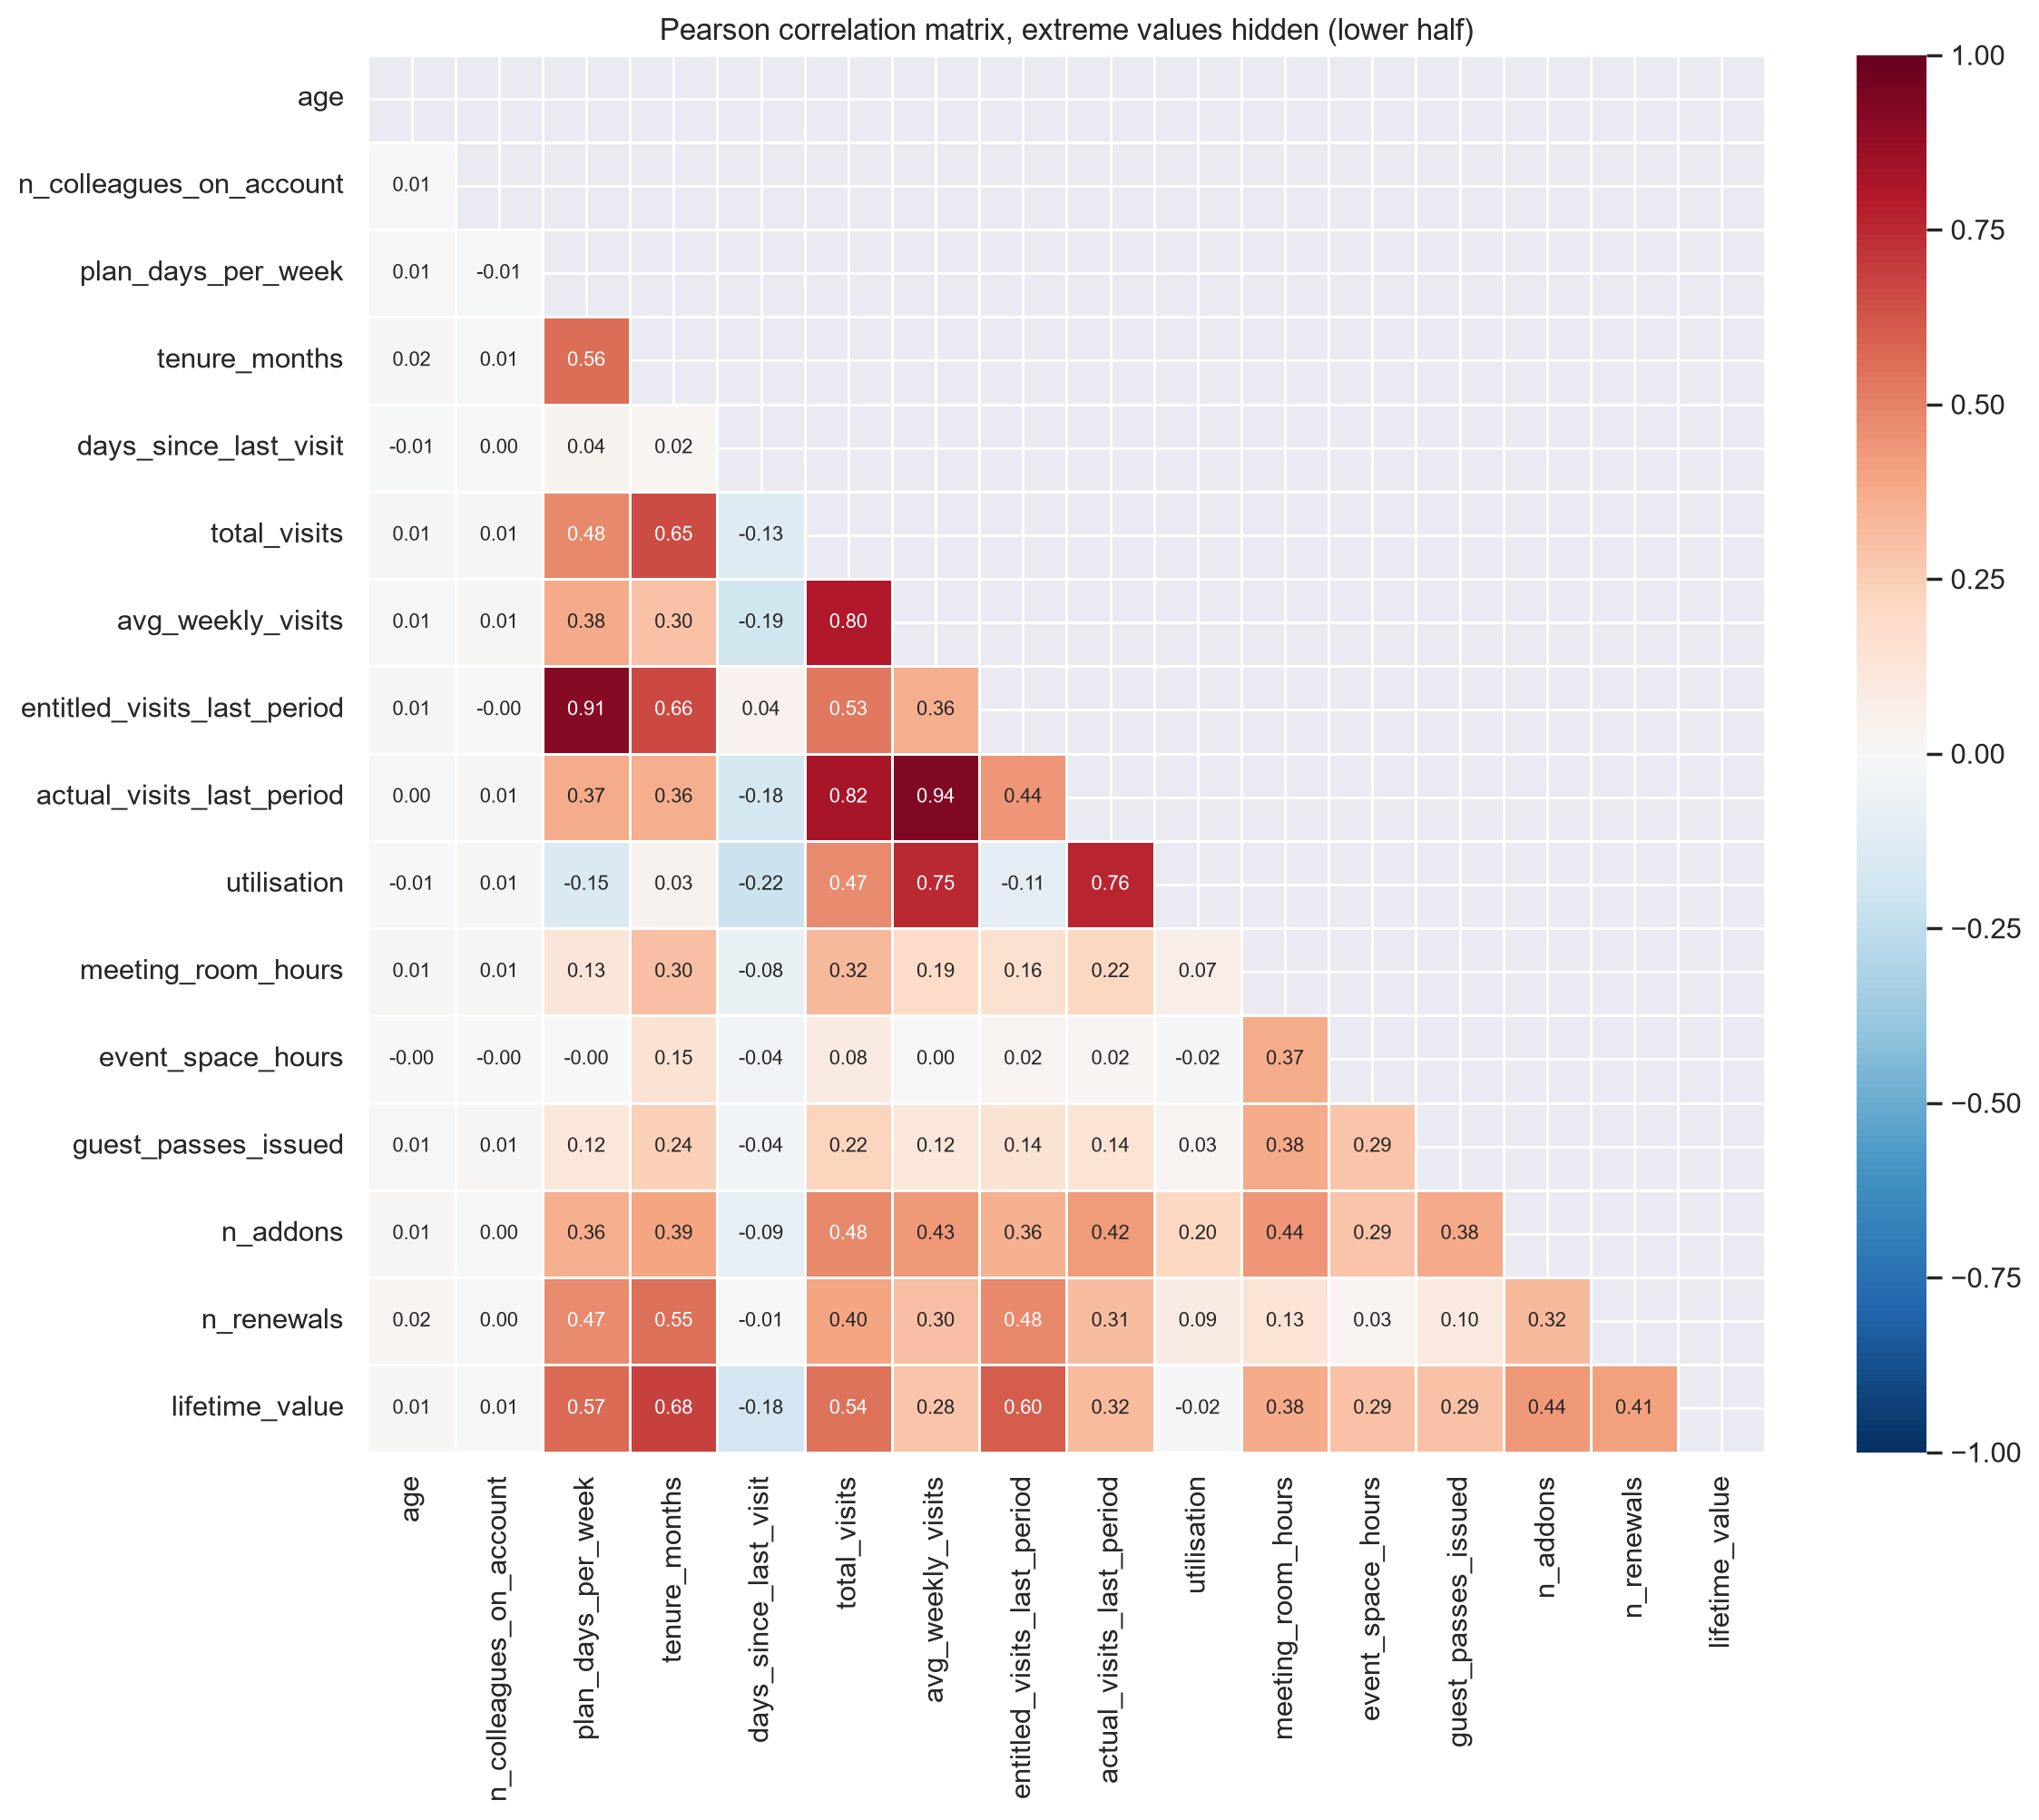

In [90]:
corr_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "tenure_months", "days_since_last_visit",
             "total_visits", "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
             "utilisation", "meeting_room_hours", "event_space_hours", "guest_passes_issued",
             "n_addons", "n_renewals", "lifetime_value"]

# Pearson correlation (as in the labs), computed on the plot-only copy eda,
# where the impossible and extreme values are hidden, so that a few errors do not distort it
corr = eda[corr_cols].corr()

# Show only the lower half (the matrix is symmetric)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, annot_kws={"size": 8}, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=.5)
plt.title("Pearson correlation matrix, extreme values hidden (lower half)")
plt.show()

In [91]:
# The strongest pairs, in a table
pairs = corr.where(~mask).stack().rename("pearson").reset_index()
pairs.columns = ["var_1", "var_2", "pearson"]
pairs["abs"] = pairs["pearson"].abs()
pairs.sort_values("abs", ascending=False).head(12).drop(columns="abs").round(2)

,var_1,var_2,pearson
134,actual_visits_last_period,avg_weekly_visits,0.94
114,entitled_visits_last_period,plan_days_per_week,0.91
133,actual_visits_last_period,total_visits,0.82
101,avg_weekly_visits,total_visits,0.80
152,utilisation,actual_visits_last_period,0.76
150,utilisation,avg_weekly_visits,0.75
243,lifetime_value,tenure_months,0.68
115,entitled_visits_last_period,tenure_months,0.66
83,total_visits,tenure_months,0.65
247,lifetime_value,entitled_visits_last_period,0.60


This repeats the Pearson correlation matrix of the distributions section, but computed on the plot-only copy `eda`, where the impossible and extreme values are hidden. On `df`, a few errors (for example 41,220 meeting room hours) are enough to distort the coefficients.

### Insights
- **Strong pairs (|r| ≥ 0.7):** `actual_visits_last_period` and `avg_weekly_visits` (0.94), `entitled_visits_last_period` and `plan_days_per_week` (0.91), `actual_visits_last_period` and `total_visits` (0.82), `avg_weekly_visits` and `total_visits` (0.80), and `utilisation` with `actual_visits_last_period` (0.76) and with `avg_weekly_visits` (0.75, expected since it is built from them).
- **Redundancy:** these variables carry the same information. In a distance-based clustering, keeping all of them would give that information a multiple weight, so one per group should be kept.
- **Time effect:** the totals grow with the tenure (`lifetime_value` 0.68, `total_visits` 0.65, `n_renewals` 0.55), so they partly measure how long the member has been here.
- **Recency:** `days_since_last_visit` is only weakly related to the visits (-0.19) and to the utilization (-0.22).
- **Limit of the coefficient:** a low correlation doesn't mean there is no relationship (see the key pairs in 6.6).

### 6.6 Key pairs: is the correlation enough?
A correlation coefficient only measures one kind of relationship. A low value can hide a clear structure (two groups, a curve), so for a few pairs that matter for the business we look at the points themselves. We use hexbin plots, which work better than scatter plots when there are many members (the color shows how many members fall in each cell, on a log scale). Extreme values hidden; `lifetime_value` is shown as log(1 + value) because it is very skewed.

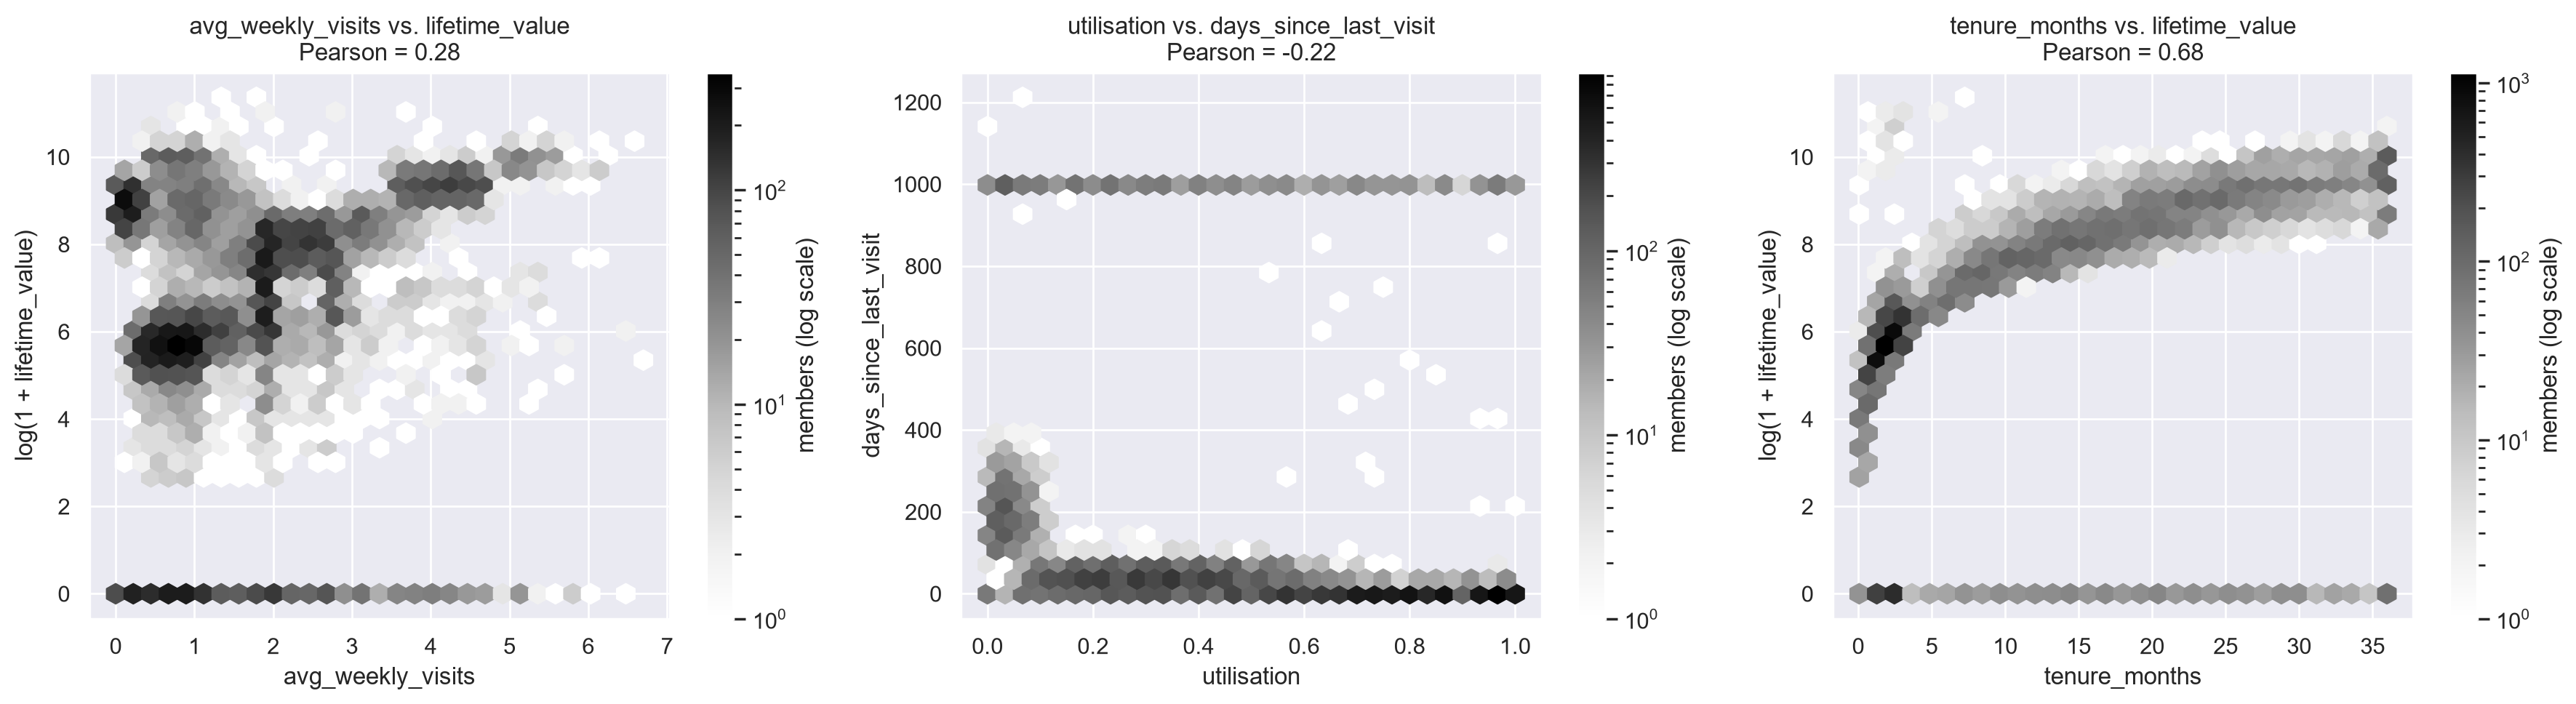

In [92]:
pairs_to_plot = [("avg_weekly_visits", "lifetime_value", True),
                 ("utilisation", "days_since_last_visit", False),
                 ("tenure_months", "lifetime_value", True)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (xc, yc, logy) in zip(axes, pairs_to_plot):
    d = eda[[xc, yc]].dropna()                     # plot-only copy: extremes hidden
    r = d[xc].corr(d[yc])                          # Pearson, same values as the matrix above
    x = d[xc]
    y = np.log1p(d[yc]) if logy else d[yc]
    hb = ax.hexbin(x, y, gridsize=30, cmap="Greys", bins="log", mincnt=1)
    ax.set_title(f"{xc} vs. {yc}\nPearson = {r:.2f}")
    ax.set_xlabel(xc)
    ax.set_ylabel(f"log(1 + {yc})" if logy else yc)
    fig.colorbar(hb, ax=ax, label="members (log scale)")
plt.tight_layout()
plt.show()

### Insights
- **`avg_weekly_visits` vs. `lifetime_value` (r = 0.28):** the coefficient is low, but the hexbin shows several separate dense areas and not one smooth cloud, so it hides structure (probably the different plans). There is also a line at `lifetime_value` = 0 across all visit levels.
- **`utilisation` vs. `days_since_last_visit` (r = -0.22):** the plot has two blocks: most members visited in the last ~100 days, and a horizontal line at about 1,000 days. This line is the code 999 and it appears at all levels of utilization, so it isn't linked to low use; it should be handled as a code for "no visit recorded", not as a real number of days. Members who use less than about 10% of their plan are spread up to about 400 days since the last visit.
- **`tenure_months` vs. `lifetime_value` (r = 0.68):** the relation isn't linear. The value grows quickly in the first months and then much more slowly. The line at `lifetime_value` = 0 appears at all tenures, so a zero isn't only "new member"; it may be a missing value coded as 0.
- **Potential bivariate outliers:** a few isolated cells with a short tenure but a very high value, and with several hundred days since the last visit but high utilization.
- **For segmentation:** the separate dense areas in the first plot suggest groups of members, while tenure and value behave as a continuous curve.

## 7. Which variables look most relevant for segmentation?

In [93]:
num_vars = ["age", "n_colleagues_on_account", "plan_days_per_week", "tenure_months", "days_since_last_visit",
            "total_visits", "avg_weekly_visits", "utilisation", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_addons", "n_renewals", "lifetime_value"]

# Correlations without the diagonal (a variable always has correlation 1 with itself)
corr_abs = corr.loc[num_vars, num_vars].abs()
for v in num_vars:
    corr_abs.loc[v, v] = np.nan

# Share of each variable explained by the plan (0 = nothing, 1 = everything)
# = variation BETWEEN the plans / TOTAL variation, computed on eda so that the extreme values do not dominate
share_by_plan = []
for v in num_vars:
    data = pd.DataFrame({"value": eda[v], "plan": eda["plan_tier"]}).dropna()
    overall_mean = data["value"].mean()
    plan_means = data.groupby("plan")["value"].mean()
    plan_sizes = data.groupby("plan")["value"].count()
    between = (plan_sizes * (plan_means - overall_mean) ** 2).sum()
    total = ((data["value"] - overall_mean) ** 2).sum()
    share_by_plan.append(between / total)

rel = pd.DataFrame({
    "pct_missing_in_df": df[num_vars].isna().mean() * 100,  # original df
    "skew": df[num_vars].skew(),
    "pct_zero": (df[num_vars] == 0).mean() * 100,
    # how redundant: highest absolute correlation with another variable
    "max_abs_corr_other": corr_abs.max(),
    # how much does the variable differ between plans? (share of variance explained by the plan)
    "share_explained_by_plan": pd.Series(share_by_plan, index=num_vars),
}).round(2)
rel.sort_values("share_explained_by_plan", ascending=False)

,pct_missing_in_df,skew,pct_zero,max_abs_corr_other,share_explained_by_plan
plan_days_per_week,0.00,0.93,0.28,0.57,0.98
lifetime_value,6.73,30.79,11.28,0.68,0.40
tenure_months,0.98,0.65,0.00,0.68,0.36
total_visits,0.00,6.82,0.71,0.80,0.29
n_renewals,0.00,1.34,50.11,0.55,0.25
avg_weekly_visits,0.00,10.27,0.09,0.80,0.17
n_addons,0.00,0.77,19.98,0.48,0.14
utilisation,0.06,-0.04,1.89,0.75,0.04
meeting_room_hours,8.38,70.80,59.82,0.44,0.02
guest_passes_issued,8.21,7.01,75.71,0.38,0.01


In [94]:
# Categorical variables: how balanced are they?
for col in ["gender", "country", "industry", "plan_tier", "is_team_account"]:
    shares = df[col].fillna("missing").value_counts(normalize=True) * 100
    print(f"{col:16s} {df[col].nunique():2d} categories | largest: {shares.index[0]} ({shares.iloc[0]:.0f}%)")

gender            3 categories | largest: female (51%)
country           8 categories | largest: portugal (68%)
industry         11 categories | largest: information technology (23%)
plan_tier         5 categories | largest: flex (35%)
is_team_account   2 categories | largest: False (72%)


**How to read the table:** a good segmentation variable (1) has few missing values, (2) varies enough between members, (3) isn't a copy of another variable (`max_abs_corr_other` not close to 1), and (4) is meaningful for the business. A high `share_explained_by_plan` means the variable mostly repeats the plan, so it adds little beyond `plan_tier` (`plan_days_per_week`: 0.98). A **low** value means it separates members *within* the same plan, which is where different types of members can appear (`utilisation` 0.04, `avg_weekly_visits` 0.17, `meeting_room_hours` 0.02, `days_since_last_visit` 0.00).

### Shortlist (based on the tables and charts above)

| Group of variables | Variables | Why |
|---|---|---|
| **Value & commitment** | `plan_tier`, `lifetime_value`, `n_renewals` | What the member pays and how loyal they are. `plan_tier` should not be coded 1 to 5 (the order is not the metadata order) |
| **Engagement** | `avg_weekly_visits`, `utilisation`, `days_since_last_visit` (after handling the code 999) | How much the member really uses the space. They vary a lot within the same plan |
| **Services** | the `uses_*` add-on flags (or `n_addons`), `meeting_room_hours` | Use beyond the desk; separates "desk only" from "full service" members. `event_space_hours` (89% zeros) and `guest_passes_issued` (76% zeros) are better as yes/no flags |
| **Weak or secondary** | `gender`, `country`, `age`, `industry`, `is_team_account`, `n_colleagues_on_account` | `gender` is balanced and carries little signal, `country` is dominated by one country (68%), `industry` has an "unknown" category, `age` is symmetric but not related to the other variables, and teams and individuals behave the same (6.3). Better used to **describe** the groups afterwards |
| **Redundant** | `plan_days_per_week` (copy of the plan), `actual_visits_last_period` and `total_visits` (next to `avg_weekly_visits`), `entitled_visits_last_period` (next to `plan_days_per_week`) | Strongly related (see correlations), so they carry the same information twice |

**Note:** totals such as `total_visits`, `lifetime_value` and `n_renewals` grow with the time spent in the club, so they partly measure *how long* the member has been here and not *how* they behave. This is flagged here and left for the feature-engineering task (see section 9).

## 8. Missing values: how many and why?
We report how many values are missing in each original variable and look for the reason. **No value is imputed here**: the missing values stay as they are in `df`. We also list the "hidden" missing values, those that are written as a code and not as an empty cell. The helper columns created above are left out.

,n_missing,pct_missing
meeting_room_hours,1295,8.40
guest_passes_issued,1269,8.20
lifetime_value,1040,6.70
age,557,3.60
gender,530,3.40
country,429,2.80
plan_tier,105,0.70


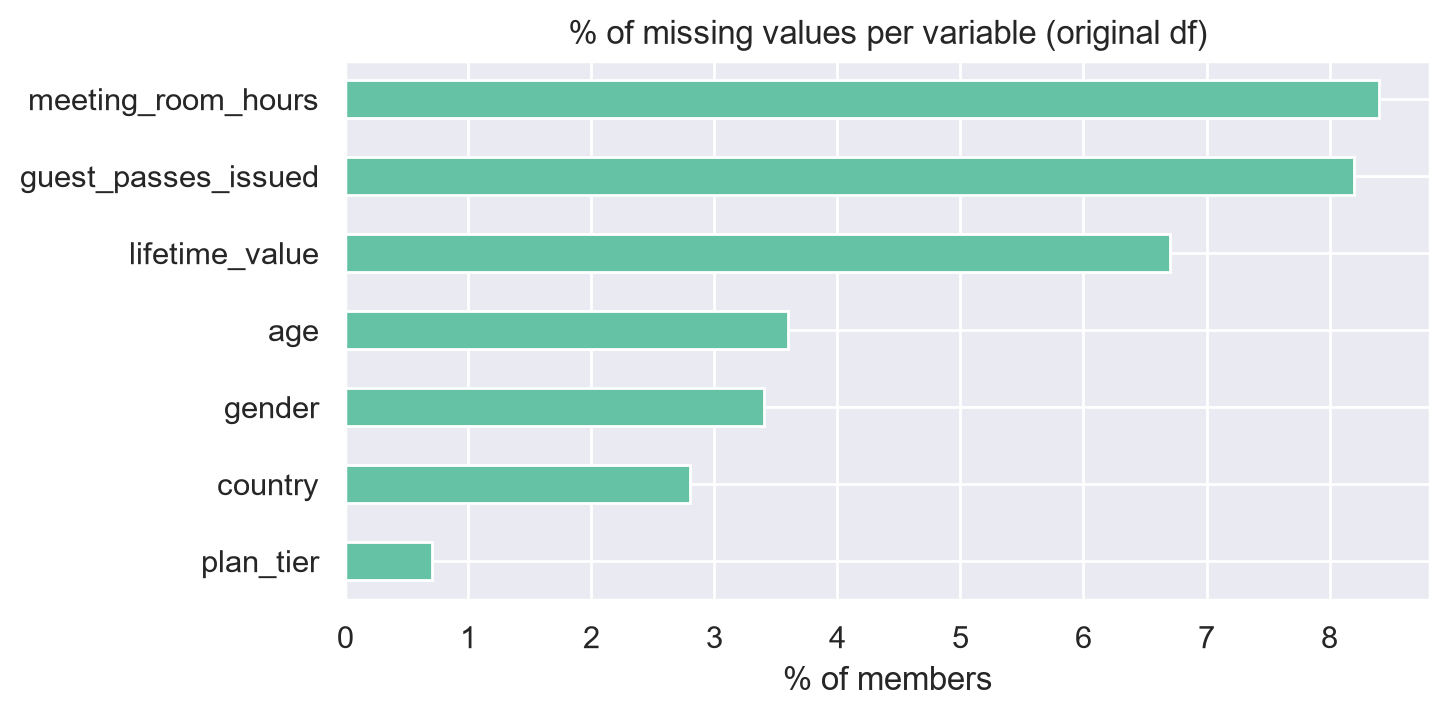

,variable,by,lowest_%,highest_%
0,meeting_room_hours,plan_tier,1.70,11.70
1,meeting_room_hours,start_year,7.70,9.70
2,meeting_room_hours,is_team_account,8.20,8.90
3,meeting_room_hours,is_active,6.70,9.00
4,guest_passes_issued,plan_tier,2.30,10.80
5,guest_passes_issued,start_year,7.60,9.00
6,guest_passes_issued,is_team_account,7.90,8.40
7,guest_passes_issued,is_active,6.60,8.80
8,lifetime_value,plan_tier,4.70,10.80
9,lifetime_value,start_year,3.70,7.90


meeting_room_hours missing vs. uses_meeting_rooms


uses_meeting_rooms,False,True
hours missing,,
False,9290,4865
True,902,393


guest_passes_issued missing vs. uses_guest_passes


uses_guest_passes,False,True
passes missing,,
False,11573,2608
True,1066,203


meeting_room_hours and guest_passes_issued missing together?


passes missing,False,True
hours missing,,
False,13045,1110
True,1136,159


Number of missing values per member (original variables):


0    11086
1     3581
2      705
3       78
Name: count, dtype: int64

,n_members,pct
industry == 'unknown',693,4.50
n_colleagues_on_account == -1,565,3.70
days_since_last_visit >= 999 (possible code),1304,8.40
membership_end == 1970-01-01 (no end date),3954,25.60
lifetime_value == 0,1742,11.30


In [95]:
helper_cols = ["is_active", "tenure_months", "utilisation", "n_addons", "start_year"]
orig = df.drop(columns=helper_cols)

# 1) How many values are missing in each original variable?
miss = pd.DataFrame({"n_missing": orig.isna().sum()})
miss["pct_missing"] = (miss["n_missing"] / len(orig) * 100).round(1)
miss = miss[miss["n_missing"] > 0].sort_values("n_missing", ascending=False)
display(miss)

miss["pct_missing"].sort_values().plot(kind="barh", figsize=(7, 3.5))
plt.title("% of missing values per variable (original df)")
plt.xlabel("% of members")
plt.show()

# 2) Do the members with a missing value have something in common? (lowest and highest % missing across the groups)
rows = []
for v in miss.index:
    flag = df[v].isna()
    for g in ["plan_tier", "start_year", "is_team_account", "is_active"]:
        rate = flag.groupby(df[g]).mean() * 100
        rows.append({"variable": v, "by": g, "lowest_%": rate.min(), "highest_%": rate.max()})
display(pd.DataFrame(rows).round(1))

# 3) Link with the yes/no variables of the same service
print("meeting_room_hours missing vs. uses_meeting_rooms")
display(pd.crosstab(df["meeting_room_hours"].isna(), df["uses_meeting_rooms"], dropna=False,
                    rownames=["hours missing"], colnames=["uses_meeting_rooms"]))
print("guest_passes_issued missing vs. uses_guest_passes")
display(pd.crosstab(df["guest_passes_issued"].isna(), df["uses_guest_passes"], dropna=False,
                    rownames=["passes missing"], colnames=["uses_guest_passes"]))

# 4) Are values missing together in the same members?
print("meeting_room_hours and guest_passes_issued missing together?")
display(pd.crosstab(df["meeting_room_hours"].isna(), df["guest_passes_issued"].isna(),
                    rownames=["hours missing"], colnames=["passes missing"]))
print("Number of missing values per member (original variables):")
display(orig.isna().sum(axis=1).value_counts().sort_index())

# 5) Hidden missing values: codes written as normal values
hidden_codes = pd.Series({
    "industry == 'unknown'": (df["industry"] == "unknown").sum(),
    "n_colleagues_on_account == -1": (df["n_colleagues_on_account"] == -1).sum(),
    "days_since_last_visit >= 999 (possible code)": (df["days_since_last_visit"] >= 999).sum(),
    "membership_end == 1970-01-01 (no end date)": df["is_active"].sum(),
    "lifetime_value == 0": (df["lifetime_value"] == 0).sum(),
})
pd.DataFrame({"n_members": hidden_codes, "pct": (hidden_codes / len(df) * 100).round(1)})

**How many:** the variables with empty cells are, from the largest share, `meeting_room_hours` (8.4%), `guest_passes_issued` (8.2%), `lifetime_value` (6.7%) and `age` (3.6%); the others are below that (see the first table). On top of these, some missing values are hidden as codes: `industry` = "unknown" (4.5%), `n_colleagues_on_account` = -1 (565 members), `days_since_last_visit` around 999, the end date 1970-01-01 (3,954 members, possibly indicating an open-ended membership, but not yet confirmed).

**Why values might be missing:**

We checked whether missing values are related to membership plans, start years, team accounts and membership status.

The missing rates differ between some groups, so we cannot simply assume that the values are missing completely at random (MCAR). Missing at Random (MAR) could be possible if the missing values are explained by other observed variables. However, we cannot confirm MAR or rule out Missing Not at Random (MNAR) based on our analysis.

For meeting_room_hours and guest_passes_issued, missing values may sometimes indicate that a service wasn't used. However, missing values also occur for members flagged as using these services.

**Decision**

We haven't imputed any missing values in this EDA. Before clustering, we need to decide how to handle them based on the variable and the possible reason for the missing data. Median or group-based imputation could be considered for numerical variables, but we should also check whether these choices affect the clustering results.

For example, median imputation could be considered for age, as it's less affected by outliers. For meeting_room_hours and guest_passes_issued, we first need to check whether missing values mean that the service wasn't used or whether the information was simply not recorded. For lifetime_value, we should investigate missing values before choosing an imputation method, since this variable is important for value-based segmentation.

We shouldn't use the same imputation method for every variable.

## 9. Features to engineer for the clustering (proposals)
The totals (`total_visits`, `lifetime_value`, `n_renewals`) mostly measure how long the member has been in the club, and many variables are very skewed or have few distinct values. These are the new variables we propose, and why. In the Feature Engineering section at the end we build `ltv_per_month` and `ltv_per_visit` and reuse the three helper columns. `visits_per_month` was discarded because it repeats `avg_weekly_visits` (see the end of Part 3).

| Proposed variable | How | Why |
|---|---|---|
| `tenure_months`, `utilisation`, `n_addons` (already created) | see "Helper columns" | Time in the club, share of the plan used and breadth of services: three simple measures that separate the members, and that vary within a plan |
| `visits_per_month` (discarded) | `total_visits / tenure_months` | Not kept: `avg_weekly_visits` already gives the visit rate without the time effect (`total_visits` correlates 0.65 with tenure) |
| `ltv_per_month` | `lifetime_value / tenure_months` | Value per month, comparable between new and old members. `lifetime_value` correlates 0.68 with tenure |
| `ltv_per_visit` | `lifetime_value / total_visits` | Value of each visit, to separate heavy users from high spenders |
| `renewals_per_year` | `n_renewals / (tenure_months / 12)` | Loyalty without the time effect |
| `recent_visit` | `days_since_last_visit` below 30 days, after treating 999 as unknown | Simple recency signal. The raw variable has a block of about 1,000 days that is a code |
| `under_user` | `utilisation < 0.25` | Flags the about 25% of members who pay for a plan they hardly use; links to the private_office and full_time pattern |
| `uses_meeting`, `uses_event`, `uses_guest` flags (or `hours_per_month`) | `hours > 0` | These hours are 60% to 89% zeros, so "uses or not" is more informative than the hours |
| `plan_tier` encoding | by median value or by `plan_days_per_week`, or one-hot, not 1 to 5 | The data do not follow the order of the metadata |
| Grouped categories | `country` → Portugal vs. other; `industry` → a few groups | Avoid many tiny categories (country is 68% Portugal, industry has 11 categories) |
| Transformations | `log(1 + x)` and scaling for the skewed variables | Stops a few members from dominating k-means |

# Part 3: Feature engineering

## 1. Feature Engineering (Task 4)

We build five engineered features to describe member behavior and not only size: `utilisation` (actual / entitled visits), `n_addons` (number of add-ons), `tenure_months` (time as a member), `ltv_per_month` (`lifetime_value` / `tenure_months`) and `ltv_per_visit` (`lifetime_value` / `total_visits`). The first three are the helper columns from section 2; the last two are built here. Zero denominators are set to NaN and df_original stores a copy of the processed data before the two LTV ratios are added. These features aren't final and may change in D2.

In [96]:
non_metric_features = ["member_id", "gender", "industry", "country", "plan_tier",
                       "is_team_account", "uses_meeting_rooms", "uses_event_space",
                       "uses_guest_passes", "uses_print", "uses_mail_handling",
                       "uses_phone_booths", "uses_day_passes", "uses_storage",
                       "uses_bike_locker", "is_active", "start_year"]
date_features = ["membership_start", "membership_end", "last_badge_swipe"]
metric_features = df.columns.drop(non_metric_features + date_features).to_list()
df_original = df.copy()
df_eda = df.copy()

In [97]:
df_eda["ltv_per_month"] = df_eda["lifetime_value"] / df_eda["tenure_months"].replace(0, np.nan)
df_eda["ltv_per_visit"] = df_eda["lifetime_value"] / df_eda["total_visits"].replace(0, np.nan)

new_features = ["utilisation", "n_addons", "tenure_months", "ltv_per_month", "ltv_per_visit"]
for feat in new_features:
    if feat not in metric_features:
        metric_features.append(feat)

In [98]:
summary = df_eda[new_features].describe().round(2).T
summary["missing_%"] = (df_eda[new_features].isna().mean() * 100).round(1)
summary["skew"] = df_eda[new_features].skew().round(2)
summary

,count,mean,std,min,25%,50%,75%,max,missing_%,skew
utilisation,15440.00,0.52,0.31,0.00,0.24,0.52,0.80,1.00,0.10,-0.04
n_addons,15450.00,1.82,1.50,0.00,1.00,1.00,3.00,8.00,0.00,0.77
tenure_months,15298.00,12.31,11.13,0.07,2.14,9.28,20.93,35.97,1.00,0.65
ltv_per_month,14274.00,411.53,2805.71,-4100.38,128.10,190.13,305.79,93717.95,7.60,20.41
ltv_per_visit,14315.00,139.20,1116.41,-872.02,17.47,27.35,63.81,107874.75,7.30,66.57


In [99]:
# Examine extreme values of the LTV ratios
ratio_cols = ["ltv_per_month", "ltv_per_visit"]

df_eda[ratio_cols].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).T


,count,mean,std,min,50%,90%,95%,99%,max
ltv_per_month,14274.00,411.53,2805.71,-4100.38,190.13,456.45,675.01,915.19,93717.95
ltv_per_visit,14315.00,139.20,1116.41,-872.02,27.35,193.58,401.22,2114.07,107874.75


In [100]:

# Examine the 10 highest LTV per month values
df_eda.nlargest(10, "ltv_per_month")[
    ["lifetime_value", "tenure_months", "ltv_per_month"]
]


,lifetime_value,tenure_months,ltv_per_month
8454,3371260.00,35.97,93717.95
12903,2532335.00,30.35,83424.54
3231,5480.00,0.07,83405.60
9283,1712153.00,20.57,83255.49
3348,1044480.00,13.34,78310.27
1619,1861269.00,24.05,77400.31
13027,2084722.00,28.12,74134.27
12776,150829.00,2.17,69564.16
9717,2181450.00,32.10,67966.57
12378,1296617.00,21.62,59983.32


In [101]:

# Examine the 10 highest LTV per visit values
df_eda.nlargest(10, "ltv_per_visit")[
    ["lifetime_value", "total_visits", "ltv_per_visit"]
]


,lifetime_value,total_visits,ltv_per_visit
5008,431499.00,4,107874.75
12393,734531.00,23,31936.13
2089,480351.00,29,16563.83
3348,1044480.00,65,16068.92
6513,29094.00,2,14547.00
5830,14030.39,1,14030.39
9717,2181450.00,161,13549.38
8454,3371260.00,250,13485.04
978,66238.00,5,13247.60
11303,11539.36,1,11539.36


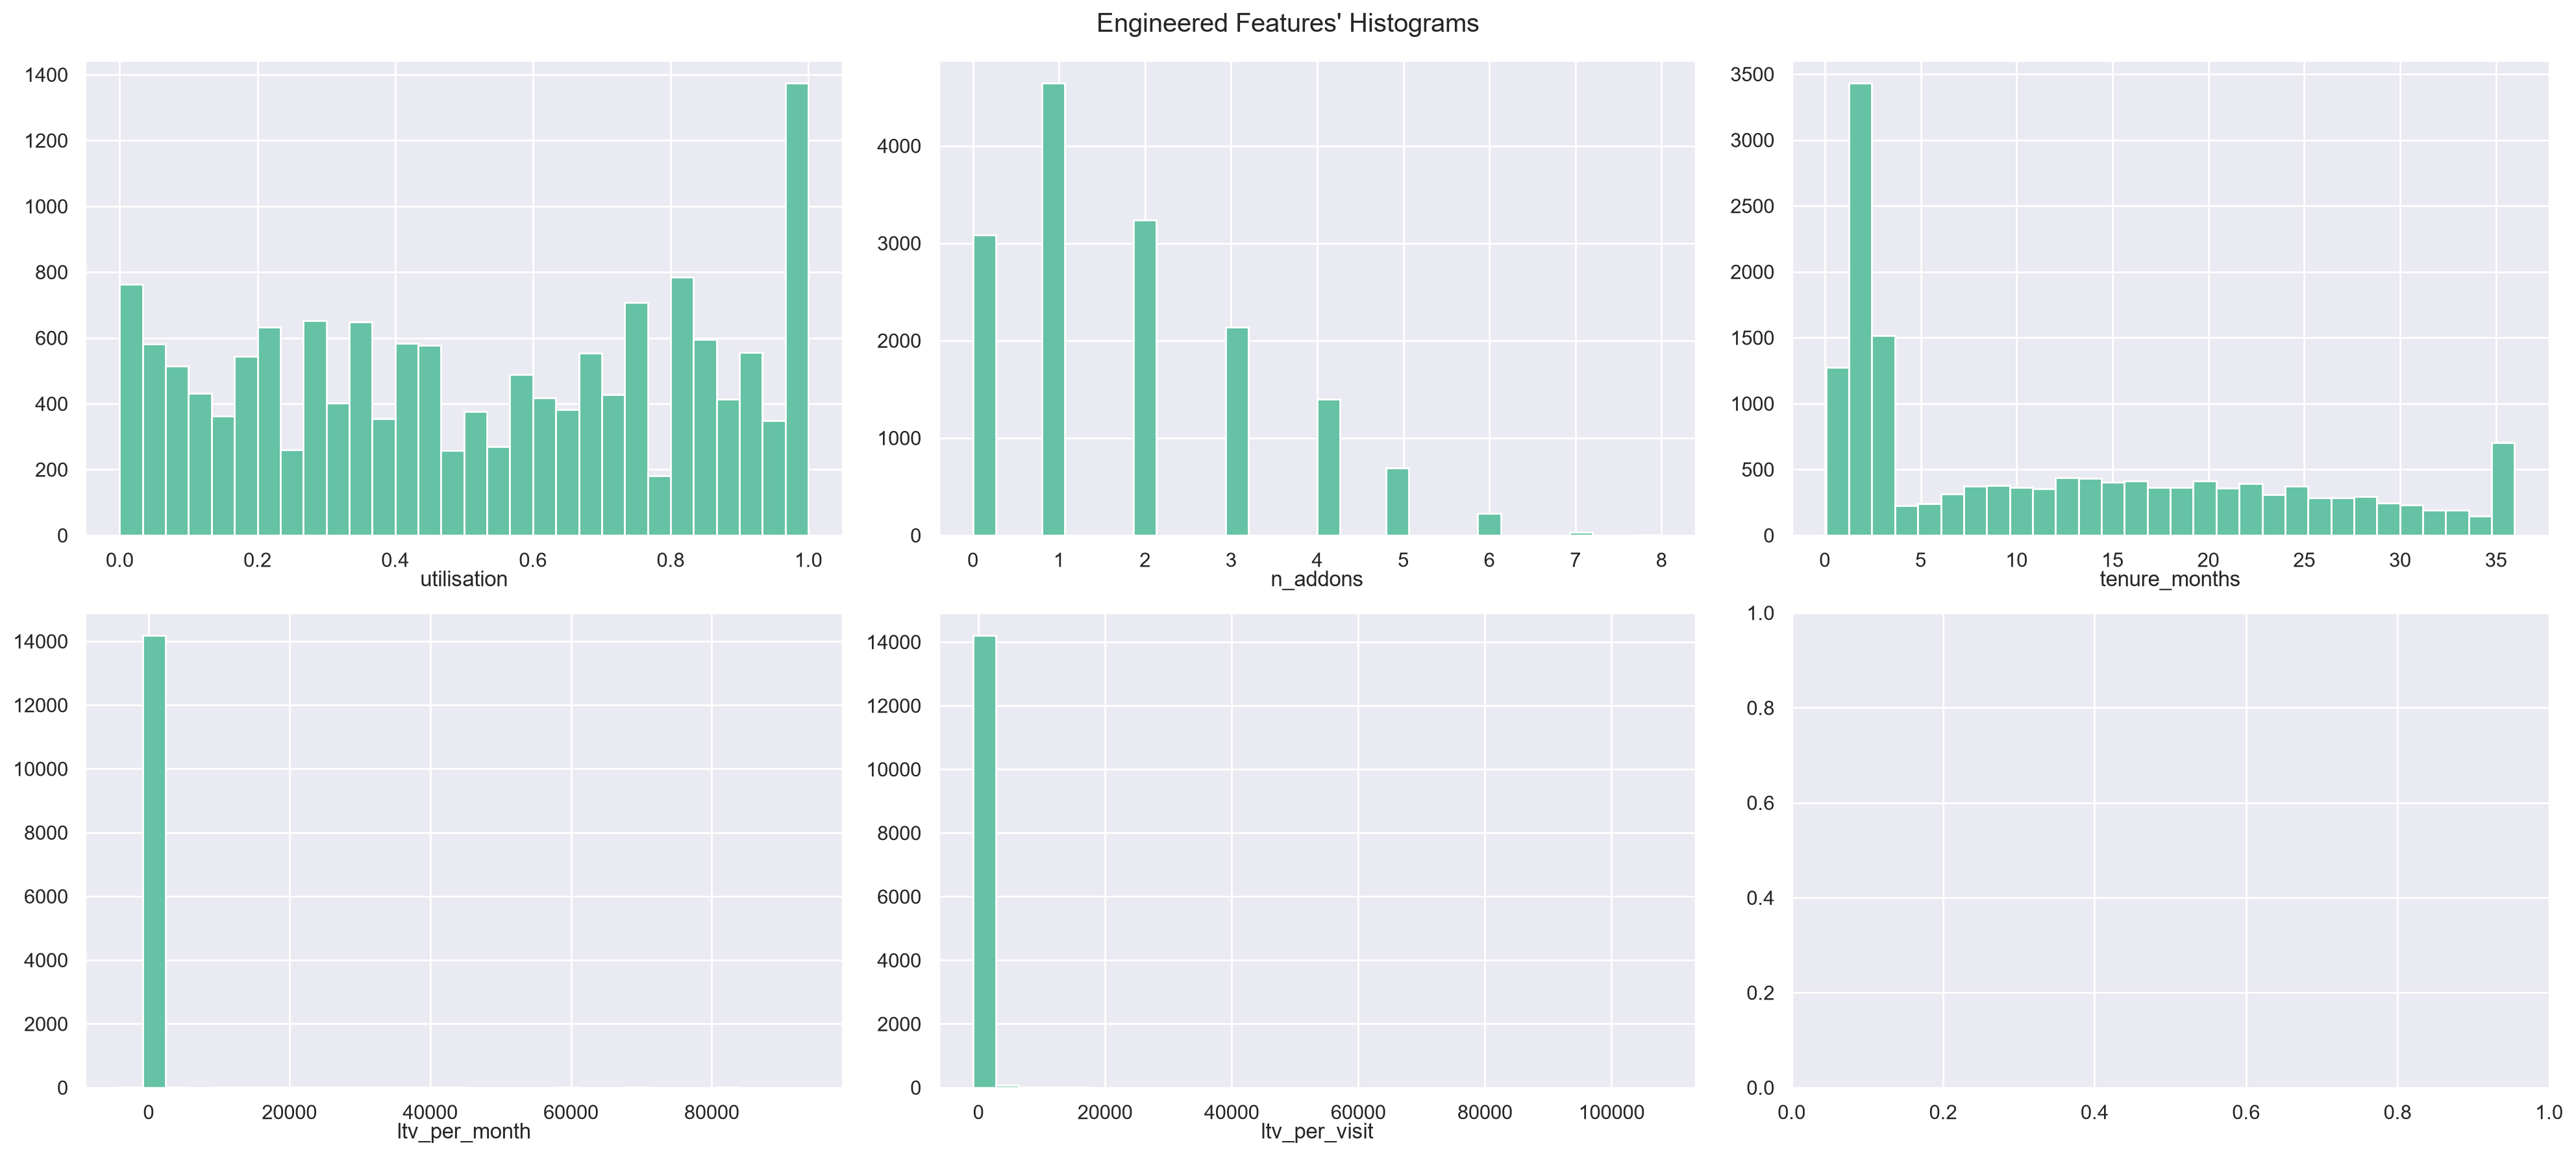

In [102]:
sp_rows = 2
sp_cols = ceil(len(new_features) / sp_rows)

fig, axes = plt.subplots(sp_rows, sp_cols, figsize=(20, 9), tight_layout=True)
for ax, feat in zip(axes.flatten(), new_features):
    ax.hist(df_eda[feat].replace([np.inf, -np.inf], np.nan).dropna(), bins=30)
    ax.set_title(feat, y=-0.13)
plt.suptitle("Engineered Features' Histograms")
plt.show()

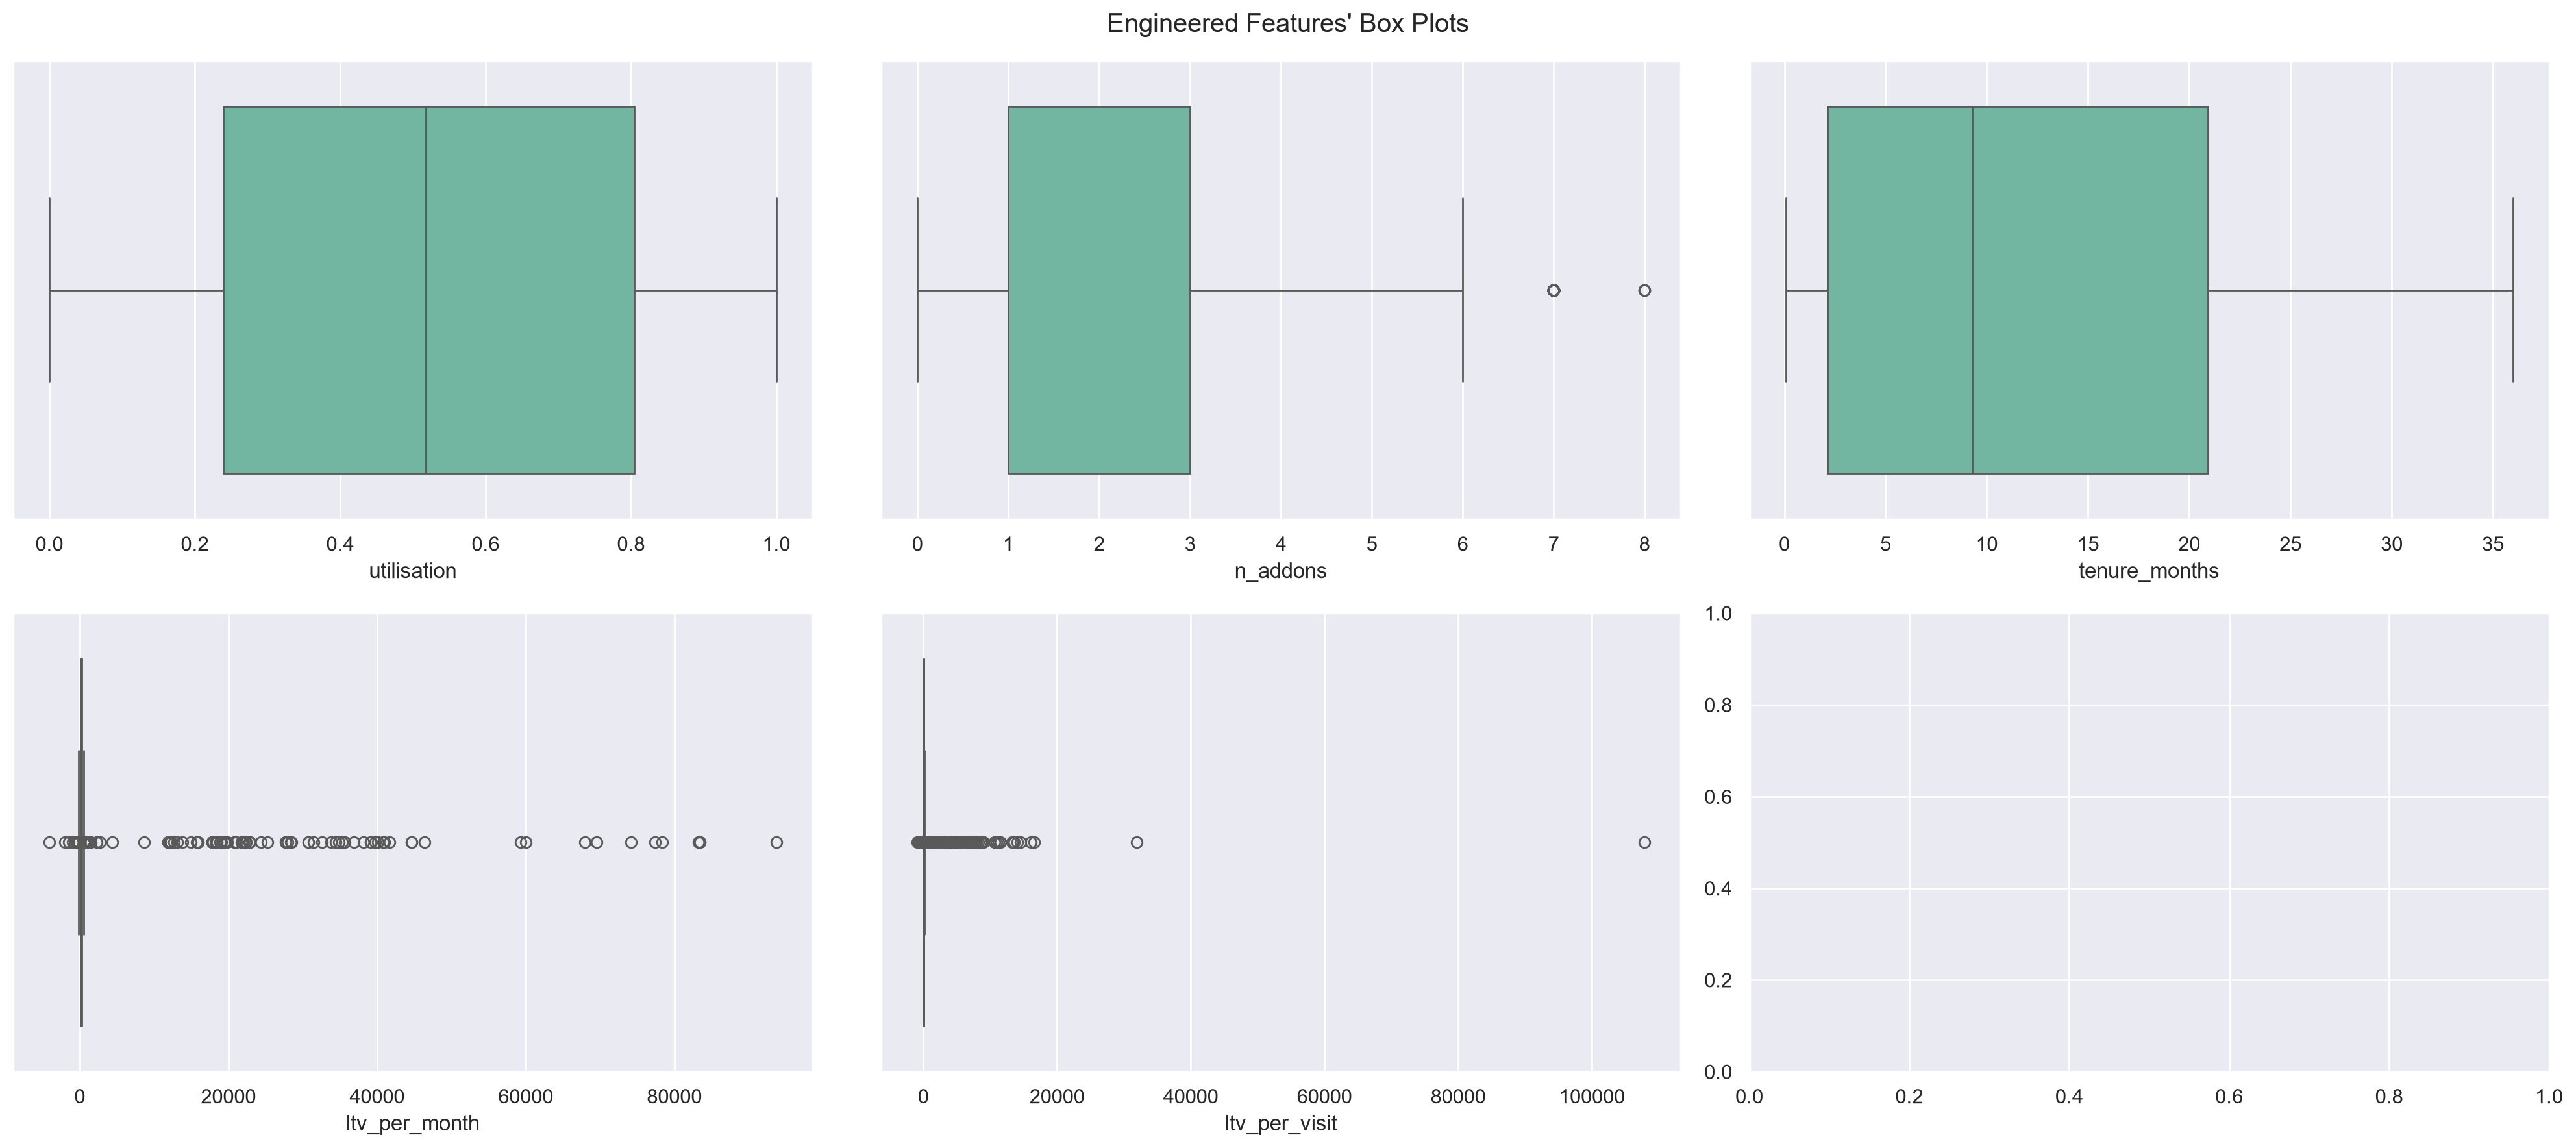

In [103]:
fig, axes = plt.subplots(sp_rows, sp_cols, figsize=(20, 9), tight_layout=True)
for ax, feat in zip(axes.flatten(), new_features):
    sns.boxplot(x=df_eda[feat].replace([np.inf, -np.inf], np.nan), ax=ax)
plt.suptitle("Engineered Features' Box Plots")
plt.show()

Utilization is almost symmetric (skew -0.04). `n_addons` (0.77) and `tenure_months` (0.65) are mildly right-skewed. `ltv_per_month` (skew 20.4) and `ltv_per_visit` (skew 66.6) are extremely right-skewed and have 7.6% and 7.3% missing values, where tenure or total visits is zero or missing.

`ltv_per_month` has 79 negative values and `ltv_per_visit` has 51. They come from negative `lifetime_value` in the raw data (see "Impossible values"). We keep and flag them in D1; they will be handled in D2 with the outlier treatment.

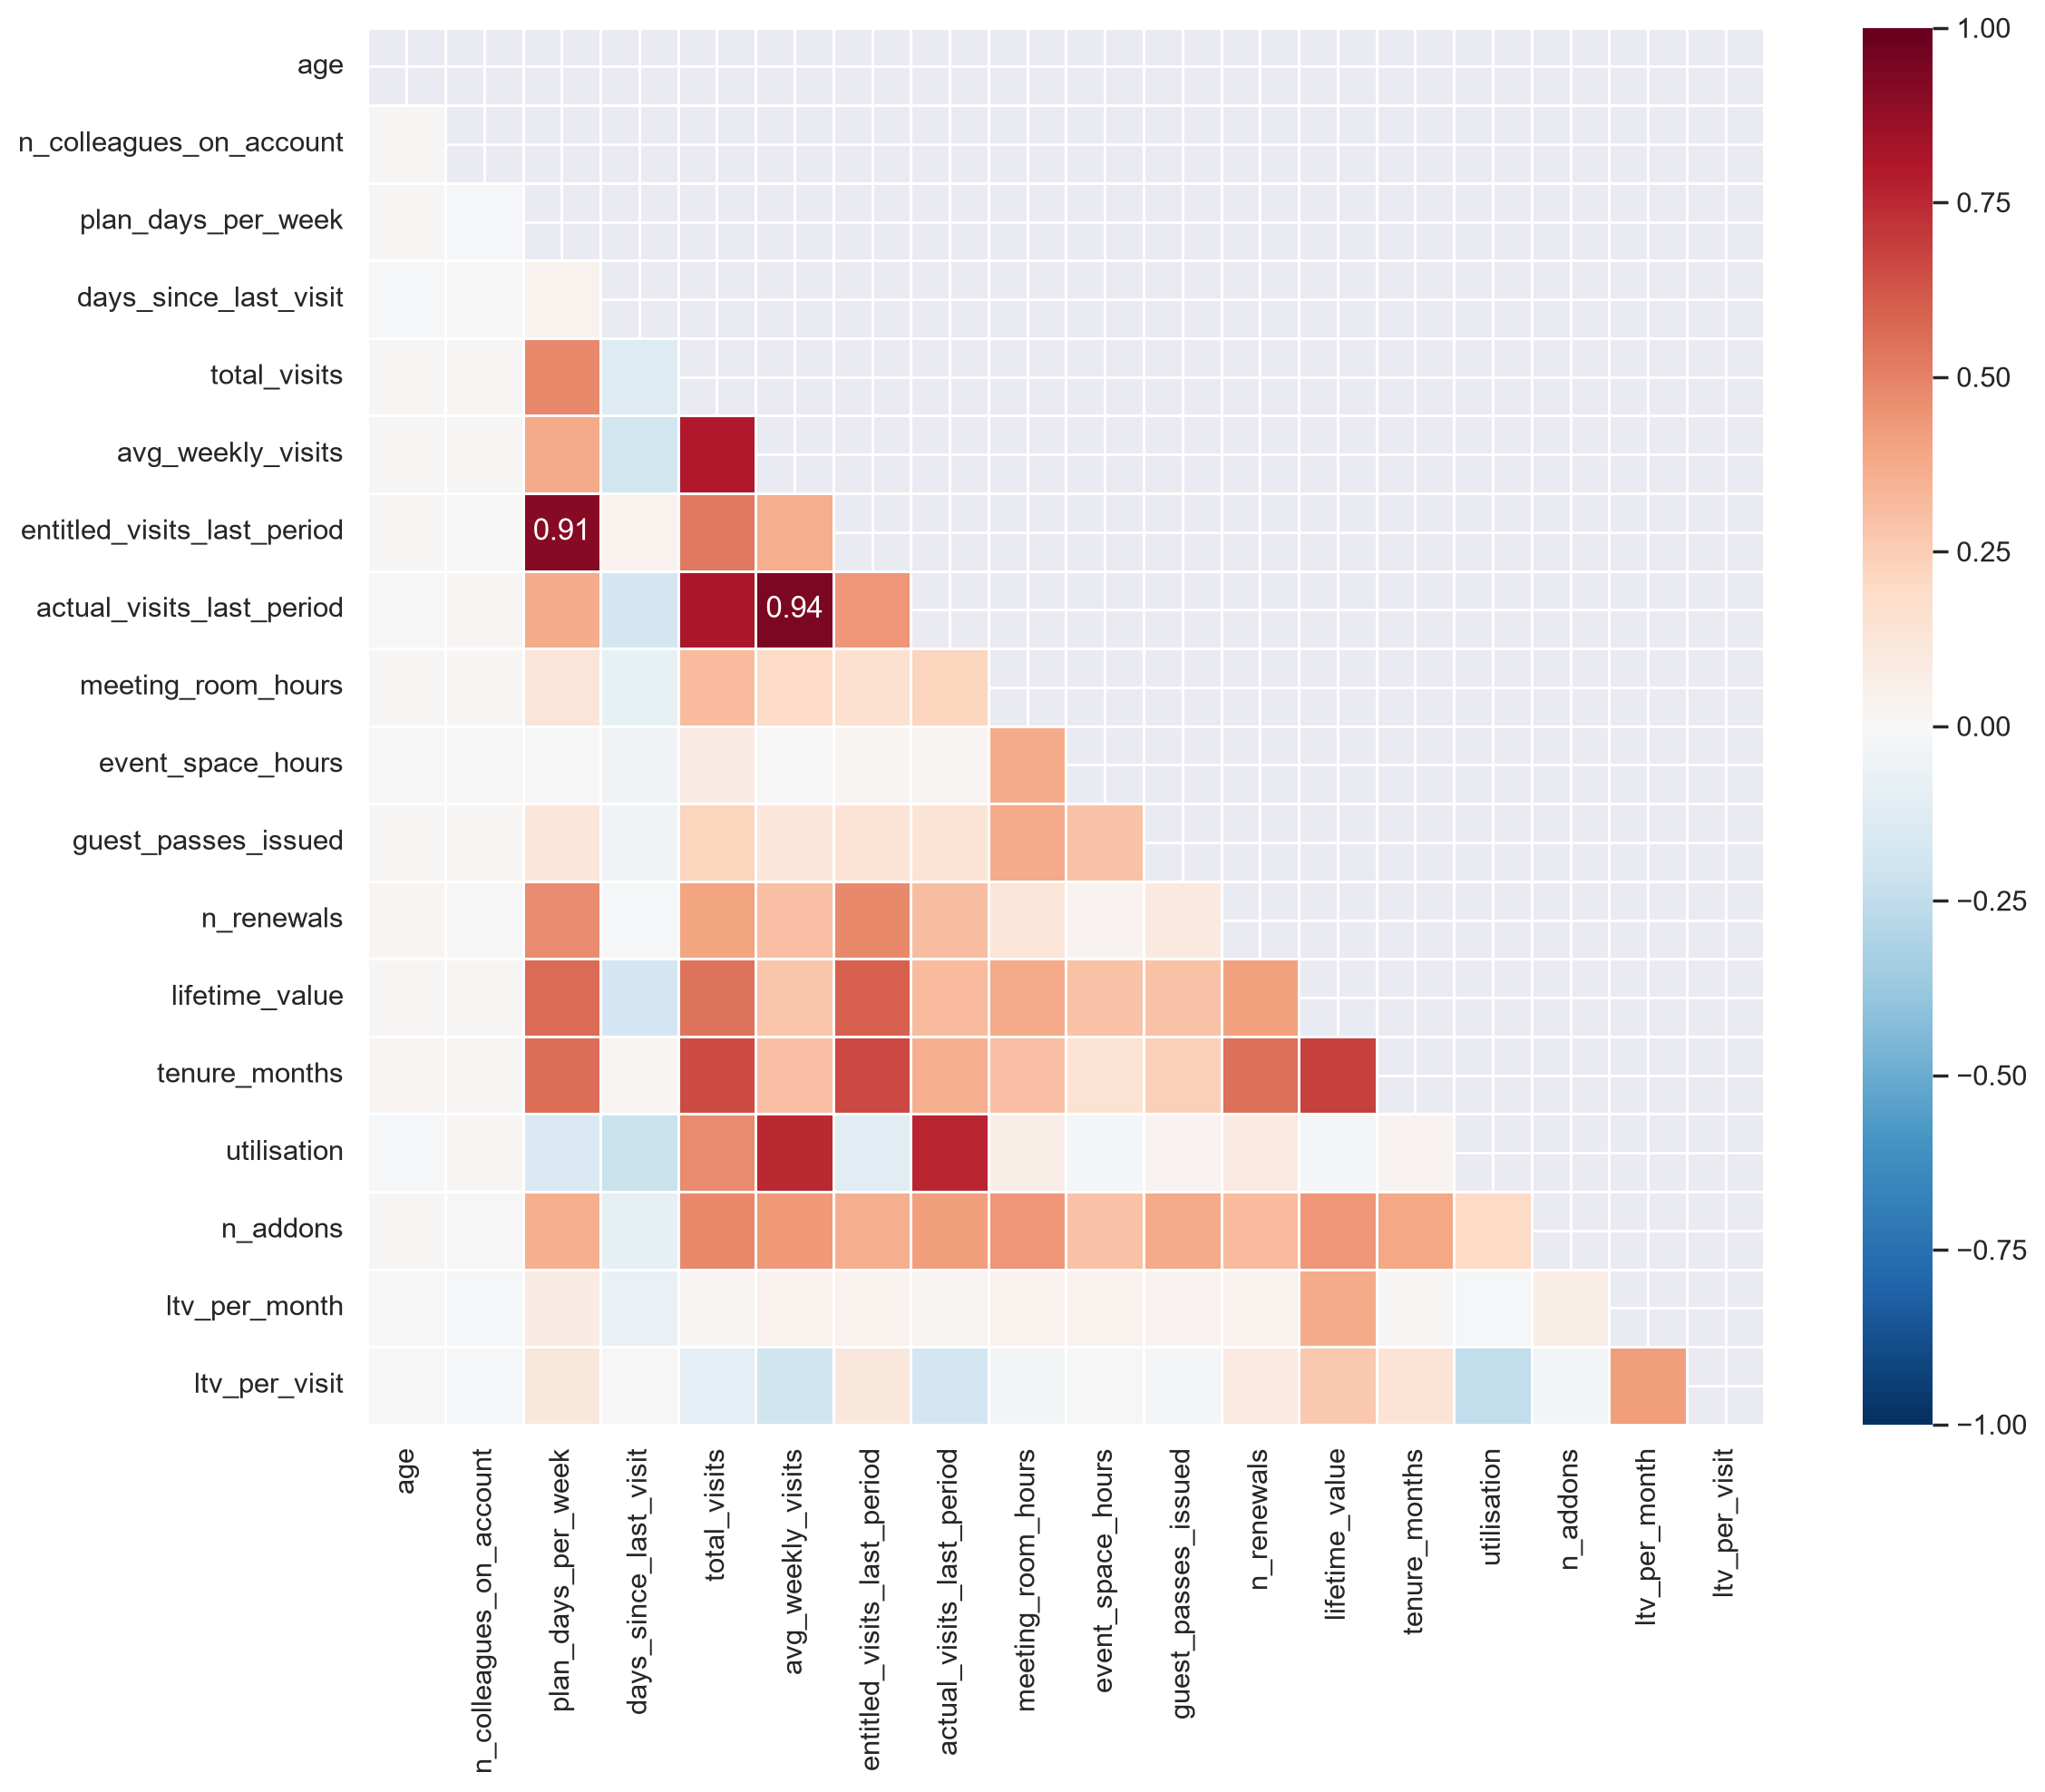

In [104]:
# Pearson correlation (as in the labs), computed with the same rules as the plot-only copy eda
# (impossible and extreme values hidden), so that a few errors do not distort it
corr_data = eda[[c for c in metric_features if c in eda.columns]].copy()
corr_data["ltv_per_month"] = eda["lifetime_value"] / eda["tenure_months"].replace(0, np.nan)
corr_data["ltv_per_visit"] = eda["lifetime_value"] / eda["total_visits"].replace(0, np.nan)
corr = corr_data[metric_features].corr()
corr = corr.round(2)

mask = np.triu(np.ones_like(corr, dtype=bool))
mask_annot = np.absolute(corr.values) >= 0.9
annot = np.where(mask_annot, corr.values, np.full(corr.shape, ""))

plt.figure(figsize=(14, 10))
sns.heatmap(corr, mask=mask, center=0, cmap="RdBu_r", annot=annot, fmt="s",
            vmin=-1, vmax=1, square=True, linewidths=.5)
plt.show()

In [105]:
# pairs with |corr| >= 0.9
pairs = corr.where(~mask).stack()
pairs[pairs.abs() >= 0.9]

entitled_visits_last_period  plan_days_per_week   0.91
actual_visits_last_period    avg_weekly_visits    0.94
dtype: float64

Two pairs have a Pearson correlation of 0.9 or more: `actual_visits_last_period` / `avg_weekly_visits` (0.94) and `entitled_visits_last_period` / `plan_days_per_week` (0.91). Each pair carries almost the same information, so one variable of each pair will be dropped in the D2 feature selection. `visits_per_month` (`total_visits` / `tenure_months`) wasn't built: `avg_weekly_visits` is already the total number of visits divided by the length of the membership, so it would repeat the same information.

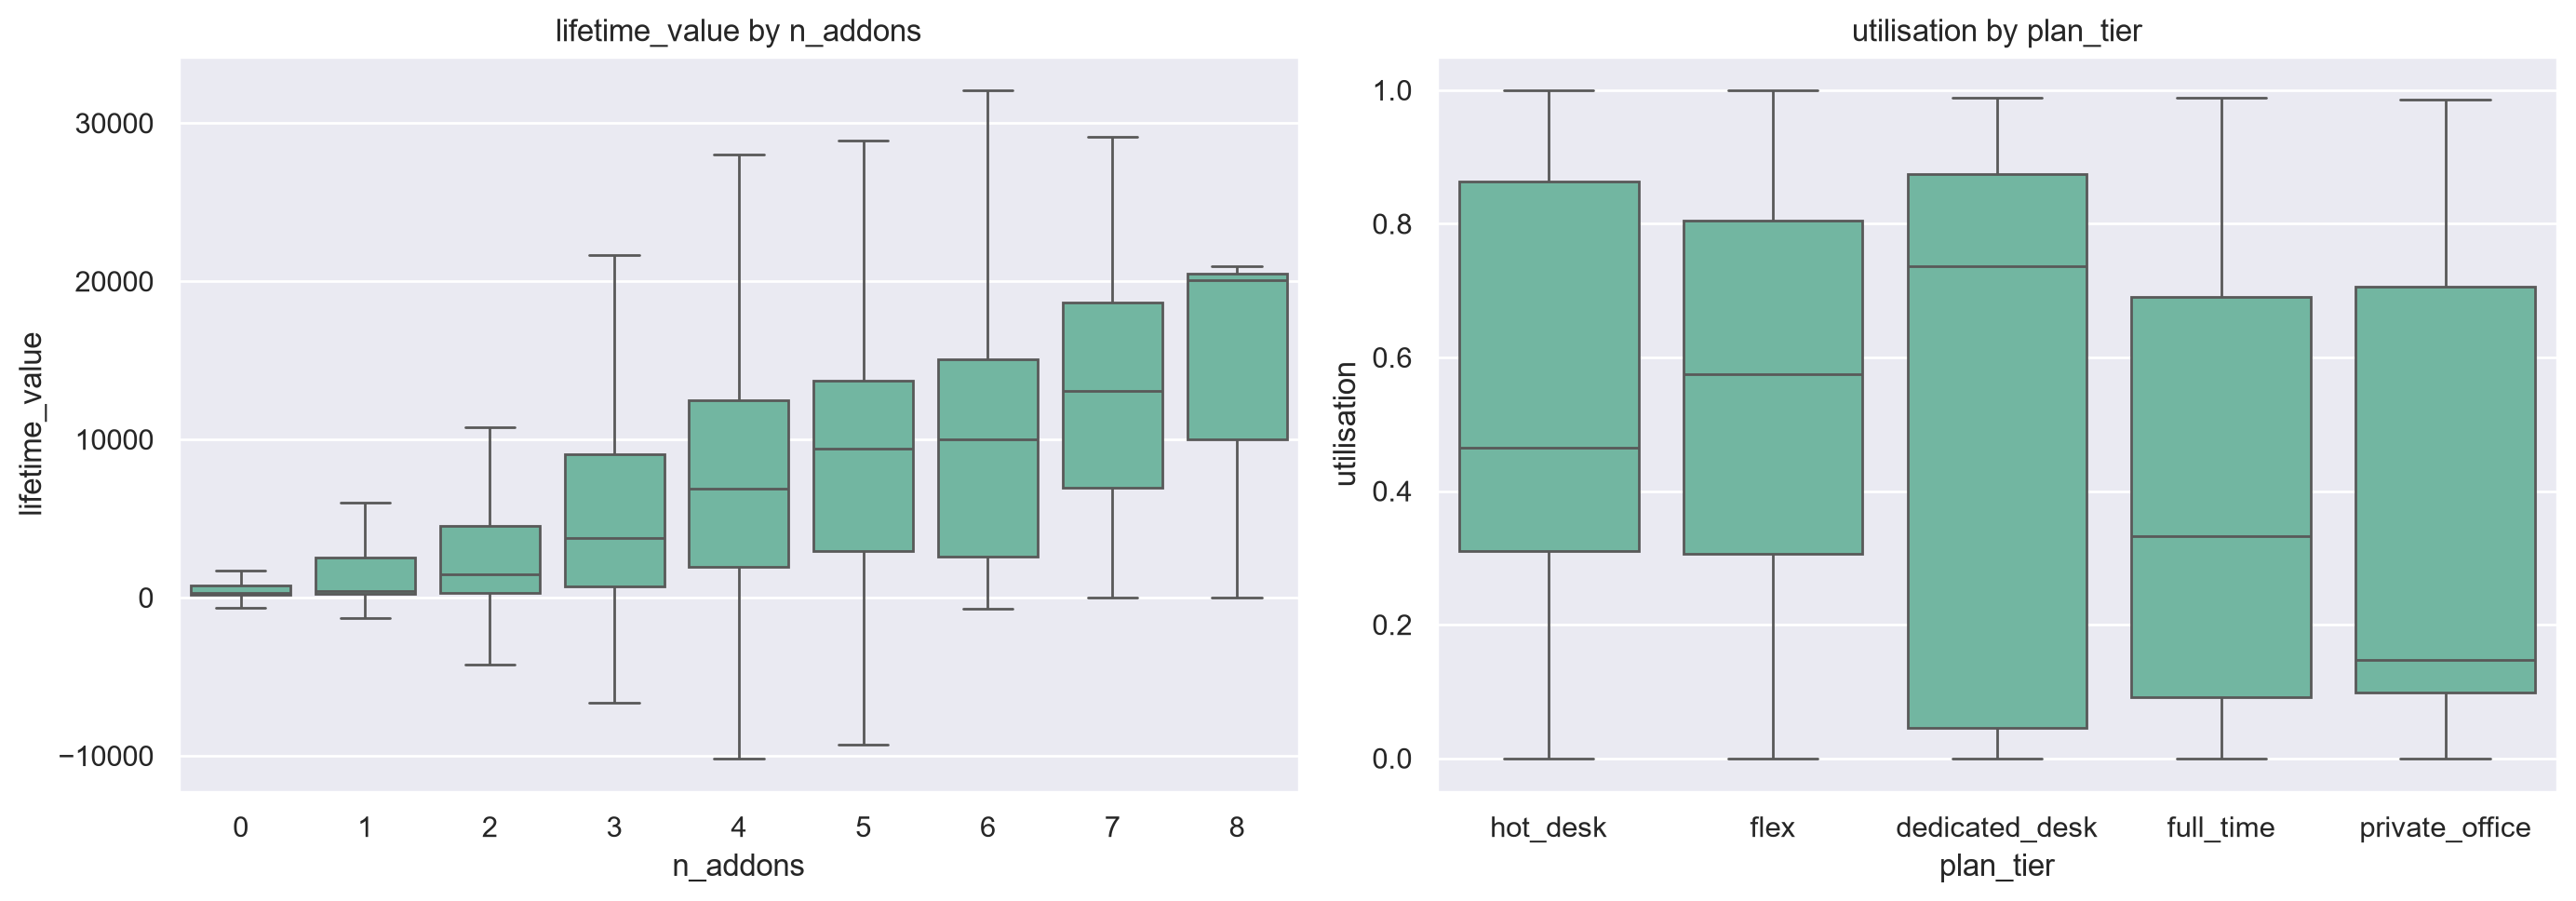

In [106]:
order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), tight_layout=True)
sns.boxplot(data=df_eda, x="n_addons", y="lifetime_value", showfliers=False, ax=axes[0])
axes[0].set_title("lifetime_value by n_addons")
sns.boxplot(data=df_eda, x="plan_tier", y="utilisation", order=order, ax=axes[1])
axes[1].set_title("utilisation by plan_tier")
plt.show()

Median `lifetime_value` grows with the number of add-ons (317 euros with 0, 20,047 euros with 8, but this last value is based on only 3 members). Median `utilisation` goes from 0.74 (`dedicated_desk`) to 0.15 (`private_office`), so plan tier separates how much members use the space. In the first plot outliers are hidden (`showfliers=False`) for readability.

In [107]:
# Median value per month and utilisation by plan (numbers used in the Task 3 summary)
df_eda.groupby("plan_tier")[["ltv_per_month", "utilisation"]].median().reindex(PLAN_ORDER).round(2)

,ltv_per_month,utilisation
plan_tier,,
hot_desk,129.17,0.46
flex,197.07,0.57
dedicated_desk,394.02,0.74
full_time,304.92,0.33
private_office,698.07,0.15


## 2. Bonus: Multidimensional Outlier & Anomaly Detection

The previous IQR analysis detected extreme values in individual features. Unusual customer behavior isn't always visible in a single feature. A customer may visit frequently and use many add-ons but generate very little revenue.

These unusual profiles can distort clustering. Extreme values may shift cluster centers or create small clusters that mainly contain outliers. As a result, typical customer groups may become harder to identify.

We use Isolation Forest to detect these profiles before clustering, so that we can decide whether to keep them, investigate them separately, or reduce their influence on the final customer segments.

In [108]:

# Select features for multidimensional anomaly detection
anomaly_features = [
    "tenure_months",
    "avg_weekly_visits",
    "utilisation",
    "n_addons",
    "lifetime_value"
]

# Create a separate dataset without changing the original data
X_anomaly = df_eda[anomaly_features].copy()

# Check missing and infinite values
X_anomaly = X_anomaly.replace([np.inf, -np.inf], np.nan)

print("Dataset shape:", X_anomaly.shape)
print("\nMissing values:")
print(X_anomaly.isna().sum())

print("\nDescriptive statistics:")
display(X_anomaly.describe().T)


Dataset shape: (15450, 5)

Missing values:
tenure_months         152
avg_weekly_visits       0
utilisation            10
n_addons                0
lifetime_value       1040
dtype: int64

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
tenure_months,15298.00,12.31,11.13,0.07,2.14,9.28,20.93,35.97
avg_weekly_visits,15450.00,1.78,1.94,0.00,0.71,1.42,2.41,47.40
utilisation,15440.00,0.52,0.31,0.00,0.24,0.52,0.80,1.00
n_addons,15450.00,1.82,1.50,0.00,1.00,1.00,3.00,8.00
lifetime_value,14410.00,6398.77,62789.64,-13440.24,252.73,825.12,5057.34,3371260.00


In [109]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
import numpy as np
import pandas as pd

# Keep original values unchanged
X_prepared = X_anomaly.copy()

# Transform highly skewed non-negative magnitude,
# while preserving the sign of negative LTV values
X_prepared["lifetime_value"] = (
    np.sign(X_prepared["lifetime_value"])
    * np.log1p(np.abs(X_prepared["lifetime_value"]))
)

# Median imputation for this exploratory bonus analysis only
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X_prepared),
    columns=anomaly_features,
    index=X_prepared.index
)

# Robust scaling
scaler = RobustScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_imputed),
    columns=anomaly_features,
    index=X_prepared.index
)

print("Missing values after preparation:")
print(X_scaled.isna().sum())

print("\nPrepared dataset shape:", X_scaled.shape)

display(X_scaled.describe().round(2).T)


Missing values after preparation:
tenure_months        0
avg_weekly_visits    0
utilisation          0
n_addons             0
lifetime_value       0
dtype: int64

Prepared dataset shape: (15450, 5)


,count,mean,std,min,25%,50%,75%,max
tenure_months,15450.00,0.16,0.59,-0.49,-0.38,0.00,0.62,1.43
avg_weekly_visits,15450.00,0.21,1.14,-0.84,-0.42,0.00,0.58,27.05
utilisation,15450.00,-0.00,0.55,-0.92,-0.49,0.00,0.51,0.85
n_addons,15450.00,0.41,0.75,-0.50,0.00,0.00,1.00,3.50
lifetime_value,15450.00,-0.12,1.03,-5.74,-0.39,0.00,0.61,2.94


In [110]:

from sklearn.ensemble import IsolationForest

# Multidimensional anomaly detection
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42
)

# Fit model and identify anomalies
anomaly_predictions = iso_forest.fit_predict(X_scaled)

# Save results in a separate analysis dataframe
anomaly_results = df_eda.copy()
anomaly_results["anomaly_flag"] = anomaly_predictions
anomaly_results["is_anomaly"] = anomaly_predictions == -1

# Summary
print("Anomaly detection results:")
print(anomaly_results["is_anomaly"].value_counts())

print("\nAnomaly percentage:")
print(
    (anomaly_results["is_anomaly"].mean() * 100).round(2)
)


Anomaly detection results:
is_anomaly
False    14986
True       464
Name: count, dtype: int64

Anomaly percentage:
3.0


In [111]:

# Compare typical customer characteristics
comparison = (
    anomaly_results
    .groupby("is_anomaly")[anomaly_features]
    .median()
    .T
)

comparison.columns = ["Normal customers", "Anomalous customers"]

display(comparison.round(2))

# Inspect the most unusual customer profiles
anomaly_results["anomaly_score"] = iso_forest.decision_function(X_scaled)

most_unusual = (
    anomaly_results
    .loc[anomaly_results["is_anomaly"]]
    .sort_values("anomaly_score")
)

display(
    most_unusual[
        ["member_id"] + anomaly_features + ["anomaly_score"]
    ].head(10).round(2)
)


,Normal customers,Anomalous customers
tenure_months,8.77,29.20
avg_weekly_visits,1.39,3.82
utilisation,0.52,0.69
n_addons,1.00,5.00
lifetime_value,901.30,0.00


,member_id,tenure_months,avg_weekly_visits,utilisation,n_addons,lifetime_value,anomaly_score
9636,CW009369,35.97,44.50,0.94,4,0.00,-0.11
9625,CW009358,1.41,4.52,0.96,6,-684.63,-0.10
13631,CW013233,6.54,27.70,0.80,1,-515.02,-0.10
11999,CW011653,20.07,43.20,0.71,5,0.00,-0.09
7327,CW007130,35.97,4.73,0.99,6,0.00,-0.09
14768,CW014340,28.91,38.80,0.92,5,1290001.00,-0.09
9319,CW009060,35.97,6.10,0.95,5,0.00,-0.09
5945,CW005781,35.87,4.16,0.78,7,0.00,-0.09
85,CW000083,32.29,4.67,0.99,6,0.00,-0.08
13438,CW013043,35.97,3.60,0.62,6,0.00,-0.08


In [112]:

# Examine LTV data quality among detected anomalies
ltv_quality = anomaly_results.groupby("is_anomaly").agg(
    customers=("member_id", "count"),
    missing_ltv=("lifetime_value", lambda x: x.isna().sum()),
    zero_ltv=("lifetime_value", lambda x: (x == 0).sum()),
    negative_ltv=("lifetime_value", lambda x: (x < 0).sum())
)

for col in ["missing_ltv", "zero_ltv", "negative_ltv"]:
    ltv_quality[col + "_pct"] = (
        ltv_quality[col] / ltv_quality["customers"] * 100
    ).round(2)

display(ltv_quality)


,customers,missing_ltv,zero_ltv,negative_ltv,missing_ltv_pct,zero_ltv_pct,negative_ltv_pct
is_anomaly,,,,,,,
False,14986,1015,1495,38,6.77,9.98,0.25
True,464,25,247,44,5.39,53.23,9.48


In [113]:

# Sensitivity analysis: anomaly detection without lifetime_value
behavior_features = [
    "tenure_months",
    "avg_weekly_visits",
    "utilisation",
    "n_addons"
]

X_behavior = X_scaled[behavior_features].copy()

behavior_model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42
)

behavior_predictions = behavior_model.fit_predict(X_behavior)

# Compare anomaly detection results
anomaly_results["behavior_anomaly"] = behavior_predictions == -1

original_anomalies = anomaly_results["is_anomaly"]
behavior_anomalies = anomaly_results["behavior_anomaly"]

overlap = (original_anomalies & behavior_anomalies).sum()

print("Original anomalies:", original_anomalies.sum())
print("Behavior-only anomalies:", behavior_anomalies.sum())
print("Detected by both models:", overlap)

print(
    "Share of original anomalies also detected without LTV:",
    round(overlap / original_anomalies.sum() * 100, 2),
    "%"
)


Original anomalies: 464
Behavior-only anomalies: 464
Detected by both models: 217
Share of original anomalies also detected without LTV: 46.77 %


In [114]:
anomaly_results["anomaly_group"] = np.select(
    [
        original_anomalies & behavior_anomalies,
        original_anomalies & ~behavior_anomalies,
        ~original_anomalies & behavior_anomalies
    ],
    [
        "Both models",
        "LTV model only",
        "Behavior model only"
    ],
    default="Neither model"
)

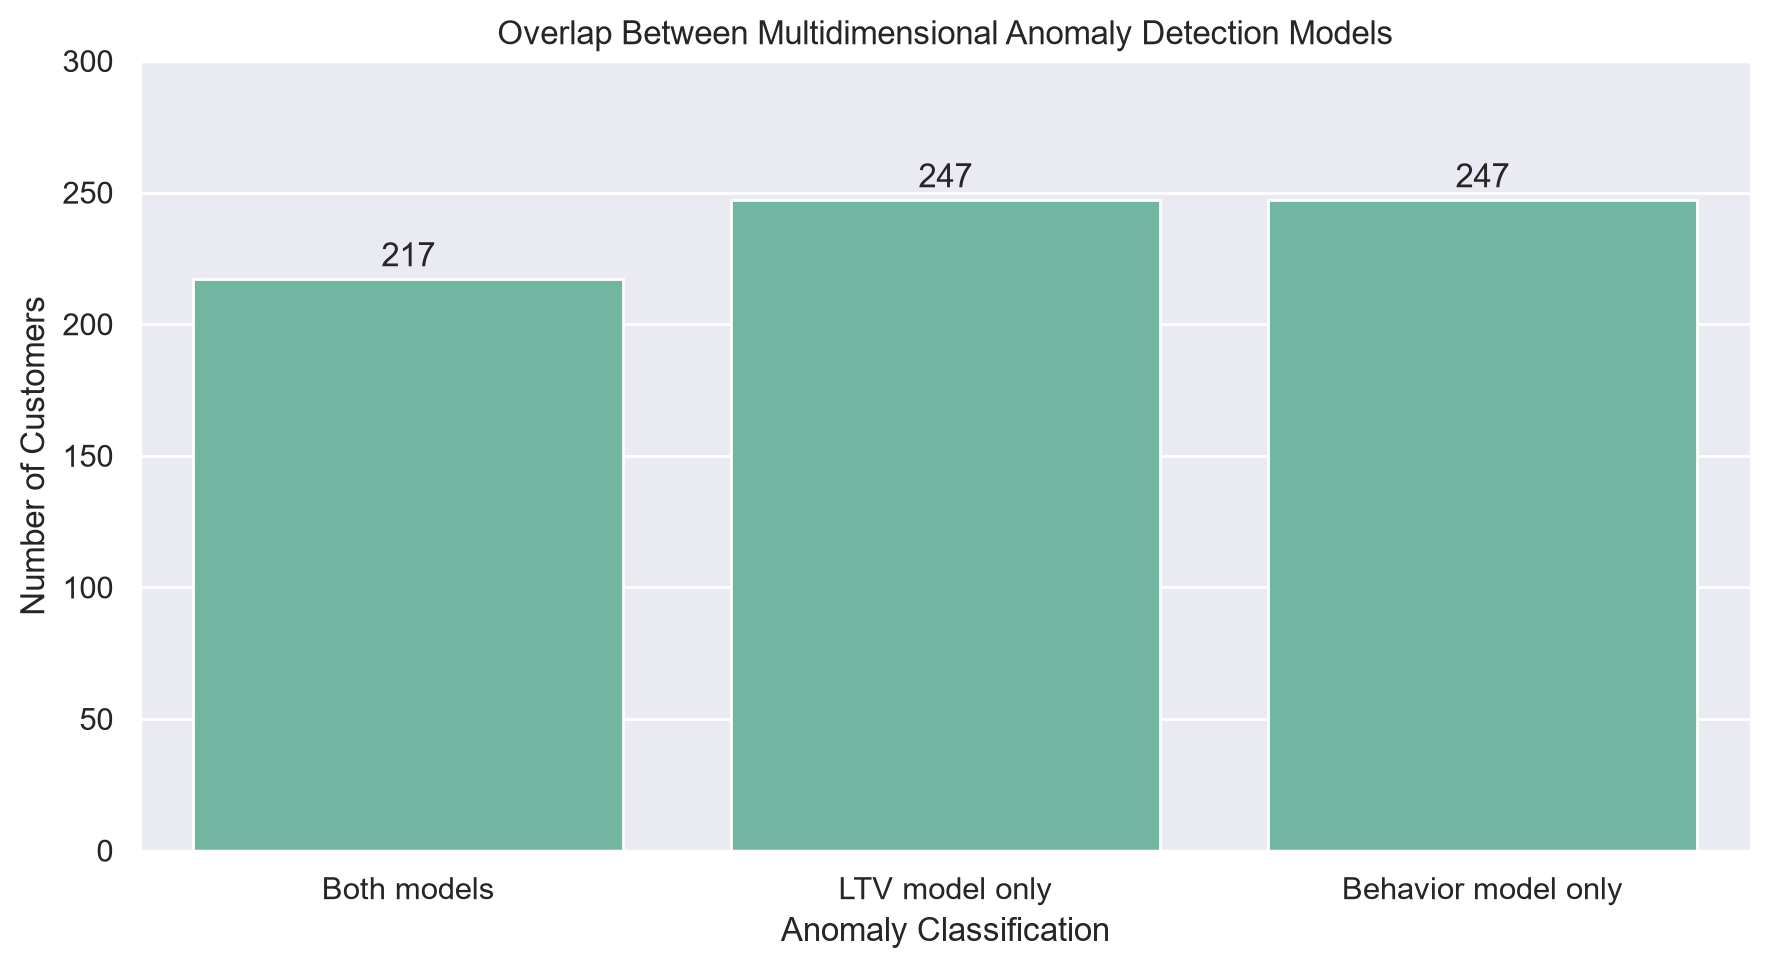

In [115]:

# Visualize agreement among detected anomalies only
order = [
    "Both models",
    "LTV model only",
    "Behavior model only"
]

counts = (
    anomaly_results["anomaly_group"]
    .value_counts()
    .reindex(order)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=counts.index,
    y=counts.values
)

for i, value in enumerate(counts.values):
    ax.text(i, value + 5, str(value), ha="center")

plt.title("Overlap Between Multidimensional Anomaly Detection Models")
plt.xlabel("Anomaly Classification")
plt.ylabel("Number of Customers")
plt.ylim(0, 300)
plt.tight_layout()
plt.show()



### Insights: anomaly detection
- Isolation Forest flagged 464 of the 15,450 members (3%) as anomalies.
- Compared with the other members, they stay longer (median 29 vs 9 months), visit more often (3.8 vs 1.4 times per week) and use more add-ons (5 vs 1), but 53% of them have a lifetime value of 0 and 9.5% a negative one. High activity with no revenue looks more like a data problem than a real type of customer.
- Without `lifetime_value`, the model finds only 217 of the same 464 members (47%), so the result depends a lot on the variables we choose.
- **For clustering:** we shouldn't just delete them. Members with impossible values (zero or negative value with high activity) should be corrected or excluded once the error is confirmed; members with real but extreme behavior can be kept with less weight (robust scaling or capping); the rest can be analyzed separately as a possible small segment. We will compare the clusters with and without them.
- **Limits:** the 3% was chosen by us, so it doesn't mean that 3% of the members have wrong data. Missing values were filled with the median only for this analysis.

# Part 4: Summaries

## Summary for task 1

**Distributions.** Most usage and value variables are strongly right-skewed with many zeros (89% for `event_space_hours`, 76% for `guest_passes_issued`, 60% for `meeting_room_hours`), and the zeros are real non-users. `age` is the only roughly symmetric variable. `plan_days_per_week` and `entitled_visits_last_period` take only a few values, and `days_since_last_visit` has a second group around 1,000 days that looks like a code. The plans are unbalanced (`flex` and `hot_desk` are about 69% of the members, `private_office` 4%) and 68% of the members are in Portugal.

**Anomalies** (detailed in the sections above). About 26% of `membership_end` values are the placeholder 1970-01-01. Impossible values (negative counts, ages below 16 or above 90, more than 7 plan days per week, more visits than days in the data) and extreme outliers in `lifetime_value`, `meeting_room_hours` and the visit variables appear in **all** plans, which points to data errors and not to real VIP customers. `n_colleagues_on_account = -1` and `days_since_last_visit` around 999 look like codes for "unknown". The identified anomalies weren't corrected in the original dataset during this exploratory analysis. Selected values were set to missing in a separate working copy (`eda`) for visualization purposes only. The treatment of these anomalies will be addressed in the data preparation stage.

**Trends.** New memberships fall from 7,626 (2021) to 4,449 (2022) and 3,375 (2023), with a spike on the first day of the data and a sharp rise in the last three months. The plan mix moves towards the cheaper plans (`hot_desk` from 26% to 47%). The share of members still without an end date is much higher in the heavier plans (57% for `dedicated_desk`, 13% for `hot_desk`). Active members have a longer tenure (median 19 vs. 8 months), but they don't visit recently (median 26 days, 25% above 198 days), so "active" is doubtful.

**Relationships.** Value, tenure, renewals and add-ons grow with the plan, but not in the order of the metadata (`dedicated_desk` is above `full_time`). `private_office` pays the most and uses the least (utilization 0.15), and about 25% of all members use less than a quarter of their plan. The plan explains only 4% of the variation of utilization and 17% of the weekly visits. The number of add-ons goes with the value (317 euros with none, 9,412 euros with five). Teams and individuals are almost identical. The strongest correlations show groups of redundant variables (the visit variables among themselves, entitled visits and plan days, totals and tenure), and the key pairs show separate groups, a non-linear value over tenure, and the code 999, which appears at all levels of utilization.

**Variables most relevant for segmentation.** Value and commitment (`plan_tier`, `lifetime_value`, `n_renewals`), engagement (`avg_weekly_visits`, `utilisation`, `days_since_last_visit`) and service use (add-ons, `meeting_room_hours`). `gender`, `country`, `age`, `industry` and `is_team_account` look weak for building segments and are better for describing them (section 7). Redundant variables should be reduced to one per group.

**Missing values and features.** `meeting_room_hours` (8.4%), `guest_passes_issued` (8.2%), `lifetime_value` (6.7%) and `age` (3.6%) have the most empty cells, plus several hidden codes; no missing values were imputed in the main EDA. Median imputation was used only in the separate anomaly-detection analysis. We propose per-month versions of the totals, a recency flag, an under-user flag and a better encoding of `plan_tier` (section 9).

**Limitations.** (1) "Active" is an assumption based on the 1970 placeholder. (2) The period behind the hours variables isn't defined. (3) Zero in `lifetime_value` may mean "no revenue yet" or "unknown". (4) The thresholds used to hide extremes in plots (1,000 hours, 100,000 euros) are choices, not facts. (5) `utilisation` never exceeds 1, so it may be capped in the source.

## Summary for task 2: data quality and risks for the clustering

- **Placeholder end dates.** About 26% of members (3,954) have `membership_end` = 1970-01-01. We read it as "still active", but this is an assumption: if wrong, churned and active members would be mixed in the same groups.
- **Impossible values and extreme outliers** (negative counts, negative `lifetime_value`, more than 7 plan days or visits per week, ages out of range) appear in all plans. Distance-based methods such as k-means are very sensitive to them, so they could create tiny groups or pull the centroids.
- **Codes written as numbers** (`n_colleagues_on_account` = -1, `days_since_last_visit` around 999) would be read as real values by the algorithm if left untouched.
- **Redundant and skewed variables** (visits and plan days, totals and tenure) would give extra weight to the same information; the key pairs are reduced to one variable in D2.
- **Missing values.** No imputation was applied to the main EDA data. Median imputation was used only for the anomaly detection models. For D2, treatment will depend on the variable, the likely reason for missingness and sensitivity checks.


**Data preparation: current status**

We converted numeric and date formats, standardized categorical labels and removed 15 identical duplicate rows, leaving 15,450 unique members.

Missing values, inconsistent dates and suspicious extremes still require further treatment before clustering. Selected values were hidden in the plotting copy, and median imputation was used only for the anomaly detection models.

## Summary for task 3: customer types and expected number of clusters (hypotheses)

These are hypotheses from medians by plan tier, to be tested in D2.

- **Low-cost, flexible members** (`hot_desk`, `flex`): the lowest value per month (median 129 and 197 euros) and moderate use of the plan (utilization 0.46 and 0.57).
- **Heavy users of a dedicated desk** (`dedicated_desk`): the highest utilization (0.74) and a medium-high value per month (394 euros).
- **High-value, low-use offices** (`private_office`): the highest value per month (698 euros) but the lowest utilization (0.15).
- **Full-time members who pay for more than they use** (`full_time`): utilization 0.33 and value per month 305 euros.

The strongest differences are in value, commitment and utilization, so we expect roughly 3 to 5 clusters, to be confirmed with the clustering. Members on the same plan may differ in utilization, monthly revenue and service preferences. We will test whether these within-plan differences support additional or cross-plan segments.

## Summary for task 4: engineered features

We built five engineered features that describe behavior and not only size: `utilisation`, `n_addons`, `tenure_months`, `ltv_per_month` and `ltv_per_visit`. Utilization and the number of add-ons separate the plans (median utilization goes from 0.74 for `dedicated_desk` to 0.15 for `private_office`; median lifetime value from 317 euros with no add-ons to 20,047 euros with eight, although only 3 members have eight add-ons), so they should help the clustering. `ltv_per_month` and `ltv_per_visit` are extremely right-skewed and have 79 and 51 negative values that come from negative `lifetime_value`: they will need outlier treatment and scaling in D2. Two pairs of variables are at 0.9 or more in Pearson correlation (`actual_visits_last_period` and `avg_weekly_visits`, 0.94; `entitled_visits_last_period` and `plan_days_per_week`, 0.91), so one variable of each pair will be dropped in the feature selection. The features are a first version and may change in D2.